In [12]:
!pip install -q ultralytics opencv-python matplotlib pandas scikit-learn pyyaml

In [13]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [15]:
import os
import glob
import zipfile

# Find uploaded ZIP files
zip_files = glob.glob("/content/*.zip")

print("ZIP files found:", zip_files)

if len(zip_files) == 1:
    zip_path = zip_files[0]

    os.makedirs("/content/meat_dataset", exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/meat_dataset")

    print("Dataset extracted successfully!")

elif len(zip_files) == 0:
    print("No ZIP file found. Please upload your dataset.")

else:
    print("Multiple ZIP files found. Select the correct dataset.")

ZIP files found: ['/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip']


BadZipFile: File is not a zip file

In [16]:
import os
import glob
import zipfile

zip_files = glob.glob("/content/*.zip")

for file in zip_files:
    print("File:", os.path.basename(file))
    print("Size (MB):", round(os.path.getsize(file) / (1024 * 1024), 2))
    print("Valid ZIP:", zipfile.is_zipfile(file))

    with open(file, "rb") as f:
        print("File signature:", f.read(8))

File: Pork Rasher Error-Packaging-.v1i.yolov8.zip
Size (MB): 117.0
Valid ZIP: False
File signature: b'PK\x03\x04\x14\x00\x00\x08'


In [17]:
import os
import glob
import zipfile

# Find uploaded ZIP files
zip_files = glob.glob("/content/*.zip")

print("ZIP files found:", zip_files)

if len(zip_files) == 1:
    zip_path = zip_files[0]

    os.makedirs("/content/meat_dataset", exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/meat_dataset")

    print("Dataset extracted successfully!")

elif len(zip_files) == 0:
    print("No ZIP file found. Please upload your dataset.")

else:
    print("Multiple ZIP files found. Select the correct dataset.")

ZIP files found: ['/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip']


BadZipFile: File is not a zip file

In [10]:
import os

dataset_path = "/content/meat_dataset"

for root, dirs, files in os.walk(dataset_path):
    print(root, "| Files:", len(files))

In [11]:
import os
import yaml

dataset_path = "/content/meat_dataset"
yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as file:
    dataset_config = yaml.safe_load(file)

print("Dataset Configuration:")
print("----------------------")

print("Number of classes:", dataset_config.get("nc"))
print("Class names:", dataset_config.get("names"))

print("\nDataset paths:")
print("Training:", dataset_config.get("train"))
print("Validation:", dataset_config.get("val"))
print("Testing:", dataset_config.get("test"))

FileNotFoundError: [Errno 2] No such file or directory: '/content/meat_dataset/data.yaml'

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

dataset_path = "/content/meat_dataset"
image_dir = os.path.join(dataset_path, "train", "images")
label_dir = os.path.join(dataset_path, "train", "labels")

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

random.seed(42)
selected_images = random.sample(image_files, min(6, len(image_files)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, filename in zip(axes.flat, selected_images):

    image_path = os.path.join(image_dir, filename)
    label_path = os.path.join(
        label_dir,
        os.path.splitext(filename)[0] + ".txt"
    )

    image = cv2.imread(image_path)

    if image is None:
        ax.set_title("Unable to load image")
        ax.axis("off")
        continue

    height, width = image.shape[:2]
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    if os.path.exists(label_path):

        with open(label_path, "r") as file:

            for line in file:
                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id = int(values[0])
                x, y, w, h = map(float, values[1:])

                x1 = int((x - w / 2) * width)
                y1 = int((y - h / 2) * height)
                x2 = int((x + w / 2) * width)
                y2 = int((y + h / 2) * height)

                cv2.rectangle(
                    image,
                    (x1, y1),
                    (x2, y2),
                    (255, 0, 0),
                    2
                )

                cv2.putText(
                    image,
                    class_names[class_id],
                    (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 0, 0),
                    2
                )

    ax.imshow(image)
    ax.set_title(filename[:25])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

dataset_path = Path("/content/meat_dataset")

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

splits = ["train", "valid", "test"]
results = {}

for split in splits:
    counts = Counter()
    label_folder = dataset_path / split / "labels"

    for label_file in label_folder.glob("*.txt"):
        with open(label_file, "r") as file:
            for line in file:
                values = line.strip().split()

                if values:
                    class_id = int(values[0])
                    counts[class_id] += 1

    results[split] = counts

print("DEFECT DISTRIBUTION")
print("-" * 65)

print(f"{'Defect':<20} {'Train':>10} {'Valid':>10} {'Test':>10}")

for class_id, name in enumerate(class_names):
    print(
        f"{name:<20} "
        f"{results['train'][class_id]:>10} "
        f"{results['valid'][class_id]:>10} "
        f"{results['test'][class_id]:>10}"
    )

# Plot training-set defect distribution
train_counts = [
    results["train"][i]
    for i in range(len(class_names))
]

plt.figure(figsize=(10, 5))
plt.bar(class_names, train_counts)

plt.xlabel("Defect Category")
plt.ylabel("Number of Annotations")
plt.title("Training Dataset — Defect Distribution")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from collections import Counter

dataset_path = Path("/content/meat_dataset")

splits = ["train", "valid", "test"]
num_classes = 5

for split in splits:

    image_dir = dataset_path / split / "images"
    label_dir = dataset_path / split / "labels"

    image_files = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    missing_labels = []
    invalid_annotations = []
    empty_labels = 0
    total_boxes = 0

    for image_path in image_files:

        label_path = label_dir / (image_path.stem + ".txt")

        if not label_path.exists():
            missing_labels.append(image_path.name)
            continue

        lines = label_path.read_text().splitlines()

        if not lines:
            empty_labels += 1

        for line_number, line in enumerate(lines, 1):

            values = line.split()

            try:
                if len(values) != 5:
                    raise ValueError("Incorrect number of values")

                class_value = float(values[0])
                class_id = int(class_value)

                if class_value != class_id:
                    raise ValueError("Class ID is not an integer")

                x, y, w, h = map(float, values[1:])

                if not (0 <= class_id < num_classes):
                    raise ValueError("Invalid class ID")

                if not (
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1
                ):
                    raise ValueError("Invalid bounding box values")

                if not (
                    x - w / 2 >= -1e-6 and
                    x + w / 2 <= 1 + 1e-6 and
                    y - h / 2 >= -1e-6 and
                    y + h / 2 <= 1 + 1e-6
                ):
                    raise ValueError("Bounding box exceeds image")

                total_boxes += 1

            except (ValueError, TypeError) as error:
                invalid_annotations.append(
                    (label_path.name, line_number, str(error))
                )

    print(f"\n{split.upper()} DATASET")
    print("-" * 35)
    print("Images:", len(image_files))
    print("Missing label files:", len(missing_labels))
    print("Empty label files:", empty_labels)
    print("Valid bounding boxes:", total_boxes)
    print("Invalid annotations:", len(invalid_annotations))

    if invalid_annotations:
        print("Examples:", invalid_annotations[:5])

In [ ]:
from pathlib import Path

label_dir = Path("/content/meat_dataset/train/labels")

print("CHECKING NON-STANDARD ANNOTATIONS")
print("-" * 60)

for label_file in label_dir.glob("*.txt"):

    with open(label_file, "r") as file:
        lines = file.readlines()

    for line_number, line in enumerate(lines, 1):

        values = line.strip().split()

        if values and len(values) != 5:

            print("\nFile:", label_file.name)
            print("Line:", line_number)
            print("Number of values:", len(values))
            print("Annotation:", line.strip())

In [ ]:
from pathlib import Path
import math

dataset_path = Path("/content/meat_dataset")

for split in ["train", "valid", "test"]:
    label_dir = dataset_path / split / "labels"

    valid_boxes = 0
    invalid_boxes = 0

    for label_file in label_dir.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            values = line.split()

            try:
                if len(values) != 5:
                    raise ValueError("Incorrect number of values")

                class_id = float(values[0])
                x, y, w, h = map(float, values[1:])

                if not all(math.isfinite(v) for v in [class_id, x, y, w, h]):
                    raise ValueError("Non-finite value")

                if class_id != int(class_id) or not 0 <= class_id < 5:
                    raise ValueError("Invalid class")

                if not (
                    0 <= x <= 1 and 0 <= y <= 1
                    and 0 < w <= 1 and 0 < h <= 1
                    and x - w/2 >= -1e-6
                    and x + w/2 <= 1 + 1e-6
                    and y - h/2 >= -1e-6
                    and y + h/2 <= 1 + 1e-6
                ):
                    raise ValueError("Invalid coordinates")

                valid_boxes += 1

            except ValueError:
                invalid_boxes += 1
                print("Invalid:", label_file.name, "|", line)

    print(f"{split.upper()}: {valid_boxes} valid boxes, {invalid_boxes} invalid boxes")

In [ ]:
from pathlib import Path

dataset = Path("/content/meat_dataset")
backup = Path("/content/original_train_labels")

print("Dataset exists:", dataset.exists())
print("Original label backup exists:", backup.exists())

for split in ["train", "valid", "test"]:
    images = list((dataset / split / "images").glob("*"))
    labels = list((dataset / split / "labels").glob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} labels")

In [ ]:
from pathlib import Path

original = Path("/content/original_train_labels")
current = Path("/content/meat_dataset/train/labels")

changed_files = []

for file in current.glob("*.txt"):
    backup_file = original / file.name

    if backup_file.exists():
        if file.read_bytes() != backup_file.read_bytes():
            changed_files.append(file.name)

print("Number of modified annotation files:", len(changed_files))

print("\nModified files:")
for name in changed_files[:20]:
    print(name)

In [ ]:
from pathlib import Path

original = Path("/content/original_train_labels")
current = Path("/content/meat_dataset/train/labels")

actual_changes = []

for file in current.glob("*.txt"):

    backup_file = original / file.name

    if not backup_file.exists():
        continue

    old_lines = [
        line.split()
        for line in backup_file.read_text().splitlines()
        if line.strip()
    ]

    new_lines = [
        line.split()
        for line in file.read_text().splitlines()
        if line.strip()
    ]

    if old_lines != new_lines:
        actual_changes.append(file.name)

print("Files with actual annotation changes:", len(actual_changes))

print("\nChanged files:")
for name in actual_changes:
    print(name)

In [ ]:
from pathlib import Path
import math

dataset_path = Path("/content/meat_dataset")

for split in ["train", "valid", "test"]:

    label_dir = dataset_path / split / "labels"

    valid_boxes = 0
    invalid_boxes = 0

    for label_file in label_dir.glob("*.txt"):

        for line in label_file.read_text().splitlines():

            values = line.split()

            try:
                if len(values) != 5:
                    raise ValueError("Incorrect number of values")

                class_id, x, y, w, h = map(float, values)

                if not all(math.isfinite(v) for v in [class_id, x, y, w, h]):
                    raise ValueError("Non-finite value")

                if class_id != int(class_id) or not 0 <= class_id < 5:
                    raise ValueError("Invalid class ID")

                if not (
                    0 <= x <= 1
                    and 0 <= y <= 1
                    and 0 < w <= 1
                    and 0 < h <= 1
                    and x - w / 2 >= -1e-6
                    and x + w / 2 <= 1 + 1e-6
                    and y - h / 2 >= -1e-6
                    and y + h / 2 <= 1 + 1e-6
                ):
                    raise ValueError("Invalid coordinates")

                valid_boxes += 1

            except ValueError as error:
                invalid_boxes += 1
                print("Invalid:", label_file.name, error)

    print(
        f"{split.upper()}: "
        f"{valid_boxes} valid boxes, "
        f"{invalid_boxes} invalid boxes"
    )

In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib

dataset_path = Path("/content/meat_dataset")

splits = ["train", "valid", "test"]

hashes = defaultdict(list)

for split in splits:

    image_dir = dataset_path / split / "images"

    for image_path in image_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        with open(image_path, "rb") as file:
            image_hash = hashlib.sha256(file.read()).hexdigest()

        hashes[image_hash].append((split, image_path.name))

duplicate_groups = [
    files for files in hashes.values()
    if len({split for split, name in files}) > 1
]

print("DATASET DUPLICATE CHECK")
print("-" * 45)

print("Total images:", sum(
    len(list((dataset_path / split / "images").glob("*")))
    for split in splits
))

print("Duplicate groups across dataset splits:", len(duplicate_groups))

print("\nExamples of duplicates:")

for group in duplicate_groups[:10]:
    print(group)

In [ ]:
!pip install -q imagehash pillow

In [ ]:
from pathlib import Path
from PIL import Image
import imagehash
from collections import defaultdict

dataset_path = Path("/content/meat_dataset")

splits = ["train", "valid", "test"]

image_data = []

for split in splits:

    image_dir = dataset_path / split / "images"

    for image_path in image_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            with Image.open(image_path) as img:
                phash = imagehash.phash(img)

            image_data.append({
                "split": split,
                "filename": image_path.name,
                "hash": phash
            })

        except Exception as error:
            print("Error reading:", image_path.name, error)

print("Images analysed:", len(image_data))

# Compare images belonging to different dataset splits
threshold = 5

similar_pairs = []

for i in range(len(image_data)):

    for j in range(i + 1, len(image_data)):

        image1 = image_data[i]
        image2 = image_data[j]

        if image1["split"] == image2["split"]:
            continue

        distance = image1["hash"] - image2["hash"]

        if distance <= threshold:

            similar_pairs.append({
                "image1": image1["filename"],
                "split1": image1["split"],
                "image2": image2["filename"],
                "split2": image2["split"],
                "distance": distance
            })

print("\nNEAR-DUPLICATE CHECK")
print("-" * 50)

print("Potentially similar image pairs:", len(similar_pairs))

print("\nFirst 10 similar pairs:")

for pair in similar_pairs[:10]:
    print(pair)

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

dataset_path = Path("/content/meat_dataset")

# Sort the detected pairs by similarity
sorted_pairs = sorted(
    similar_pairs,
    key=lambda x: x["distance"]
)

# Display the 6 most similar pairs
selected_pairs = sorted_pairs[:6]

if not selected_pairs:
    print("No similar pairs available to display.")

else:
    fig, axes = plt.subplots(
        len(selected_pairs),
        2,
        figsize=(12, 4 * len(selected_pairs)),
        squeeze=False
    )

    for i, pair in enumerate(selected_pairs):

        image1_path = (
            dataset_path /
            pair["split1"] /
            "images" /
            pair["image1"]
        )

        image2_path = (
            dataset_path /
            pair["split2"] /
            "images" /
            pair["image2"]
        )

        with Image.open(image1_path) as img:
            image1 = img.convert("RGB").copy()

        with Image.open(image2_path) as img:
            image2 = img.convert("RGB").copy()

        axes[i, 0].imshow(image1)
        axes[i, 0].set_title(
            f"{pair['split1'].upper()} — Image 1"
        )
        axes[i, 0].axis("off")

        axes[i, 1].imshow(image2)
        axes[i, 1].set_title(
            f"{pair['split2'].upper()} — Image 2\n"
            f"pHash distance: {pair['distance']}"
        )
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
import re
from collections import Counter

def extract_frame_number(filename):
    match = re.search(r"frame_with_red_(\d+)", filename)
    return int(match.group(1)) if match else None

frame_differences = []

for pair in similar_pairs:

    frame1 = extract_frame_number(pair["image1"])
    frame2 = extract_frame_number(pair["image2"])

    if frame1 is not None and frame2 is not None:
        frame_differences.append(abs(frame1 - frame2))

print("FRAME NUMBER ANALYSIS")
print("-" * 45)

print("Similar pairs analysed:", len(frame_differences))

for threshold in [1, 5, 10, 20, 50, 100]:
    count = sum(
        difference <= threshold
        for difference in frame_differences
    )

    print(f"Frame difference <= {threshold}: {count}")

print("\nMinimum frame difference:",
      min(frame_differences) if frame_differences else "N/A")

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

dataset_path = Path("/content/meat_dataset")

# Select visually similar images with nearby frame numbers
close_pairs = []

for pair in similar_pairs:

    frame1 = extract_frame_number(pair["image1"])
    frame2 = extract_frame_number(pair["image2"])

    if frame1 is None or frame2 is None:
        continue

    frame_difference = abs(frame1 - frame2)

    if frame_difference <= 5:

        close_pairs.append({
            **pair,
            "frame_difference": frame_difference
        })

# Sort by frame-number difference, then perceptual similarity
close_pairs = sorted(
    close_pairs,
    key=lambda x: (x["frame_difference"], x["distance"])
)

print("Similar pairs within 5 frames:", len(close_pairs))

# Display the first six pairs
selected_pairs = close_pairs[:6]

if not selected_pairs:
    print("No nearby similar pairs found.")

else:
    fig, axes = plt.subplots(
        len(selected_pairs),
        2,
        figsize=(12, 4 * len(selected_pairs)),
        squeeze=False
    )

    for i, pair in enumerate(selected_pairs):

        path1 = (
            dataset_path /
            pair["split1"] /
            "images" /
            pair["image1"]
        )

        path2 = (
            dataset_path /
            pair["split2"] /
            "images" /
            pair["image2"]
        )

        with Image.open(path1) as img:
            image1 = img.convert("RGB").copy()

        with Image.open(path2) as img:
            image2 = img.convert("RGB").copy()

        axes[i, 0].imshow(image1)
        axes[i, 0].set_title(
            f"{pair['split1'].upper()} | "
            f"Frame {extract_frame_number(pair['image1'])}"
        )
        axes[i, 0].axis("off")

        axes[i, 1].imshow(image2)
        axes[i, 1].set_title(
            f"{pair['split2'].upper()} | "
            f"Frame {extract_frame_number(pair['image2'])}\n"
            f"Frame difference: {pair['frame_difference']} | "
            f"pHash: {pair['distance']}"
        )
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
from pathlib import Path
from collections import defaultdict
import re

dataset_path = Path("/content/meat_dataset")

splits = ["train", "valid", "test"]
frame_data = defaultdict(list)
frame_to_splits = defaultdict(set)

for split in splits:
    image_dir = dataset_path / split / "images"

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        match = re.search(
            r"frame_with_red_(\d+)",
            image_path.name
        )

        if match:
            frame_number = int(match.group(1))

            frame_data[split].append(frame_number)
            frame_to_splits[frame_number].add(split)

print("FRAME NUMBER DISTRIBUTION")
print("-" * 55)

for split in splits:
    numbers = frame_data[split]

    print(f"\n{split.upper()}")
    print("Images with frame numbers:", len(numbers))

    if numbers:
        print("Minimum frame number:", min(numbers))
        print("Maximum frame number:", max(numbers))
        print("Unique frame numbers:", len(set(numbers)))

shared_frames = {
    number: split_set
    for number, split_set in frame_to_splits.items()
    if len(split_set) > 1
}

print("\nFrame numbers appearing across multiple splits:",
      len(shared_frames))

print("\nFirst 10 examples:")
for number, split_set in list(shared_frames.items())[:10]:
    print(number, sorted(split_set))

In [ ]:
from pathlib import Path
from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt
import re

dataset_path = Path("/content/meat_dataset")

frame_images = defaultdict(list)

# Collect images and their frame numbers
for split in ["train", "valid", "test"]:

    image_dir = dataset_path / split / "images"

    for image_path in image_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        match = re.search(
            r"frame_with_red_(\d+)",
            image_path.name
        )

        if match:
            frame_number = int(match.group(1))

            frame_images[frame_number].append({
                "split": split,
                "path": image_path
            })

# Find frame numbers appearing in different splits
shared_frames = {}

for frame_number, images in frame_images.items():

    split_names = set(
        image["split"] for image in images
    )

    if len(split_names) > 1:
        shared_frames[frame_number] = images

print("Shared frame numbers:", len(shared_frames))

# Display five examples
selected_frames = list(shared_frames.items())[:5]

for frame_number, images in selected_frames:

    fig, axes = plt.subplots(
        1,
        len(images),
        figsize=(5 * len(images), 4),
        squeeze=False
    )

    for j, image_info in enumerate(images):

        with Image.open(image_info["path"]) as img:
            image = img.convert("RGB").copy()

        axes[0, j].imshow(image)

        axes[0, j].set_title(
            f"Frame {frame_number}\n"
            f"{image_info['split'].upper()}"
        )

        axes[0, j].axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
import os
import yaml

dataset_path = "/content/meat_dataset"

config = {
    "path": dataset_path,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": [
        "loose-meat",
        "packaging-error",
        "twisted-meat",
        "unsealed",
        "wrinkle"
    ]
}

yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "w") as file:
    yaml.safe_dump(config, file, sort_keys=False)

print("Dataset configuration saved successfully!")
print("Configuration path:", yaml_path)

with open(yaml_path, "r") as file:
    print("\n", file.read())

In [ ]:
from ultralytics import YOLO

# Load a pretrained YOLO11 Nano detection model
model = YOLO("yolo11n.pt")

# Display model information
model.info()

print("\nYOLO11 Nano model loaded successfully!")

In [ ]:
from ultralytics import YOLO

# Load pretrained model
model = YOLO("yolo11n.pt")

# Train the model
results = model.train(
    data="/content/meat_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    patience=15,
    optimizer="auto",
    project="/content/runs",
    name="meat_quality_baseline",
    exist_ok=False,
    seed=42,
    plots=True
)

print("Training completed successfully!")

In [ ]:
import os
import glob
from IPython.display import display, Image

# Find training results
run_dirs = glob.glob("/content/runs/meat_quality_baseline*")

print("Training folders found:", run_dirs)

if run_dirs:

    latest_run = max(run_dirs, key=os.path.getmtime)

    print("Using training folder:", latest_run)

    results_path = os.path.join(latest_run, "results.png")

    if os.path.exists(results_path):

        display(Image(filename=results_path, width=1200))

    else:
        print("Training results graph not found.")

else:
    print("No training folder found.")

In [ ]:
from google.colab import drive
import os
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Locate trained model
model_folder = "/content/runs/meat_quality_baseline/weights"

best_model = os.path.join(model_folder, "best.pt")
last_model = os.path.join(model_folder, "last.pt")

# Create permanent project folder
backup_folder = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

os.makedirs(backup_folder, exist_ok=True)

# Save trained weights
if os.path.exists(best_model):
    shutil.copy2(
        best_model,
        os.path.join(backup_folder, "baseline_best.pt")
    )
    print("Best model saved successfully!")
else:
    print("Best model not found.")

if os.path.exists(last_model):
    shutil.copy2(
        last_model,
        os.path.join(backup_folder, "baseline_last.pt")
    )
    print("Last model saved successfully!")
else:
    print("Last model not found.")

# Save training results
results_file = "/content/runs/meat_quality_baseline/results.csv"

if os.path.exists(results_file):
    shutil.copy2(
        results_file,
        os.path.join(backup_folder, "baseline_results.csv")
    )
    print("Training results saved successfully!")

print("\nBackup location:", backup_folder)

In [ ]:
from ultralytics import YOLO

# Load the best trained model
model = YOLO(
    "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/baseline_best.pt"
)

# Evaluate using the test dataset
test_results = model.val(
    data="/content/meat_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/runs",
    name="meat_quality_test",
    exist_ok=False
)

print("\nTEST DATASET RESULTS")
print("-" * 40)

print("Precision:", round(test_results.box.mp, 4))
print("Recall:", round(test_results.box.mr, 4))
print("mAP50:", round(test_results.box.map50, 4))
print("mAP50-95:", round(test_results.box.map, 4))

In [ ]:
import os
from IPython.display import display, Image

test_folder = "/content/runs/meat_quality_test"

# Display confusion matrix
matrix_path = os.path.join(
    test_folder,
    "confusion_matrix.png"
)

if os.path.exists(matrix_path):
    display(Image(filename=matrix_path, width=1000))
else:
    print("Confusion matrix not found.")

# Display normalised confusion matrix
normalised_path = os.path.join(
    test_folder,
    "confusion_matrix_normalized.png"
)

if os.path.exists(normalised_path):
    display(Image(filename=normalised_path, width=1000))
else:
    print("Normalised confusion matrix not found.")

In [ ]:
from ultralytics import YOLO
import glob
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Load trained model
model = YOLO(
    "/content/runs/meat_quality_baseline/weights/best.pt"
)

# Find test images
test_images = glob.glob(
    "/content/meat_dataset/test/images/*"
)

# Select 6 random images
random.seed(42)
selected_images = random.sample(
    test_images,
    min(6, len(test_images))
)

# Run predictions
results = model.predict(
    source=selected_images,
    conf=0.25,
    imgsz=640,
    save=False,
    verbose=False
)

# Display predictions
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, result in zip(axes.flat, results):
    annotated_image = result.plot()

    ax.imshow(annotated_image[:, :, ::-1])
    ax.set_title(os.path.basename(result.path)[:35])
    ax.axis("off")

for ax in axes.flat[len(results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import os
import glob
import random

# Load trained model
model = YOLO(
    "/content/runs/meat_quality_baseline/weights/best.pt"
)

# Dataset paths
image_dir = "/content/meat_dataset/test/images"
label_dir = "/content/meat_dataset/test/labels"

# Class names
class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

# Select six images
images = sorted(glob.glob(os.path.join(image_dir, "*.jpg")))

random.seed(42)
selected = random.sample(images, min(6, len(images)))

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(14, 5 * len(selected))
)

for i, image_path in enumerate(selected):

    image = cv2.imread(image_path)
    height, width = image.shape[:2]

    ground_truth = image.copy()

    # Find corresponding annotation
    label_name = (
        os.path.splitext(os.path.basename(image_path))[0]
        + ".txt"
    )

    label_path = os.path.join(label_dir, label_name)

    if os.path.exists(label_path):

        with open(label_path, "r") as f:

            for line in f:

                values = list(map(float, line.split()))

                if len(values) != 5:
                    continue

                cls, x, y, w, h = values

                x1 = int((x - w / 2) * width)
                y1 = int((y - h / 2) * height)
                x2 = int((x + w / 2) * width)
                y2 = int((y + h / 2) * height)

                cv2.rectangle(
                    ground_truth,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                cv2.putText(
                    ground_truth,
                    class_names[int(cls)],
                    (x1, max(y1 - 10, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (0, 255, 0),
                    2
                )

    # Model prediction
    result = model.predict(
        image_path,
        conf=0.25,
        verbose=False
    )[0]

    prediction = result.plot()

    axes[i, 0].imshow(
        cv2.cvtColor(ground_truth, cv2.COLOR_BGR2RGB)
    )

    axes[i, 0].set_title("Ground Truth")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        cv2.cvtColor(prediction, cv2.COLOR_BGR2RGB)
    )

    axes[i, 1].set_title("YOLO11 Predictions")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob
import os

# Load trained model
model = YOLO(
    "/content/runs/meat_quality_baseline/weights/best.pt"
)

# Find test images
image_dir = "/content/meat_dataset/test/images"

images = sorted(glob.glob(
    os.path.join(image_dir, "*.jpg")
))

# Select four images
selected_images = images[:4]

# Confidence thresholds
thresholds = [0.10, 0.25, 0.50]

fig, axes = plt.subplots(
    len(selected_images),
    len(thresholds),
    figsize=(16, 16)
)

for i, image_path in enumerate(selected_images):

    for j, conf in enumerate(thresholds):

        result = model.predict(
            source=image_path,
            conf=conf,
            imgsz=640,
            verbose=False
        )[0]

        annotated = result.plot()

        axes[i, j].imshow(
            cv2.cvtColor(
                annotated,
                cv2.COLOR_BGR2RGB
            )
        )

        axes[i, j].set_title(
            f"Confidence = {conf}"
        )

        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO
import pandas as pd

model = YOLO(
    "/content/runs/meat_quality_baseline/weights/best.pt"
)

thresholds = [0.10, 0.25, 0.40, 0.50]

results_table = []

for conf in thresholds:

    metrics = model.val(
        data="/content/meat_dataset/data.yaml",
        split="test",
        conf=conf,
        imgsz=640,
        plots=False,
        verbose=False
    )

    results_table.append({
        "Confidence": conf,
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4)
    })

df = pd.DataFrame(results_table)

print("\nCONFIDENCE THRESHOLD COMPARISON")
print("--------------------------------")

display(df)

In [ ]:
import os
import pandas as pd
from collections import Counter

dataset_path = "/content/meat_dataset"

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

results = []

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(
        dataset_path,
        split,
        "labels"
    )

    counts = Counter()

    for filename in os.listdir(label_dir):

        if not filename.endswith(".txt"):
            continue

        filepath = os.path.join(label_dir, filename)

        with open(filepath, "r") as file:

            for line in file:

                values = line.strip().split()

                if len(values) == 5:

                    class_id = int(values[0])

                    counts[class_id] += 1

    for class_id, class_name in enumerate(class_names):

        results.append({
            "Split": split,
            "Class": class_name,
            "Annotations": counts[class_id]
        })

df = pd.DataFrame(results)

distribution = df.pivot(
    index="Class",
    columns="Split",
    values="Annotations"
)

distribution = distribution[
    ["train", "valid", "test"]
]

distribution["Total"] = distribution.sum(axis=1)

print("DATASET CLASS DISTRIBUTION")
print("--------------------------")

display(distribution)

In [ ]:
import os
import pandas as pd
from collections import defaultdict

dataset_path = "/content/meat_dataset"

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

results = []

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(
        dataset_path,
        split,
        "labels"
    )

    image_counts = defaultdict(int)

    for filename in os.listdir(label_dir):

        if not filename.endswith(".txt"):
            continue

        filepath = os.path.join(label_dir, filename)

        classes_in_image = set()

        with open(filepath, "r") as file:

            for line in file:

                values = line.strip().split()

                if len(values) == 5:

                    class_id = int(values[0])

                    if 0 <= class_id < len(class_names):
                        classes_in_image.add(class_id)

        for class_id in classes_in_image:

            image_counts[class_id] += 1

    for class_id, class_name in enumerate(class_names):

        results.append({
            "Class": class_name,
            "Split": split,
            "Images": image_counts[class_id]
        })

df_images = pd.DataFrame(results)

image_distribution = df_images.pivot(
    index="Class",
    columns="Split",
    values="Images"
)

image_distribution = image_distribution[
    ["train", "valid", "test"]
]

image_distribution["Total"] = image_distribution.sum(axis=1)

print("IMAGES CONTAINING EACH DEFECT")
print("-----------------------------")

display(image_distribution)

In [ ]:
import os
import re
from collections import defaultdict

dataset_path = "/content/meat_dataset"

frame_records = defaultdict(list)

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(
        dataset_path,
        split,
        "images"
    )

    for filename in os.listdir(image_dir):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        match = re.search(
            r"frame_with_red_(\d+)",
            filename
        )

        if match:

            frame_number = int(match.group(1))

            frame_records[frame_number].append(
                (split, filename)
            )

duplicate_frames = {
    frame: records
    for frame, records in frame_records.items()
    if len(records) > 1
}

cross_split_frames = {
    frame: records
    for frame, records in duplicate_frames.items()
    if len(set(split for split, _ in records)) > 1
}

print("FRAME DUPLICATION ANALYSIS")
print("--------------------------")

print("Unique frame numbers:", len(frame_records))

print(
    "Frame numbers appearing multiple times:",
    len(duplicate_frames)
)

print(
    "Frame numbers shared across dataset splits:",
    len(cross_split_frames)
)

print("\nExamples of cross-split frames:")

for frame, records in list(
    sorted(cross_split_frames.items())
)[:10]:

    print(f"\nFrame {frame}")

    for split, filename in records:

        print(f"  {split}: {filename}")

In [ ]:
import os
import re
from collections import defaultdict
from PIL import Image
import imagehash
import pandas as pd

dataset_path = "/content/meat_dataset"

frame_records = defaultdict(list)

# Collect images and their frame numbers
for split in ["train", "valid", "test"]:

    image_dir = os.path.join(dataset_path, split, "images")

    for filename in os.listdir(image_dir):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        match = re.search(
            r"frame_with_red_(\d+)",
            filename
        )

        if match:

            frame_number = int(match.group(1))

            frame_records[frame_number].append({
                "split": split,
                "filename": filename,
                "path": os.path.join(image_dir, filename)
            })


results = []

# Compare images with matching frame numbers
for frame_number, records in frame_records.items():

    if len(records) < 2:
        continue

    for i in range(len(records)):

        for j in range(i + 1, len(records)):

            image1 = records[i]
            image2 = records[j]

            # Only compare images across different splits
            if image1["split"] == image2["split"]:
                continue

            with Image.open(image1["path"]) as img1:
                hash1 = imagehash.phash(img1)

            with Image.open(image2["path"]) as img2:
                hash2 = imagehash.phash(img2)

            distance = hash1 - hash2

            results.append({
                "frame": frame_number,
                "split_1": image1["split"],
                "split_2": image2["split"],
                "phash_distance": distance,
                "image_1": image1["filename"],
                "image_2": image2["filename"]
            })


df_similarity = pd.DataFrame(results)

print("CROSS-SPLIT IMAGE SIMILARITY")
print("----------------------------")

print("Pairs compared:", len(df_similarity))

if not df_similarity.empty:

    print(
        "Identical perceptual hashes:",
        (df_similarity["phash_distance"] == 0).sum()
    )

    print(
        "Very similar (distance <= 5):",
        (df_similarity["phash_distance"] <= 5).sum()
    )

    print(
        "Potentially similar (distance <= 10):",
        (df_similarity["phash_distance"] <= 10).sum()
    )

    print(
        "\nAverage pHash distance:",
        round(df_similarity["phash_distance"].mean(), 2)
    )

    print("\nComparison results:")

    display(
        df_similarity.sort_values(
            "phash_distance"
        ).head(20)
    )

In [ ]:
import pandas as pd

# Convert previous similarity results into a DataFrame
pairs_df = pd.DataFrame(similar_pairs)

print("CROSS-SPLIT SIMILARITY ANALYSIS")
print("--------------------------------")

print("Total potentially similar pairs:", len(pairs_df))

# Keep only comparisons involving different splits
cross_split = pairs_df[
    pairs_df["split1"] != pairs_df["split2"]
].copy()

print("Cross-split similar pairs:", len(cross_split))

# Count unique images affected in each split
affected = {
    "train": set(),
    "valid": set(),
    "test": set()
}

for _, row in cross_split.iterrows():

    affected[row["split1"]].add(row["image1"])
    affected[row["split2"]].add(row["image2"])

print("\nUNIQUE IMAGES INVOLVED IN CROSS-SPLIT SIMILARITY")
print("------------------------------------------------")

total_images = {
    "train": 1764,
    "valid": 115,
    "test": 76
}

for split in ["train", "valid", "test"]:

    count = len(affected[split])

    percentage = count / total_images[split] * 100

    print(
        f"{split.upper()}: "
        f"{count}/{total_images[split]} images "
        f"({percentage:.2f}%)"
    )

In [ ]:
import pandas as pd
import re

pairs_df = pd.DataFrame(similar_pairs).copy()

def extract_frame_number(filename):

    match = re.search(
        r"frame_with_red_(\d+)",
        str(filename)
    )

    if match:
        return int(match.group(1))

    return None


pairs_df["frame1"] = pairs_df["image1"].apply(
    extract_frame_number
)

pairs_df["frame2"] = pairs_df["image2"].apply(
    extract_frame_number
)

pairs_df["frame_difference"] = abs(
    pairs_df["frame1"] - pairs_df["frame2"]
)

cross_split = pairs_df[
    pairs_df["split1"] != pairs_df["split2"]
].copy()

print("CROSS-SPLIT FRAME DISTANCE ANALYSIS")
print("-----------------------------------")

print("Total similar pairs:", len(cross_split))

print(
    "Same frame number:",
    (cross_split["frame_difference"] == 0).sum()
)

for threshold in [1, 5, 10, 20, 50, 100]:

    count = (
        cross_split["frame_difference"] <= threshold
    ).sum()

    percentage = (
        count / len(cross_split) * 100
        if len(cross_split) else 0
    )

    print(
        f"Frame difference <= {threshold}: "
        f"{count} pairs ({percentage:.2f}%)"
    )


print("\nFRAME DISTANCE STATISTICS")
print("-------------------------")

print(
    cross_split["frame_difference"].describe()
)


print("\nCLOSEST FRAME PAIRS")
print("-------------------")

display(
    cross_split.sort_values(
        "frame_difference"
    )[
        [
            "image1",
            "split1",
            "image2",
            "split2",
            "frame_difference"
        ]
    ].head(20)
)

In [ ]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "/content/meat_dataset"

records = []

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(
        dataset_path,
        split,
        "images"
    )

    for filename in os.listdir(image_dir):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        match = re.search(
            r"frame_with_red_(\d+)",
            filename
        )

        if match:

            records.append({
                "split": split,
                "frame": int(match.group(1)),
                "filename": filename
            })


frame_df = pd.DataFrame(records)

print("FRAME RANGE ANALYSIS")
print("--------------------")

print(
    frame_df.groupby("split")["frame"].agg(
        ["count", "min", "max", "nunique"]
    )
)


# Divide the frame-number range into groups
frame_df["frame_group"] = (
    frame_df["frame"] // 500
) * 500

distribution = pd.crosstab(
    frame_df["frame_group"],
    frame_df["split"]
)

print("\nFRAME GROUP DISTRIBUTION")
print("------------------------")

display(distribution)


# Visualise distribution
distribution.plot(
    kind="bar",
    figsize=(15, 5)
)

plt.title(
    "Distribution of Frame Numbers Across Dataset Splits"
)

plt.xlabel("Frame Number Group")

plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [ ]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "/content/meat_dataset"

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

records = []

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(
        dataset_path, split, "images"
    )

    label_dir = os.path.join(
        dataset_path, split, "labels"
    )

    for filename in os.listdir(image_dir):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        match = re.search(
            r"frame_with_red_(\d+)",
            filename
        )

        if not match:
            continue

        frame_number = int(match.group(1))

        label_filename = (
            os.path.splitext(filename)[0] + ".txt"
        )

        label_path = os.path.join(
            label_dir, label_filename
        )

        if not os.path.exists(label_path):
            continue

        with open(label_path, "r") as file:

            for line in file:

                values = line.strip().split()

                if len(values) < 5:
                    continue

                try:
                    class_id = int(values[0])
                except ValueError:
                    continue

                if class_id not in range(len(class_names)):
                    continue

                records.append({
                    "split": split,
                    "frame": frame_number,
                    "frame_group": (
                        frame_number // 500
                    ) * 500,
                    "class": class_names[class_id]
                })


defect_df = pd.DataFrame(records)

distribution = pd.crosstab(
    defect_df["frame_group"],
    defect_df["class"]
)

distribution = distribution.reindex(
    columns=class_names,
    fill_value=0
)

print("DEFECT DISTRIBUTION BY FRAME RANGE")
print("----------------------------------")

display(distribution)

print("\nTOTAL DEFECT ANNOTATIONS")
print("------------------------")

display(
    defect_df["class"].value_counts()
)


# Plot defect distribution
distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 6)
)

plt.title(
    "Defect Distribution Across Frame Number Ranges"
)

plt.xlabel("Frame Number Group")

plt.ylabel("Number of Defect Annotations")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [ ]:
import pandas as pd

# Use the dataframe created in Step 11H
df = defect_df.copy()

# One occurrence per class per frame
df = df[
    ["class", "frame"]
].drop_duplicates()

# Maximum allowed gap between consecutive
# frame numbers in the same candidate cluster
max_gap = 10

results = []

for defect in class_names:

    frames = sorted(
        df[df["class"] == defect]["frame"].unique()
    )

    if len(frames) == 0:
        continue

    clusters = []
    current_cluster = [frames[0]]

    for frame in frames[1:]:

        if frame - current_cluster[-1] <= max_gap:
            current_cluster.append(frame)

        else:
            clusters.append(current_cluster)
            current_cluster = [frame]

    clusters.append(current_cluster)

    for cluster_id, cluster in enumerate(
        clusters, start=1
    ):

        results.append({
            "class": defect,
            "cluster": cluster_id,
            "start_frame": min(cluster),
            "end_frame": max(cluster),
            "unique_frames": len(cluster)
        })


cluster_df = pd.DataFrame(results)

print("POTENTIAL DEFECT EVENT CLUSTERS")
print("--------------------------------")

summary = cluster_df.groupby("class").agg(
    potential_clusters=("cluster", "count"),
    total_unique_frames=("unique_frames", "sum"),
    largest_cluster=("unique_frames", "max")
)

display(summary)

print("\nWRINKLE CLUSTERS")
print("----------------")

display(
    cluster_df[
        cluster_df["class"] == "wrinkle"
    ]
)

print("\nLARGEST CLUSTERS")
print("----------------")

display(
    cluster_df.sort_values(
        "unique_frames",
        ascending=False
    ).head(20)
)

In [ ]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
import math

dataset_path = "/content/meat_dataset"

wrinkle_images = []

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(
        dataset_path, split, "labels"
    )

    image_dir = os.path.join(
        dataset_path, split, "images"
    )

    for label_file in glob.glob(
        os.path.join(label_dir, "*.txt")
    ):

        with open(label_file, "r") as f:
            lines = f.readlines()

        # Class 4 = wrinkle
        has_wrinkle = any(
            line.strip().split()[0] == "4"
            for line in lines
            if line.strip()
        )

        if has_wrinkle:

            filename = os.path.splitext(
                os.path.basename(label_file)
            )[0]

            image_path = os.path.join(
                image_dir, filename + ".jpg"
            )

            if os.path.exists(image_path):

                wrinkle_images.append(
                    (image_path, split)
                )


print(
    "Images containing wrinkle defects:",
    len(wrinkle_images)
)

cols = 3
rows = math.ceil(len(wrinkle_images) / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(15, rows * 4)
)

axes = axes.flatten()

for i, (image_path, split) in enumerate(
    wrinkle_images
):

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(image)

    axes[i].set_title(
        f"{split} | {os.path.basename(image_path)[:30]}"
    )

    axes[i].axis("off")


for j in range(len(wrinkle_images), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import math
import matplotlib.pyplot as plt

dataset_path = "/content/meat_dataset"

cols = 3
rows = math.ceil(len(wrinkle_images) / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(16, rows * 4)
)

axes = axes.flatten()

for i, (image_path, split) in enumerate(wrinkle_images):

    image = cv2.imread(image_path)
    h, w = image.shape[:2]

    label_path = image_path.replace(
        "/images/", "/labels/"
    ).rsplit(".", 1)[0] + ".txt"

    with open(label_path, "r") as f:
        annotations = f.readlines()

    for line in annotations:

        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id = int(values[0])

        # Display wrinkle annotations only
        if class_id != 4:
            continue

        x, y, bw, bh = map(float, values[1:])

        x1 = int((x - bw / 2) * w)
        y1 = int((y - bh / 2) * h)
        x2 = int((x + bw / 2) * w)
        y2 = int((y + bh / 2) * h)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        cv2.putText(
            image,
            "WRINKLE",
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(image)

    axes[i].set_title(
        os.path.basename(image_path).split("_jpg")[0],
        fontsize=10
    )

    axes[i].axis("off")

for j in range(len(wrinkle_images), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import re
import glob
import cv2
import matplotlib.pyplot as plt

dataset_path = "/content/meat_dataset"

# Frames we want to examine
target_frames = [
    10403, 10412, 10436,
    10459, 10465, 10498,
    10500, 10514, 10532,
    10552
]

images = []

for split in ["train", "valid", "test"]:

    folder = os.path.join(
        dataset_path, split, "images"
    )

    for path in glob.glob(
        os.path.join(folder, "*")
    ):

        match = re.search(
            r"frame_with_red_(\d+)_jpg",
            os.path.basename(path)
        )

        if match:

            frame = int(match.group(1))

            if frame in target_frames:
                images.append(
                    (frame, split, path)
                )

images.sort(key=lambda x: x[0])

print("Images found:", len(images))

if images:

    cols = 3
    rows = (len(images) + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(15, rows * 4)
    )

    import numpy as np
    axes = np.array(axes).reshape(-1)

    for i, (frame, split, path) in enumerate(images):

        img = cv2.imread(path)

        if img is None:
            continue

        img = cv2.cvtColor(
            img, cv2.COLOR_BGR2RGB
        )

        axes[i].imshow(img)

        axes[i].set_title(
            f"Frame {frame} | {split}"
        )

        axes[i].axis("off")

    for j in range(len(images), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No matching frames found.")

In [ ]:
print("WRINKLE FRAME DISTRIBUTION")
print("--------------------------")

wrinkle_frames = sorted(
    defect_df[
        defect_df["class"] == "wrinkle"
    ]["frame"].unique()
)

print("Total unique wrinkle frames:", len(wrinkle_frames))
print("\nFrame numbers:")

for frame in wrinkle_frames:
    print(frame)

In [ ]:
wrinkle_frames = sorted(wrinkle_frames)

groups = []
current_group = [wrinkle_frames[0]]

MAX_GAP = 100

for frame in wrinkle_frames[1:]:

    if frame - current_group[-1] <= MAX_GAP:
        current_group.append(frame)

    else:
        groups.append(current_group)
        current_group = [frame]

groups.append(current_group)

print("POTENTIAL WRINKLE EVENT GROUPS")
print("--------------------------------")

for i, group in enumerate(groups, 1):

    print(f"\nGroup {i}")
    print(f"Frame range: {group[0]}–{group[-1]}")
    print(f"Images: {len(group)}")
    print(f"Frames: {group}")

print("\nTotal potential groups:", len(groups))

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

group5_frames = [
    10221, 10262, 10305, 10369,
    10403, 10412, 10436, 10459,
    10465, 10498, 10500, 10514,
    10532, 10552
]

image_dir = "/content/meat_dataset/train/images"

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.flatten()

for i, frame in enumerate(group5_frames):

    matches = glob.glob(
        os.path.join(
            image_dir,
            f"frame_with_red_{frame}_jpg*"
        )
    )

    if matches:
        img = Image.open(matches[0])
        axes[i].imshow(img)
        axes[i].set_title(f"Frame {frame}")
    else:
        axes[i].set_title(f"Frame {frame} - Not found")

    axes[i].axis("off")

for j in range(len(group5_frames), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Wrinkle Defect — Group 5 Inspection",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
import os
import re
import glob
from bisect import bisect_left

dataset_path = "/content/meat_dataset"

split_frames = {}

for split in ["train", "valid", "test"]:

    frames = []

    image_paths = glob.glob(
        os.path.join(dataset_path, split, "images", "*")
    )

    for path in image_paths:

        match = re.search(
            r"frame_with_red_(\d+)_jpg",
            os.path.basename(path)
        )

        if match:
            frames.append((int(match.group(1)), path))

    split_frames[split] = sorted(frames)

MAX_DISTANCE = 10

print("POTENTIAL CROSS-SPLIT FRAME OVERLAPS")
print("------------------------------------")

for split_a, split_b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:

    frames_b = split_frames[split_b]
    numbers_b = [x[0] for x in frames_b]

    matches = []

    for frame_a, path_a in split_frames[split_a]:

        index = bisect_left(numbers_b, frame_a)

        for j in range(
            max(0, index - 10),
            min(len(frames_b), index + 11)
        ):

            frame_b, path_b = frames_b[j]

            if abs(frame_a - frame_b) <= MAX_DISTANCE:

                matches.append(
                    (frame_a, frame_b, abs(frame_a - frame_b))
                )

    print(f"\n{split_a.upper()} vs {split_b.upper()}")
    print("Nearby image pairs:", len(matches))

    print("First 10 examples:")

    for a, b, distance in matches[:10]:
        print(
            f"Frame {a} ↔ Frame {b} "
            f"(difference: {distance})"
        )

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/meat_dataset"

pairs = [
    ("train", 35, "valid", 36),
    ("train", 100, "valid", 99),
    ("train", 64, "test", 62),
    ("train", 67, "test", 72),
    ("valid", 415, "test", 416),
    ("valid", 2247, "test", 2248)
]

def find_image(split, frame):

    pattern = os.path.join(
        dataset_path,
        split,
        "images",
        f"frame_with_red_{frame}_jpg*"
    )

    matches = glob.glob(pattern)

    return matches[0] if matches else None


fig, axes = plt.subplots(
    len(pairs), 2,
    figsize=(12, 20)
)

for i, (split_a, frame_a, split_b, frame_b) in enumerate(pairs):

    for j, (split, frame) in enumerate([
        (split_a, frame_a),
        (split_b, frame_b)
    ]):

        path = find_image(split, frame)

        if path:
            img = Image.open(path)
            axes[i, j].imshow(img)
        else:
            axes[i, j].text(
                0.5, 0.5,
                "Image not found",
                ha="center"
            )

        axes[i, j].set_title(
            f"{split.upper()} — Frame {frame}"
        )

        axes[i, j].axis("off")

plt.suptitle(
    "Cross-Split Leakage Inspection",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
import os
import re
import glob
import numpy as np
import pandas as pd

dataset_path = "/content/meat_dataset"

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

records = []

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    for image_path in glob.glob(os.path.join(image_dir, "*")):

        filename = os.path.basename(image_path)

        match = re.search(
            r"frame_with_red_(\d+)_jpg",
            filename
        )

        if not match:
            continue

        frame = int(match.group(1))

        label_name = os.path.splitext(filename)[0] + ".txt"
        label_path = os.path.join(label_dir, label_name)

        classes = set()

        if os.path.exists(label_path):

            with open(label_path, "r") as f:

                for line in f:

                    parts = line.strip().split()

                    if parts:
                        try:
                            class_id = int(parts[0])

                            if 0 <= class_id < len(class_names):
                                classes.add(class_id)

                        except ValueError:
                            pass

        records.append({
            "split": split,
            "frame": frame,
            "classes": classes
        })

df = pd.DataFrame(records)

# Create frame-number blocks
BLOCK_SIZE = 1000

df["frame_block"] = (
    df["frame"] // BLOCK_SIZE
) * BLOCK_SIZE

results = []

for block, group in df.groupby("frame_block"):

    row = {
        "Frame range": f"{block}–{block + BLOCK_SIZE - 1}",
        "Images": len(group)
    }

    for class_id, name in enumerate(class_names):

        row[name] = sum(
            class_id in classes
            for classes in group["classes"]
        )

    results.append(row)

distribution_df = pd.DataFrame(results)

print("DEFECT DISTRIBUTION BY FRAME RANGE")
print("----------------------------------")

display(distribution_df)

print("\nTOTAL IMAGES:", len(df))

In [ ]:
import pandas as pd

GROUP_SIZES = [25, 50, 100, 200, 500, 1000]

print("FRAME GROUPING ANALYSIS")
print("-----------------------")

results = []

for group_size in GROUP_SIZES:

    temp = df.copy()

    temp["group_id"] = (
        temp["frame"] // group_size
    )

    group_counts = (
        temp.groupby("group_id")
        .size()
    )

    wrinkle_groups = temp[
        temp["classes"].apply(
            lambda classes: 4 in classes
        )
    ]["group_id"].nunique()

    results.append({
        "Group size": group_size,
        "Total groups": len(group_counts),
        "Average images/group": round(
            group_counts.mean(), 2
        ),
        "Largest group": group_counts.max(),
        "Groups containing wrinkle": wrinkle_groups
    })

group_analysis = pd.DataFrame(results)

display(group_analysis)

In [ ]:
import pandas as pd
from bisect import bisect_left

GROUP_SIZE = 100
MAX_FRAME_GAP = 10

frames = sorted(df["frame"].unique())

cross_boundary_pairs = []

for i, frame_a in enumerate(frames):

    for frame_b in frames[i + 1:]:

        gap = frame_b - frame_a

        if gap > MAX_FRAME_GAP:
            break

        group_a = frame_a // GROUP_SIZE
        group_b = frame_b // GROUP_SIZE

        if group_a != group_b:

            cross_boundary_pairs.append({
                "Frame A": frame_a,
                "Frame B": frame_b,
                "Gap": gap,
                "Group A": group_a,
                "Group B": group_b
            })

boundary_df = pd.DataFrame(cross_boundary_pairs)

print("100-FRAME GROUP BOUNDARY ANALYSIS")
print("---------------------------------")

print("Nearby pairs crossing group boundaries:",
      len(boundary_df))

print("\nFirst 20 examples:")

display(boundary_df.head(20))

In [ ]:
import pandas as pd
import numpy as np

MAX_GAP = 10

# Use all unique frame numbers
frames = sorted(df["frame"].unique())

groups = []
current_group = [frames[0]]

for frame in frames[1:]:

    if frame - current_group[-1] <= MAX_GAP:
        current_group.append(frame)
    else:
        groups.append(current_group)
        current_group = [frame]

groups.append(current_group)

# Map each frame to its group
frame_to_group = {}

for group_id, group in enumerate(groups):
    for frame in group:
        frame_to_group[frame] = group_id

temp = df.copy()
temp["group_id"] = temp["frame"].map(frame_to_group)

results = []

for group_id, group in temp.groupby("group_id"):

    wrinkle_count = sum(
        4 in classes
        for classes in group["classes"]
    )

    results.append({
        "Group": group_id,
        "Start frame": group["frame"].min(),
        "End frame": group["frame"].max(),
        "Images": len(group),
        "Wrinkle images": wrinkle_count
    })

connected_groups_df = pd.DataFrame(results)

print("CONNECTED FRAME GROUP ANALYSIS")
print("--------------------------------")

print("Total groups:", len(connected_groups_df))
print("Largest group:", connected_groups_df["Images"].max())
print(
    "Groups containing wrinkle:",
    (connected_groups_df["Wrinkle images"] > 0).sum()
)

print("\n10 LARGEST GROUPS:")

display(
    connected_groups_df
    .sort_values("Images", ascending=False)
    .head(10)
)

print("\nGROUP SIZE DISTRIBUTION:")

display(
    connected_groups_df["Images"]
    .describe()
)

In [ ]:
import pandas as pd

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

results = []

for class_id, class_name in enumerate(class_names):

    class_images = temp[
        temp["classes"].apply(
            lambda classes: class_id in classes
        )
    ]

    groups_with_class = class_images["group_id"].nunique()

    images_with_class = len(class_images)

    results.append({
        "Class": class_name,
        "Images containing class": images_with_class,
        "Groups containing class": groups_with_class,
        "Average images per group": round(
            images_with_class / groups_with_class, 2
        ) if groups_with_class > 0 else 0
    })

class_group_df = pd.DataFrame(results)

print("CLASS DISTRIBUTION ACROSS CONNECTED GROUPS")
print("------------------------------------------")

display(class_group_df)

print("\nTOTAL GROUPS:", temp["group_id"].nunique())

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Existing dataframe from previous steps
data = temp.copy().reset_index(drop=True)

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

# Binary indicators for classes present in each image
for class_id, class_name in enumerate(class_names):
    data[class_name] = data["classes"].apply(
        lambda classes: int(class_id in classes)
    )

TARGET = {
    "train": 0.70,
    "valid": 0.15,
    "test": 0.15
}

def evaluate_split(assignments):

    score = 0
    summary = {}

    for split_name in ["train", "valid", "test"]:

        subset = data[assignments == split_name]

        image_ratio = len(subset) / len(data)

        # Penalize deviation from target image proportions
        score += 10 * abs(
            image_ratio - TARGET[split_name]
        )

        class_counts = {
            name: int(subset[name].sum())
            for name in class_names
        }

        summary[split_name] = {
            "images": len(subset),
            "groups": subset["group_id"].nunique(),
            **class_counts
        }

        # Penalize class-distribution imbalance
        for name in class_names:

            total_class_images = data[name].sum()

            if total_class_images > 0:

                class_ratio = (
                    class_counts[name] / total_class_images
                )

                score += abs(
                    class_ratio - TARGET[split_name]
                )

        # Strong penalty for a missing class
        for name in class_names:

            if class_counts[name] == 0:
                score += 100

    return score, summary


best_score = float("inf")
best_assignments = None
best_summary = None

# Search multiple reproducible group-aware splits
for seed in range(200):

    outer = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=seed
    )

    train_idx, remaining_idx = next(
        outer.split(
            data,
            groups=data["group_id"]
        )
    )

    remaining = data.iloc[remaining_idx]

    inner = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=seed
    )

    valid_relative, test_relative = next(
        inner.split(
            remaining,
            groups=remaining["group_id"]
        )
    )

    assignments = np.full(
        len(data),
        "",
        dtype=object
    )

    assignments[train_idx] = "train"

    assignments[
        remaining_idx[valid_relative]
    ] = "valid"

    assignments[
        remaining_idx[test_relative]
    ] = "test"

    score, summary = evaluate_split(assignments)

    if score < best_score:

        best_score = score
        best_assignments = assignments.copy()
        best_summary = summary


# Save proposed assignments in memory
data["proposed_split"] = best_assignments

print("PROPOSED GROUP-AWARE DATASET SPLIT")
print("----------------------------------")

summary_df = pd.DataFrame(best_summary).T

summary_df["percentage"] = (
    summary_df["images"] / len(data) * 100
).round(2)

display(summary_df)

print("\nBest balance score:", round(best_score, 4))

# Verify groups are not split across partitions
group_overlap = (
    data.groupby("group_id")["proposed_split"]
    .nunique()
)

print(
    "\nGroups assigned to multiple splits:",
    int((group_overlap > 1).sum())
)

In [ ]:
import pandas as pd

print("PROPOSED SPLIT — LEAKAGE AUDIT")
print("--------------------------------")

MAX_GAP = 10

audit = data[[
    "frame",
    "group_id",
    "proposed_split"
]].copy()

audit = audit.sort_values("frame").reset_index(drop=True)

cross_split_pairs = []

for i in range(len(audit)):

    frame_a = audit.loc[i, "frame"]
    split_a = audit.loc[i, "proposed_split"]

    for j in range(i + 1, len(audit)):

        frame_b = audit.loc[j, "frame"]

        if frame_b - frame_a > MAX_GAP:
            break

        split_b = audit.loc[j, "proposed_split"]

        if split_a != split_b:

            cross_split_pairs.append({
                "Frame A": frame_a,
                "Frame B": frame_b,
                "Split A": split_a,
                "Split B": split_b,
                "Gap": frame_b - frame_a
            })

print(
    "Cross-split image pairs within 10 frames:",
    len(cross_split_pairs)
)

if cross_split_pairs:

    display(pd.DataFrame(cross_split_pairs).head(20))

else:

    print("PASS: No nearby-frame cross-split pairs found.")

# Verify group integrity
group_counts = (
    data.groupby("group_id")["proposed_split"]
    .nunique()
)

print(
    "\nGroups assigned to multiple splits:",
    int((group_counts > 1).sum())
)

# Verify every image has a split
print(
    "Images without a valid split:",
    int(
        (~data["proposed_split"].isin(
            ["train", "valid", "test"]
        )).sum()
    )
)

In [ ]:
import pandas as pd

print("CROSS-SPLIT SIMILARITY SCREENING")
print("--------------------------------")

audit = data[
    ["frame", "proposed_split"]
].copy()

audit = audit.sort_values(
    "frame"
).reset_index(drop=True)

MIN_GAP = 11
MAX_GAP = 100

suspicious_pairs = []

for i in range(len(audit)):

    frame_a = audit.loc[i, "frame"]
    split_a = audit.loc[i, "proposed_split"]

    for j in range(i + 1, len(audit)):

        frame_b = audit.loc[j, "frame"]
        gap = frame_b - frame_a

        if gap > MAX_GAP:
            break

        if gap < MIN_GAP:
            continue

        split_b = audit.loc[j, "proposed_split"]

        if split_a != split_b:

            suspicious_pairs.append({
                "Frame A": frame_a,
                "Frame B": frame_b,
                "Split A": split_a,
                "Split B": split_b,
                "Frame gap": gap
            })

suspicious_df = pd.DataFrame(suspicious_pairs)

print(
    "Cross-split pairs separated by 11–100 frames:",
    len(suspicious_df)
)

if not suspicious_df.empty:

    print("\n20 CLOSEST CROSS-SPLIT PAIRS:")

    display(
        suspicious_df
        .sort_values("Frame gap")
        .head(20)
    )

    print("\nFRAME GAP DISTRIBUTION:")

    display(
        suspicious_df["Frame gap"].describe()
    )

else:
    print("No pairs found in this frame-gap range.")

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/meat_dataset"

pairs = [
    (7406, 7417),
    (1823, 1834),
    (9251, 9262),
    (2248, 2259),
    (6472, 6483),
    (7520, 7531)
]

def find_original_image(frame):

    for split in ["train", "valid", "test"]:

        pattern = os.path.join(
            dataset_path,
            split,
            "images",
            f"frame_with_red_{frame}_jpg*"
        )

        matches = glob.glob(pattern)

        if matches:
            return matches[0]

    return None


fig, axes = plt.subplots(
    len(pairs), 2,
    figsize=(12, 20)
)

for i, (frame_a, frame_b) in enumerate(pairs):

    for j, frame in enumerate([frame_a, frame_b]):

        path = find_original_image(frame)

        proposed = data.loc[
            data["frame"] == frame,
            "proposed_split"
        ].unique()

        split_name = (
            ", ".join(proposed)
            if len(proposed) > 0
            else "Unknown"
        )

        if path:

            img = Image.open(path)
            axes[i, j].imshow(img)

        else:

            axes[i, j].text(
                0.5, 0.5,
                "Image not found",
                ha="center"
            )

        axes[i, j].set_title(
            f"{split_name.upper()} — Frame {frame}"
        )

        axes[i, j].axis("off")

plt.suptitle(
    "Proposed Split — Cross-Split Visual Inspection",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

thresholds = [10, 15, 20, 30, 50]

frames = sorted(df["frame"].unique())

results = []

for threshold in thresholds:

    groups = []
    current = [frames[0]]

    for frame in frames[1:]:

        if frame - current[-1] <= threshold:
            current.append(frame)
        else:
            groups.append(current)
            current = [frame]

    groups.append(current)

    frame_to_group = {
        frame: group_id
        for group_id, group in enumerate(groups)
        for frame in group
    }

    temp_check = df.copy()

    temp_check["group_id"] = (
        temp_check["frame"].map(frame_to_group)
    )

    group_sizes = (
        temp_check.groupby("group_id").size()
    )

    wrinkle_groups = temp_check[
        temp_check["classes"].apply(
            lambda classes: 4 in classes
        )
    ]["group_id"].nunique()

    results.append({
        "Maximum frame gap": threshold,
        "Total groups": len(groups),
        "Largest group": group_sizes.max(),
        "Median group size": group_sizes.median(),
        "Groups with wrinkle": wrinkle_groups
    })

comparison_df = pd.DataFrame(results)

print("CONNECTED GROUPING THRESHOLD COMPARISON")
print("---------------------------------------")

display(comparison_df)

In [ ]:
import pandas as pd

print("CROSS-SPLIT FRAME GAP ANALYSIS")
print("------------------------------")

gap_ranges = [
    (11, 15),
    (16, 20),
    (21, 30),
    (31, 50),
    (51, 100)
]

results = []

for lower, upper in gap_ranges:

    subset = suspicious_df[
        suspicious_df["Frame gap"].between(lower, upper)
    ]

    results.append({
        "Frame gap range": f"{lower}–{upper}",
        "Cross-split pairs": len(subset),
        "Percentage": round(
            len(subset) / len(suspicious_df) * 100, 2
        )
    })

gap_analysis_df = pd.DataFrame(results)

display(gap_analysis_df)

print("\nTOTAL:", len(suspicious_df))

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

gap_ranges = [
    (11, 15),
    (16, 20),
    (21, 30),
    (31, 50),
    (51, 100)
]

sampled_pairs = []

for lower, upper in gap_ranges:

    subset = suspicious_df[
        suspicious_df["Frame gap"].between(lower, upper)
    ]

    if not subset.empty:

        sample = subset.sample(
            n=min(2, len(subset)),
            random_state=42
        )

        sampled_pairs.extend(
            sample.to_dict("records")
        )


def find_original_image(frame):

    for split in ["train", "valid", "test"]:

        pattern = os.path.join(
            "/content/meat_dataset",
            split,
            "images",
            f"frame_with_red_{frame}_jpg*"
        )

        matches = sorted(glob.glob(pattern))

        if matches:
            return matches[0]

    return None


fig, axes = plt.subplots(
    len(sampled_pairs),
    2,
    figsize=(12, 3.5 * len(sampled_pairs))
)

for i, pair in enumerate(sampled_pairs):

    for j, (frame, split) in enumerate([
        (pair["Frame A"], pair["Split A"]),
        (pair["Frame B"], pair["Split B"])
    ]):

        path = find_original_image(frame)

        if path:
            axes[i, j].imshow(Image.open(path))
        else:
            axes[i, j].text(
                0.5, 0.5,
                "Image not found",
                ha="center"
            )

        axes[i, j].set_title(
            f"{split.upper()} — Frame {frame}"
        )

        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        f"Gap: {pair['Frame gap']}",
        fontsize=11
    )

plt.suptitle(
    "Cross-Split Visual Similarity Audit",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

backup_path = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

print("BACKUP FOLDER CHECK")
print("-------------------")

if os.path.exists(backup_path):
    print("Backup folder found!")

    for item in os.listdir(backup_path):
        print(" -", item)
else:
    print("Backup folder not found.")

In [ ]:
import os

drive_root = "/content/drive/MyDrive"

print("SEARCHING GOOGLE DRIVE")
print("----------------------")

keywords = [
    "meat",
    "pork",
    "dataset",
    "roboflow",
    "frozen",
    "train",
    "data.yaml"
]

matches = []

for root, dirs, files in os.walk(drive_root):

    for name in dirs + files:

        if any(
            keyword in name.lower()
            for keyword in keywords
        ):

            matches.append(
                os.path.join(root, name)
            )

print("Matching files/folders:", len(matches))

for path in matches[:100]:
    print(path)

In [ ]:
import os
import glob

print("ZIP files:", glob.glob("/content/*.zip"))
print("Dataset exists:", os.path.exists("/content/meat_dataset"))

In [ ]:
import os
import glob

dataset_path = "/content/meat_dataset"

print("DATASET RECOVERY CHECK")
print("----------------------")

total_images = 0
total_labels = 0

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    images = glob.glob(os.path.join(image_dir, "*"))
    labels = glob.glob(os.path.join(label_dir, "*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

    total_images += len(images)
    total_labels += len(labels)

print("\nTOTAL IMAGES:", total_images)
print("TOTAL LABELS:", total_labels)

# Check annotation formatting
invalid_labels = []

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(dataset_path, split, "labels")

    for label_file in glob.glob(os.path.join(label_dir, "*.txt")):

        with open(label_file, "r") as f:

            for line_number, line in enumerate(f, 1):

                parts = line.strip().split()

                if parts and len(parts) != 5:

                    invalid_labels.append(
                        (label_file, line_number, len(parts))
                    )

print("\nINVALID ANNOTATION LINES:", len(invalid_labels))

if invalid_labels:
    print("Examples:", invalid_labels[:5])

In [ ]:
import os
import glob
import shutil

dataset_path = "/content/meat_dataset"

backup_dir = "/content/annotation_backup"
os.makedirs(backup_dir, exist_ok=True)

fixed_count = 0

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(dataset_path, split, "labels")

    for label_path in glob.glob(
        os.path.join(label_dir, "*.txt")
    ):

        with open(label_path, "r") as f:
            lines = f.readlines()

        corrected_lines = []
        changed = False

        for line in lines:

            parts = line.strip().split()

            if len(parts) > 5 and len(parts) % 2 == 1:

                class_id = parts[0]

                coordinates = list(
                    map(float, parts[1:])
                )

                xs = coordinates[0::2]
                ys = coordinates[1::2]

                x_min = min(xs)
                x_max = max(xs)

                y_min = min(ys)
                y_max = max(ys)

                x_center = (x_min + x_max) / 2
                y_center = (y_min + y_max) / 2

                width = x_max - x_min
                height = y_max - y_min

                corrected_lines.append(
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{width:.6f} "
                    f"{height:.6f}\n"
                )

                fixed_count += 1
                changed = True

            else:
                corrected_lines.append(line)

        if changed:

            backup_path = os.path.join(
                backup_dir,
                split + "_" + os.path.basename(label_path)
            )

            shutil.copy2(label_path, backup_path)

            with open(label_path, "w") as f:
                f.writelines(corrected_lines)

print("ANNOTATION REPAIR COMPLETE")
print("--------------------------")
print("Annotations repaired:", fixed_count)
print("Original files backed up to:", backup_dir)

In [ ]:
import os
import glob
import shutil

dataset_path = "/content/meat_dataset"

drive_backup = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

invalid = []

# Check every annotation
for split in ["train", "valid", "test"]:

    label_dir = os.path.join(dataset_path, split, "labels")

    for label_file in glob.glob(
        os.path.join(label_dir, "*.txt")
    ):

        with open(label_file, "r") as f:

            for line_number, line in enumerate(f, 1):

                parts = line.strip().split()

                if not parts:
                    continue

                try:
                    values = [float(x) for x in parts]

                    valid = (
                        len(values) == 5
                        and values[0] in range(5)
                        and all(
                            0 <= x <= 1
                            for x in values[1:]
                        )
                        and values[3] > 0
                        and values[4] > 0
                        and values[1] - values[3] / 2 >= -1e-6
                        and values[1] + values[3] / 2 <= 1 + 1e-6
                        and values[2] - values[4] / 2 >= -1e-6
                        and values[2] + values[4] / 2 <= 1 + 1e-6
                    )

                    if not valid:
                        invalid.append((label_file, line_number))

                except ValueError:
                    invalid.append((label_file, line_number))

print("ANNOTATION VERIFICATION")
print("-----------------------")
print("Invalid annotations:", len(invalid))

if invalid:
    print("Examples:", invalid[:5])
    print("Backup skipped until errors are resolved.")

else:
    # Save all corrected label files permanently
    backup_labels = os.path.join(
        drive_backup,
        "corrected_labels"
    )

    for split in ["train", "valid", "test"]:

        source = os.path.join(
            dataset_path, split, "labels"
        )

        destination = os.path.join(
            backup_labels, split
        )

        os.makedirs(destination, exist_ok=True)

        for file in glob.glob(
            os.path.join(source, "*.txt")
        ):
            shutil.copy2(file, destination)

    # Preserve the two original malformed files too
    original_backup = "/content/annotation_backup"

    if os.path.isdir(original_backup):

        shutil.copytree(
            original_backup,
            os.path.join(
                drive_backup,
                "original_annotation_backup"
            ),
            dirs_exist_ok=True
        )

    print("PASS: All annotations are valid.")
    print("Corrected labels saved to Google Drive.")
    print("Backup location:", backup_labels)

In [ ]:
import os
import glob
import yaml

print("PROJECT RECOVERY CHECK")
print("=" * 45)

dataset_path = "/content/meat_dataset"

# 1. Check dataset directory
print("\n1. DATASET DIRECTORY")
print("Exists:", os.path.isdir(dataset_path))

# 2. Check image and label counts
print("\n2. DATASET FILES")

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    images = glob.glob(os.path.join(image_dir, "*"))
    labels = glob.glob(os.path.join(label_dir, "*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} labels")

# 3. Check data.yaml
print("\n3. DATA.YAML")

yaml_path = os.path.join(dataset_path, "data.yaml")

if os.path.exists(yaml_path):

    with open(yaml_path, "r") as f:
        config = yaml.safe_load(f)

    print("YAML found")
    print("Dataset path:", config.get("path"))
    print("Training:", config.get("train"))
    print("Validation:", config.get("val"))
    print("Testing:", config.get("test"))
    print("Classes:", config.get("names"))

else:
    print("WARNING: data.yaml not found")

# 4. Check model backup
print("\n4. BASELINE MODEL")

model_path = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/baseline_best.pt"
)

print("Model available:", os.path.exists(model_path))

# 5. Check important variables
print("\n5. PYTHON VARIABLES")

for variable in ["df", "temp", "data", "suspicious_df"]:

    print(
        variable,
        "Available" if variable in globals()
        else "Needs reconstruction"
    )

print("\nCHECK COMPLETE")

In [ ]:
import os
import glob

print("GOOGLE DRIVE AND MODEL CHECK")
print("=" * 45)

drive_root = "/content/drive/MyDrive"

print("\n1. Google Drive mounted:")
print(os.path.isdir(drive_root))

backup_folder = os.path.join(
    drive_root,
    "MMA3001_Frozen_Meat_Quality"
)

print("\n2. Backup folder exists:")
print(os.path.isdir(backup_folder))

print("\n3. Backup folder contents:")

if os.path.isdir(backup_folder):
    for name in os.listdir(backup_folder):
        print(" -", name)

print("\n4. Searching for baseline model:")

model_files = glob.glob(
    "/content/drive/MyDrive/**/baseline_best.pt",
    recursive=True
)

if model_files:
    for path in model_files:
        print("FOUND:", path)
else:
    print("Model not found in mounted Google Drive.")

In [ ]:
import os
import glob

print("SEARCHING FOR SAVED YOLO MODELS")
print("=" * 45)

search_locations = [
    "/content",
    "/content/drive/MyDrive"
]

filenames = [
    "baseline_best.pt",
    "baseline_last.pt",
    "best.pt",
    "last.pt",
    "baseline_results.csv"
]

found = set()

for location in search_locations:

    if not os.path.isdir(location):
        continue

    for root, dirs, files in os.walk(location):

        for filename in files:

            if filename in filenames:

                full_path = os.path.join(root, filename)

                if full_path not in found:
                    found.add(full_path)

                    size_mb = os.path.getsize(full_path) / (1024 ** 2)

                    print(
                        f"FOUND: {full_path}\n"
                        f"SIZE: {size_mb:.2f} MB\n"
                    )

if not found:
    print("No saved YOLO model or training-result files found.")

In [ ]:
from google.colab import drive
import os

# Unmount Google Drive
drive.flush_and_unmount()

# Mount again
drive.mount('/content/drive', force_remount=True)

# Check saved model files
backup_path = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

print("\nBACKUP FILES")
print("-" * 40)

if os.path.isdir(backup_path):
    for item in os.listdir(backup_path):
        print(item)
else:
    print("Backup folder not found")

model_path = os.path.join(backup_path, "baseline_best.pt")

print("\nBest model found:", os.path.isfile(model_path))

In [ ]:
from google.colab import drive
import os

# Mount Drive at a fresh location
drive.mount('/content/gdrive')

# Check model backup
backup_path = "/content/gdrive/MyDrive/MMA3001_Frozen_Meat_Quality"

print("\nBACKUP FILES")
print("-" * 40)

if os.path.isdir(backup_path):
    for filename in os.listdir(backup_path):
        print(filename)
else:
    print("Backup folder not found")

model_path = os.path.join(backup_path, "baseline_best.pt")

print("\nBest model found:", os.path.isfile(model_path))

In [ ]:
import os
import yaml

dataset_path = "/content/meat_dataset"

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/baseline_best.pt"
)

yaml_path = os.path.join(dataset_path, "data.yaml")

print("PROJECT VERIFICATION")
print("=" * 45)

# Check model
print("\n1. BASELINE MODEL")
print("Model exists:", os.path.isfile(model_path))

# Check dataset
print("\n2. DATASET")
print("Dataset exists:", os.path.isdir(dataset_path))

# Check YAML configuration
print("\n3. DATA.YAML")

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print("Current configuration:", config)

# Create a separate YAML file with absolute paths
# Leave the original data.yaml untouched.
config["path"] = dataset_path
config["train"] = "train/images"
config["val"] = "valid/images"
config["test"] = "test/images"

fixed_yaml_path = os.path.join(
    dataset_path,
    "data_fixed.yaml"
)

with open(fixed_yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nCorrected YAML saved:", fixed_yaml_path)

# Verify paths
print("\n4. DATASET PATH VERIFICATION")

for split, key in [
    ("train", "train"),
    ("valid", "val"),
    ("test", "test")
]:
    path = os.path.join(
        config["path"],
        config[key]
    )

    print(f"{split}: {os.path.isdir(path)}")

print("\nVERIFICATION COMPLETE")

In [ ]:
import os
import re
import glob
import pandas as pd

dataset_path = "/content/meat_dataset"

records = []

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

# Reconstruct dataset information
for split in ["train", "valid", "test"]:

    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    image_paths = sorted(
        glob.glob(os.path.join(image_dir, "*"))
    )

    for image_path in image_paths:

        filename = os.path.basename(image_path)

        match = re.search(
            r"frame_with_red_(\d+)_jpg",
            filename
        )

        if not match:
            continue

        frame = int(match.group(1))

        label_name = os.path.splitext(filename)[0] + ".txt"
        label_path = os.path.join(label_dir, label_name)

        classes = set()

        if os.path.exists(label_path):

            with open(label_path, "r") as f:

                for line in f:

                    parts = line.strip().split()

                    if parts:

                        class_id = int(parts[0])

                        if 0 <= class_id < len(class_names):
                            classes.add(class_id)

        records.append({
            "split": split,
            "frame": frame,
            "classes": classes,
            "image_path": image_path,
            "label_path": label_path
        })

df = pd.DataFrame(records)

# Reconstruct connected frame groups
MAX_GAP = 10

frames = sorted(df["frame"].unique())

groups = []
current_group = [frames[0]]

for frame in frames[1:]:

    if frame - current_group[-1] <= MAX_GAP:
        current_group.append(frame)
    else:
        groups.append(current_group)
        current_group = [frame]

groups.append(current_group)

frame_to_group = {}

for group_id, group in enumerate(groups):

    for frame in group:
        frame_to_group[frame] = group_id

temp = df.copy()

temp["group_id"] = temp["frame"].map(frame_to_group)

print("DATASET ANALYSIS RESTORED")
print("-------------------------")

print("Total images:", len(df))
print("Unique frame numbers:", df["frame"].nunique())
print("Connected groups:", temp["group_id"].nunique())

print("\nCLASS DISTRIBUTION")

for class_id, class_name in enumerate(class_names):

    count = sum(
        class_id in classes
        for classes in df["classes"]
    )

    print(f"{class_name}: {count}")

In [ ]:
import numpy as np
import pandas as pd

print("RECONSTRUCTING GROUP-AWARE DATASET SPLIT")
print("-" * 45)

# Prepare group-level information
group_info = []

for group_id, group_df in temp.groupby("group_id"):

    class_counts = [
        sum(class_id in classes for classes in group_df["classes"])
        for class_id in range(5)
    ]

    group_info.append({
        "group_id": group_id,
        "images": len(group_df),
        "class_counts": np.array(class_counts)
    })

# Target split percentages
target_ratios = {
    "train": 0.70,
    "valid": 0.15,
    "test": 0.15
}

total_images = len(temp)

total_classes = np.array([
    sum(class_id in classes for classes in temp["classes"])
    for class_id in range(5)
])

best_score = float("inf")
best_assignment = None

# Try multiple random group assignments
for seed in range(1000):

    rng = np.random.default_rng(seed)

    shuffled = list(group_info)
    rng.shuffle(shuffled)

    assignments = {}
    split_images = {s: 0 for s in target_ratios}
    split_classes = {
        s: np.zeros(5, dtype=int)
        for s in target_ratios
    }

    for group in shuffled:

        # Choose the split that gives the lowest imbalance
        scores = {}

        for split in target_ratios:

            new_images = split_images[split] + group["images"]
            target_images = total_images * target_ratios[split]

            image_penalty = abs(
                new_images - target_images
            ) / total_images

            new_classes = (
                split_classes[split] + group["class_counts"]
            )

            target_classes = (
                total_classes * target_ratios[split]
            )

            class_penalty = np.mean(
                abs(new_classes - target_classes)
                / np.maximum(total_classes, 1)
            )

            scores[split] = (
                image_penalty + class_penalty
            )

        chosen_split = min(scores, key=scores.get)

        assignments[group["group_id"]] = chosen_split

        split_images[chosen_split] += group["images"]
        split_classes[chosen_split] += group["class_counts"]

    # Evaluate final split
    score = 0

    for split in target_ratios:

        target = target_ratios[split]

        score += abs(
            split_images[split] / total_images - target
        )

        score += np.mean(
            abs(
                split_classes[split] /
                np.maximum(total_classes, 1) - target
            )
        )

    if score < best_score:
        best_score = score
        best_assignment = assignments.copy()

# Assign splits
temp["new_split"] = temp["group_id"].map(best_assignment)

# Summary
summary = []

for split in ["train", "valid", "test"]:

    subset = temp[temp["new_split"] == split]

    row = {
        "split": split,
        "images": len(subset),
        "groups": subset["group_id"].nunique(),
        "percentage": round(len(subset) / len(temp) * 100, 2)
    }

    for class_id, class_name in enumerate(class_names):

        row[class_name] = sum(
            class_id in classes
            for classes in subset["classes"]
        )

    summary.append(row)

summary_df = pd.DataFrame(summary).set_index("split")

display(summary_df)

print("\nBest balance score:", round(best_score, 4))

# Verify group separation
group_overlap = (
    temp.groupby("group_id")["new_split"].nunique() > 1
).sum()

print("Groups assigned to multiple splits:", group_overlap)

In [ ]:
import numpy as np
import pandas as pd

print("CORRECTED GROUP-AWARE DATASET SPLIT")
print("-" * 45)

# Reconstruct group information
group_info = []

for group_id, group_df in temp.groupby("group_id"):

    class_counts = np.array([
        sum(class_id in classes for classes in group_df["classes"])
        for class_id in range(5)
    ])

    group_info.append({
        "group_id": group_id,
        "images": len(group_df),
        "class_counts": class_counts
    })

targets = {
    "train": 0.70,
    "valid": 0.15,
    "test": 0.15
}

total_images = len(temp)

total_classes = np.array([
    sum(class_id in classes for classes in temp["classes"])
    for class_id in range(5)
])

best_score = float("inf")
best_assignment = None

# Search for balanced group assignments
for seed in range(500):

    rng = np.random.default_rng(seed)

    shuffled = group_info.copy()
    rng.shuffle(shuffled)

    assignment = {}

    split_images = {
        split: 0 for split in targets
    }

    split_classes = {
        split: np.zeros(5, dtype=int)
        for split in targets
    }

    for group in shuffled:

        # Prefer splits with the greatest remaining capacity
        remaining = {
            split: (
                total_images * targets[split]
                - split_images[split]
            )
            for split in targets
        }

        available = [
            split for split in targets
            if remaining[split] > 0
        ]

        if not available:
            available = list(targets)

        chosen = max(
            available,
            key=lambda split: remaining[split]
        )

        assignment[group["group_id"]] = chosen

        split_images[chosen] += group["images"]
        split_classes[chosen] += group["class_counts"]

    # Evaluate balance
    score = 0

    for split, target in targets.items():

        image_error = abs(
            split_images[split] / total_images - target
        )

        class_error = np.mean(
            abs(
                split_classes[split]
                / np.maximum(total_classes, 1)
                - target
            )
        )

        score += image_error + class_error

    if score < best_score:
        best_score = score
        best_assignment = assignment.copy()

# Apply corrected assignments
temp["new_split"] = temp["group_id"].map(best_assignment)

summary = []

for split in ["train", "valid", "test"]:

    subset = temp[temp["new_split"] == split]

    row = {
        "split": split,
        "images": len(subset),
        "groups": subset["group_id"].nunique(),
        "percentage": round(
            len(subset) / total_images * 100, 2
        )
    }

    for class_id, class_name in enumerate(class_names):

        row[class_name] = sum(
            class_id in classes
            for classes in subset["classes"]
        )

    summary.append(row)

summary_df = pd.DataFrame(summary).set_index("split")

display(summary_df)

print("\nBest balance score:", round(best_score, 4))

group_overlap = (
    temp.groupby("group_id")["new_split"].nunique() > 1
).sum()

print("Groups assigned to multiple splits:", group_overlap)

In [ ]:
import numpy as np
import pandas as pd

print("RECONSTRUCTED SPLIT — LEAKAGE AUDIT")
print("-" * 45)

# Use unique frame/split combinations
audit_df = (
    temp[["frame", "new_split"]]
    .drop_duplicates()
    .sort_values("frame")
    .reset_index(drop=True)
)

frames = audit_df["frame"].to_numpy()
splits = audit_df["new_split"].to_numpy()

nearby_pairs = []

# Check neighbouring frames within 10 positions
for i in range(len(frames)):

    j = i + 1

    while j < len(frames) and frames[j] - frames[i] <= 10:

        if splits[i] != splits[j]:

            nearby_pairs.append({
                "Frame A": frames[i],
                "Frame B": frames[j],
                "Split A": splits[i],
                "Split B": splits[j],
                "Frame gap": frames[j] - frames[i]
            })

        j += 1

print("Cross-split pairs within 10 frames:", len(nearby_pairs))

# Check group assignments
group_overlap = (
    temp.groupby("group_id")["new_split"].nunique() > 1
).sum()

print("Groups assigned to multiple splits:", group_overlap)

# Check missing assignments
missing = temp["new_split"].isna().sum()

print("Images without split assignment:", missing)

if (
    len(nearby_pairs) == 0
    and group_overlap == 0
    and missing == 0
):
    print("\nPASS: All three structural checks passed.")
else:
    print("\nWARNING: Review the split before proceeding.")
    display(pd.DataFrame(nearby_pairs).head(20))

In [ ]:
import os
import json
import pandas as pd

print("SAVING GROUP-AWARE DATASET SPLIT")
print("-" * 45)

backup_dir = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

os.makedirs(backup_dir, exist_ok=True)

# Save the exact assignment of all images
split_file = os.path.join(
    backup_dir,
    "group_aware_split_assignments.csv"
)

columns = [
    "image_path",
    "label_path",
    "frame",
    "group_id",
    "split",
    "new_split"
]

temp[columns].to_csv(
    split_file,
    index=False
)

# Save the split summary
summary_file = os.path.join(
    backup_dir,
    "group_aware_split_summary.csv"
)

summary_df.to_csv(summary_file)

# Save the splitting configuration
config = {
    "total_images": 1955,
    "maximum_connected_frame_gap": 10,
    "target_split_ratios": {
        "train": 0.70,
        "valid": 0.15,
        "test": 0.15
    },
    "actual_split_counts": {
        split: int((temp["new_split"] == split).sum())
        for split in ["train", "valid", "test"]
    },
    "group_count": int(temp["group_id"].nunique()),
    "class_names": class_names,
    "note": (
        "Groups are formed using connected frame numbers "
        "with a maximum consecutive gap of 10. "
        "Frame grouping does not guarantee the absence "
        "of visually similar images across splits."
    )
}

config_file = os.path.join(
    backup_dir,
    "group_aware_split_config.json"
)

with open(config_file, "w") as f:
    json.dump(config, f, indent=4)

print("\nFILES SAVED")

for path in [
    split_file,
    summary_file,
    config_file
]:
    print(
        os.path.basename(path),
        "—",
        "SAVED" if os.path.isfile(path) else "FAILED"
    )

print("\nTotal assignments saved:", len(temp))

print("\nSplit distribution:")
print(temp["new_split"].value_counts())

In [ ]:
import numpy as np
import pandas as pd

print("CROSS-SPLIT VISUAL AUDIT — PAIR SELECTION")
print("-" * 50)

# Use the saved image records
audit = (
    temp[
        ["frame", "new_split", "image_path"]
    ]
    .sort_values("frame")
    .reset_index(drop=True)
)

gap_ranges = [
    (11, 15),
    (16, 20),
    (21, 30),
    (31, 50),
    (51, 100)
]

# Collect candidate pairs
candidates = {
    f"{low}-{high}": []
    for low, high in gap_ranges
}

for i in range(len(audit)):

    frame_a = int(audit.iloc[i]["frame"])
    split_a = audit.iloc[i]["new_split"]

    j = i + 1

    while j < len(audit):

        frame_b = int(audit.iloc[j]["frame"])
        gap = frame_b - frame_a

        if gap > 100:
            break

        split_b = audit.iloc[j]["new_split"]

        if split_a != split_b:

            for low, high in gap_ranges:

                if low <= gap <= high:

                    key = f"{low}-{high}"

                    candidates[key].append({
                        "gap_range": key,
                        "frame_a": frame_a,
                        "frame_b": frame_b,
                        "split_a": split_a,
                        "split_b": split_b,
                        "gap": gap,
                        "path_a": audit.iloc[i]["image_path"],
                        "path_b": audit.iloc[j]["image_path"]
                    })

                    break

        j += 1

# Select two examples from each range
rng = np.random.default_rng(42)

selected = []

for key, pairs in candidates.items():

    if pairs:

        indices = rng.choice(
            len(pairs),
            size=min(2, len(pairs)),
            replace=False
        )

        for index in indices:
            selected.append(pairs[index])

visual_audit_df = pd.DataFrame(selected)

print("\nCandidate pairs by frame-gap range:")

for key, pairs in candidates.items():
    print(f"{key}: {len(pairs)}")

print("\nSelected pairs:", len(visual_audit_df))

display(
    visual_audit_df[
        [
            "gap_range",
            "frame_a",
            "frame_b",
            "split_a",
            "split_b",
            "gap"
        ]
    ]
)

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

print("CROSS-SPLIT VISUAL LEAKAGE INSPECTION")
print("-" * 45)

pairs = visual_audit_df.to_dict("records")

fig, axes = plt.subplots(
    len(pairs),
    2,
    figsize=(12, 3.8 * len(pairs))
)

for i, pair in enumerate(pairs):

    for j, side in enumerate(["a", "b"]):

        path = pair[f"path_{side}"]
        frame = pair[f"frame_{side}"]
        split = pair[f"split_{side}"]

        ax = axes[i, j]

        if os.path.isfile(path):

            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))

        else:
            ax.text(
                0.5, 0.5,
                "IMAGE NOT FOUND",
                ha="center",
                va="center"
            )

        ax.set_title(
            f"{split.upper()} — Frame {frame}",
            fontsize=12
        )

        ax.axis("off")

    axes[i, 0].set_ylabel(
        f"Gap: {pair['gap']}",
        fontsize=11
    )

plt.suptitle(
    "Proposed Dataset Split — Visual Leakage Audit",
    fontsize=16,
    y=1.002
)

plt.tight_layout()

# Save the figure to Google Drive
save_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "cross_split_visual_audit.png"
)

plt.savefig(
    save_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nVisual audit saved to:")
print(save_path)

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Remaining pairs from Step 18
remaining = visual_audit_df.iloc[3:7]

fig, axes = plt.subplots(
    len(remaining),
    2,
    figsize=(12, 4 * len(remaining))
)

for i, (_, pair) in enumerate(remaining.iterrows()):

    for j, side in enumerate(["a", "b"]):

        path = pair[f"path_{side}"]
        frame = pair[f"frame_{side}"]
        split = pair[f"split_{side}"]

        ax = axes[i, j]

        if os.path.isfile(path):
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5,
                "Image not found",
                ha="center",
                va="center"
            )

        ax.set_title(
            f"{split.upper()} — Frame {frame}",
            fontsize=12
        )

        ax.axis("off")

    axes[i, 0].set_ylabel(
        f"Gap: {pair['gap']}",
        fontsize=11
    )

plt.suptitle(
    "Cross-Split Visual Audit — Pairs 4–7",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Final three comparisons
remaining = visual_audit_df.iloc[7:10]

fig, axes = plt.subplots(
    len(remaining),
    2,
    figsize=(12, 4 * len(remaining))
)

for i, (_, pair) in enumerate(remaining.iterrows()):

    for j, side in enumerate(["a", "b"]):

        path = pair[f"path_{side}"]
        frame = pair[f"frame_{side}"]
        split = pair[f"split_{side}"]

        ax = axes[i, j]

        if os.path.isfile(path):
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5,
                "Image not found",
                ha="center",
                va="center"
            )

        ax.set_title(
            f"{split.upper()} — Frame {frame}",
            fontsize=12
        )

        ax.axis("off")

    axes[i, 0].set_ylabel(
        f"Gap: {pair['gap']}",
        fontsize=11
    )

plt.suptitle(
    "Cross-Split Visual Audit — Pairs 8–10",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import cv2
from itertools import combinations

print("TARGETED CROSS-SPLIT SIMILARITY AUDIT")
print("-" * 50)

# Work with our reconstructed split
audit = temp[
    ["frame", "new_split", "image_path"]
].copy().reset_index(drop=True)

def get_package_hash(image_path):
    image = cv2.imread(image_path)

    if image is None:
        return None

    h, w = image.shape[:2]

    # Focus on the lower-right area where packages commonly appear
    crop = image[
        int(h * 0.55):h,
        int(w * 0.45):w
    ]

    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (32, 32))

    dct = cv2.dct(np.float32(gray))

    low_freq = dct[:8, :8]

    median = np.median(low_freq[1:, :])

    return (low_freq > median).flatten()


# Calculate hashes
hashes = [
    get_package_hash(path)
    for path in audit["image_path"]
]

audit["hash"] = hashes

# Compare cross-split images within 100 frames
similar_pairs = []

for i in range(len(audit)):

    hash_a = audit.iloc[i]["hash"]

    if hash_a is None:
        continue

    for j in range(i + 1, len(audit)):

        if audit.iloc[i]["new_split"] == audit.iloc[j]["new_split"]:
            continue

        frame_gap = abs(
            int(audit.iloc[i]["frame"])
            - int(audit.iloc[j]["frame"])
        )

        if frame_gap > 100:
            continue

        hash_b = audit.iloc[j]["hash"]

        if hash_b is None:
            continue

        distance = np.count_nonzero(hash_a != hash_b)

        similar_pairs.append({
            "frame_a": audit.iloc[i]["frame"],
            "frame_b": audit.iloc[j]["frame"],
            "split_a": audit.iloc[i]["new_split"],
            "split_b": audit.iloc[j]["new_split"],
            "frame_gap": frame_gap,
            "hash_distance": distance,
            "path_a": audit.iloc[i]["image_path"],
            "path_b": audit.iloc[j]["image_path"]
        })

similarity_df = pd.DataFrame(similar_pairs)

if not similarity_df.empty:

    similarity_df = similarity_df.sort_values(
        ["hash_distance", "frame_gap"]
    ).reset_index(drop=True)

    print("Total pairs compared:", len(similarity_df))

    print("\n10 MOST VISUALLY SIMILAR CROSS-SPLIT PAIRS")

    display(
        similarity_df[
            [
                "frame_a",
                "frame_b",
                "split_a",
                "split_b",
                "frame_gap",
                "hash_distance"
            ]
        ].head(10)
    )

else:
    print("No eligible cross-split pairs found.")

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

print("HIGHEST-SIMILARITY CROSS-SPLIT PAIRS — 1 TO 5")
print("-" * 55)

# Select the five most similar pairs
selected_pairs = similarity_df.head(5)

fig, axes = plt.subplots(
    5, 2,
    figsize=(12, 19)
)

for i, (_, pair) in enumerate(selected_pairs.iterrows()):

    for j, side in enumerate(["a", "b"]):

        path = pair[f"path_{side}"]
        frame = pair[f"frame_{side}"]
        split = pair[f"split_{side}"]

        ax = axes[i, j]

        if os.path.isfile(path):
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5,
                "IMAGE NOT FOUND",
                ha="center",
                va="center"
            )

        ax.set_title(
            f"{split.upper()} — Frame {frame}",
            fontsize=12
        )

        ax.axis("off")

    axes[i, 0].set_ylabel(
        f"Gap: {pair['frame_gap']}\n"
        f"Hash distance: {pair['hash_distance']}",
        fontsize=10
    )

plt.suptitle(
    "Highest-Similarity Cross-Split Pairs (1–5)",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

print("HIGH-SIMILARITY PAIRS — 3 TO 5")
print("-" * 40)

selected_pairs = similarity_df.iloc[2:5]

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 12)
)

for i, (_, pair) in enumerate(selected_pairs.iterrows()):

    for j, side in enumerate(["a", "b"]):

        path = pair[f"path_{side}"]
        frame = pair[f"frame_{side}"]
        split = pair[f"split_{side}"]

        ax = axes[i, j]

        if os.path.isfile(path):
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5,
                "Image not found",
                ha="center",
                va="center"
            )

        ax.set_title(
            f"{split.upper()} — Frame {frame}",
            fontsize=12
        )

        ax.axis("off")

    axes[i, 0].set_ylabel(
        f"Frame gap: {pair['frame_gap']}\n"
        f"Hash distance: {pair['hash_distance']}",
        fontsize=10
    )

plt.suptitle(
    "Cross-Split Similarity Audit — Pairs 3–5",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

print("HIGH-SIMILARITY PAIRS — 6 TO 8")
print("-" * 40)

selected_pairs = similarity_df.iloc[5:8]

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 11)
)

for i, (_, pair) in enumerate(selected_pairs.iterrows()):

    for j, side in enumerate(["a", "b"]):

        path = pair[f"path_{side}"]
        frame = pair[f"frame_{side}"]
        split = pair[f"split_{side}"]

        ax = axes[i, j]

        if os.path.isfile(path):
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5,
                "IMAGE NOT FOUND",
                ha="center",
                va="center"
            )

        ax.set_title(
            f"{split.upper()} — Frame {frame}",
            fontsize=12
        )

        ax.axis("off")

    axes[i, 0].set_ylabel(
        f"Gap: {pair['frame_gap']}\n"
        f"Hash distance: {pair['hash_distance']}",
        fontsize=10
    )

plt.suptitle(
    "Cross-Split Similarity Audit — Pairs 6–8",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd

print("IMPROVED DATASET — PREPARATION CHECK")
print("-" * 45)

# Load permanently saved split assignments
assignment_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_split_assignments.csv"
)

assignments = pd.read_csv(assignment_path)

print("Assignments loaded:", len(assignments))

# Check required columns
required_columns = [
    "image_path",
    "label_path",
    "new_split"
]

missing_columns = [
    col for col in required_columns
    if col not in assignments.columns
]

print("Missing columns:", missing_columns)

if not missing_columns:

    missing_images = assignments[
        ~assignments["image_path"].apply(os.path.isfile)
    ]

    missing_labels = assignments[
        ~assignments["label_path"].apply(os.path.isfile)
    ]

    print("Missing images:", len(missing_images))
    print("Missing labels:", len(missing_labels))

    print("\nSplit distribution:")
    print(assignments["new_split"].value_counts())

    if (
        len(assignments) == 1955
        and len(missing_images) == 0
        and len(missing_labels) == 0
    ):
        print("\nPASS: Dataset is ready for restructuring.")
    else:
        print("\nWARNING: Resolve missing files before proceeding.")

In [ ]:
import os
import shutil
from pathlib import Path
import pandas as pd
import yaml

print("CREATING GROUP-AWARE DATASET")
print("-" * 45)

# Load saved assignments
assignment_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_split_assignments.csv"
)

assignments = pd.read_csv(assignment_path)

# New dataset location
new_dataset = Path("/content/meat_dataset_grouped")

# Safety checks
assert len(assignments) == 1955, "Unexpected assignment count"

assert set(assignments["new_split"]) == {
    "train", "valid", "test"
}, "Unexpected split names"

assert assignments["image_path"].apply(os.path.isfile).all(), \
    "Some source images are missing"

assert assignments["label_path"].apply(os.path.isfile).all(), \
    "Some source labels are missing"

# Prevent accidental mixing with an existing dataset
if new_dataset.exists() and any(new_dataset.iterdir()):
    raise RuntimeError(
        f"{new_dataset} already contains files. "
        "Inspect it before running this cell again."
    )

# Create directories
for split in ["train", "valid", "test"]:
    (new_dataset / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (new_dataset / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

# Copy images and labels
for _, row in assignments.iterrows():

    split = row["new_split"]

    image_source = Path(row["image_path"])
    label_source = Path(row["label_path"])

    image_destination = (
        new_dataset / split / "images" / image_source.name
    )

    label_destination = (
        new_dataset / split / "labels" / label_source.name
    )

    shutil.copy2(image_source, image_destination)
    shutil.copy2(label_source, label_destination)

# Create dataset YAML
class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

dataset_config = {
    "path": str(new_dataset),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": class_names
}

yaml_path = new_dataset / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(
        dataset_config,
        f,
        sort_keys=False
    )

# Verify results
print("\nNEW DATASET DISTRIBUTION")

total = 0

for split in ["train", "valid", "test"]:

    image_count = len(
        list((new_dataset / split / "images").iterdir())
    )

    label_count = len(
        list((new_dataset / split / "labels").iterdir())
    )

    print(
        f"{split}: {image_count} images, "
        f"{label_count} labels"
    )

    assert image_count == label_count, \
        f"Image/label count mismatch in {split}"

    total += image_count

print("\nTotal images:", total)
print("Dataset YAML:", yaml_path)

assert total == 1955, "Total image count mismatch"

print("\nPASS: Group-aware dataset created successfully.")

In [ ]:
from pathlib import Path
from collections import Counter
import math
import yaml

print("GROUP-AWARE DATASET — ANNOTATION VERIFICATION")
print("=" * 55)

dataset = Path("/content/meat_dataset_grouped")

with open(dataset / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

class_names = config["names"]
class_counts = Counter()
invalid = []

total_images = 0
total_boxes = 0

for split in ["train", "valid", "test"]:

    image_dir = dataset / split / "images"
    label_dir = dataset / split / "labels"

    images = sorted(
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    labels = list(label_dir.glob("*.txt"))

    split_boxes = 0
    split_invalid = 0

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    for stem in image_stems - label_stems:
        invalid.append((split, stem, "Missing label file"))
        split_invalid += 1

    for stem in label_stems - image_stems:
        invalid.append((split, stem, "Orphan label file"))
        split_invalid += 1

    for label_path in labels:

        lines = label_path.read_text().splitlines()

        for line_number, line in enumerate(lines, 1):

            if not line.strip():
                continue

            parts = line.split()

            if len(parts) != 5:
                invalid.append((
                    split,
                    label_path.name,
                    f"Line {line_number}: {len(parts)} values"
                ))
                split_invalid += 1
                continue

            try:
                values = [float(x) for x in parts]
                class_id = values[0]
                x, y, w, h = values[1:]

                valid = (
                    all(math.isfinite(v) for v in values)
                    and class_id.is_integer()
                    and 0 <= class_id < len(class_names)
                    and 0 <= x <= 1
                    and 0 <= y <= 1
                    and 0 < w <= 1
                    and 0 < h <= 1
                    and x - w / 2 >= -1e-6
                    and x + w / 2 <= 1 + 1e-6
                    and y - h / 2 >= -1e-6
                    and y + h / 2 <= 1 + 1e-6
                )

                if not valid:
                    raise ValueError("Invalid class or bounding box")

                class_counts[class_names[int(class_id)]] += 1
                split_boxes += 1

            except (ValueError, TypeError):
                invalid.append((
                    split,
                    label_path.name,
                    f"Line {line_number}: invalid values"
                ))
                split_invalid += 1

    total_images += len(images)
    total_boxes += split_boxes

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Bounding boxes:", split_boxes)
    print("Invalid entries:", split_invalid)

print("\nCLASS DISTRIBUTION (BOUNDING BOXES)")
for name in class_names:
    print(f"{name}: {class_counts[name]}")

print("\nTOTAL IMAGES:", total_images)
print("TOTAL BOUNDING BOXES:", total_boxes)
print("TOTAL INVALID ENTRIES:", len(invalid))

if invalid:
    print("\nFIRST 10 ISSUES:")
    for issue in invalid[:10]:
        print(issue)
else:
    print("\nPASS: All annotations are valid.")

In [ ]:
import os
import torch
import yaml
import ultralytics
from ultralytics import YOLO

print("YOLO11n TRAINING ENVIRONMENT CHECK")
print("=" * 45)

# 1. Check GPU
print("\n1. GPU STATUS")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = 0
else:
    print("WARNING: GPU unavailable")
    device = "cpu"

# 2. Check Ultralytics
print("\n2. ULTRALYTICS")
print("Version:", ultralytics.__version__)

# 3. Check dataset
print("\n3. DATASET CONFIGURATION")

yaml_path = "/content/meat_dataset_grouped/data.yaml"

print("YAML exists:", os.path.isfile(yaml_path))

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print("Dataset path:", config["path"])
print("Number of classes:", config["nc"])
print("Classes:", config["names"])

# 4. Verify dataset folders
print("\n4. DATASET DIRECTORIES")

for split in ["train", "valid", "test"]:
    path = os.path.join(
        config["path"],
        split,
        "images"
    )
    print(f"{split}: {os.path.isdir(path)}")

# 5. Load pretrained YOLO11n
print("\n5. PRETRAINED MODEL")

model = YOLO("yolo11n.pt")

print("YOLO11n loaded successfully.")

print("\nENVIRONMENT CHECK COMPLETE")

In [ ]:
%pip install -q ultralytics

In [ ]:
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("Installation successful!")

In [ ]:
from ultralytics import YOLO
import torch
import os

print("EXPERIMENT A — GROUP-AWARE BASELINE TRAINING")
print("=" * 55)

# Verify GPU
assert torch.cuda.is_available(), "GPU is not available!"

# Dataset configuration
data_yaml = "/content/meat_dataset_grouped/data.yaml"

assert os.path.isfile(data_yaml), "Dataset YAML not found!"

# Load fresh pretrained weights
# Do NOT load our previously trained baseline_best.pt
model = YOLO("yolo11n.pt")

# Train the model
results = model.train(
    data=data_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    seed=42,
    deterministic=True,
    patience=50,
    optimizer="auto",
    project="/content/runs/meat_quality_grouped",
    name="baseline_50epochs",
    exist_ok=False,
    save=True,
    plots=True,
    verbose=True
)

print("\nTRAINING COMPLETE")

print("Results directory:", results.save_dir)

print(
    "Best model:",
    os.path.join(
        str(results.save_dir),
        "weights",
        "best.pt"
    )
)

In [ ]:
import os
import shutil

print("STEP 31 — BACKING UP GROUP-AWARE BASELINE")
print("=" * 50)

# Use the existing Google Drive mount
drive_path = "/content/gdrive/MyDrive"

# Training results
source = "/content/runs/meat_quality_grouped/baseline_50epochs"

# Backup destination
destination = os.path.join(
    drive_path,
    "MMA3001_Frozen_Meat_Quality",
    "group_aware_baseline"
)

# Verify paths before copying
print("\nPATH VERIFICATION")
print("Google Drive accessible:", os.path.isdir(drive_path))
print("Training results exist:", os.path.isdir(source))

assert os.path.isdir(drive_path), "Google Drive is not accessible!"
assert os.path.isdir(source), "Training results not found!"

os.makedirs(destination, exist_ok=True)

files_to_backup = {
    "weights/best.pt": "best.pt",
    "weights/last.pt": "last.pt",
    "results.csv": "results.csv",
    "args.yaml": "args.yaml"
}

print("\nBACKUP RESULTS")
print("-" * 40)

for source_file, destination_file in files_to_backup.items():

    src = os.path.join(source, source_file)
    dst = os.path.join(destination, destination_file)

    if os.path.isfile(src):
        shutil.copy2(src, dst)

        print(
            f"PASS: {destination_file} "
            f"({os.path.getsize(dst) / 1024**2:.2f} MB)"
        )
    else:
        print(f"WARNING: {source_file} not found")

print("\nBACKUP DIRECTORY:", destination)
print("\nSTEP 31 COMPLETE")

In [ ]:
import os

print("GOOGLE DRIVE MOUNT DIAGNOSIS")
print("=" * 45)

paths = [
    "/content/drive",
    "/content/drive/MyDrive",
    "/content/gdrive",
    "/content/gdrive/MyDrive"
]

for path in paths:
    print(f"{path}")
    print("  Exists:", os.path.exists(path))
    print("  Is directory:", os.path.isdir(path))
    print("  Is mount:", os.path.ismount(path))

    if os.path.isdir(path):
        try:
            print("  Contents:", os.listdir(path)[:10])
        except Exception as e:
            print("  Error:", str(e))

    print()

print("TRAINED MODEL CHECK")
print("-" * 45)

model_path = (
    "/content/runs/meat_quality_grouped/"
    "baseline_50epochs/weights/best.pt"
)

print("Best model exists:", os.path.isfile(model_path))

if os.path.isfile(model_path):
    print(
        "Model size:",
        round(os.path.getsize(model_path) / 1024**2, 2),
        "MB"
    )

In [ ]:
from google.colab import drive
import os

print("RECONNECTING GOOGLE DRIVE")
print("=" * 45)

# Use the empty mount directory
drive.mount("/content/gdrive")

print("\nMOUNT VERIFICATION")
print("-" * 45)

drive_root = "/content/gdrive/MyDrive"

print("Mount active:", os.path.ismount("/content/gdrive"))
print("MyDrive accessible:", os.path.isdir(drive_root))

if os.path.isdir(drive_root):
    print("\nMyDrive folders:")
    print(os.listdir(drive_root)[:15])

print("\nTRAINED MODEL SAFETY CHECK")

model_path = (
    "/content/runs/meat_quality_grouped/"
    "baseline_50epochs/weights/best.pt"
)

print("Trained model exists:", os.path.isfile(model_path))

In [ ]:
import os
import shutil

print("STEP 31C — SAVING TRAINED MODEL TO GOOGLE DRIVE")
print("=" * 55)

# Current working Google Drive location
drive_root = "/content/gdrive/MyDrive"

# Training results
source = "/content/runs/meat_quality_grouped/baseline_50epochs"

# Backup destination
destination = os.path.join(
    drive_root,
    "MMA3001_Frozen_Meat_Quality",
    "group_aware_baseline"
)

# Verify source and destination
assert os.path.ismount("/content/gdrive"), "Google Drive is not mounted!"
assert os.path.isdir(source), "Training results not found!"

os.makedirs(destination, exist_ok=True)

# Files to back up
files = {
    "weights/best.pt": "best.pt",
    "weights/last.pt": "last.pt",
    "results.csv": "results.csv",
    "args.yaml": "args.yaml"
}

print("\nBACKUP RESULTS")
print("-" * 45)

all_saved = True

for source_name, backup_name in files.items():

    src = os.path.join(source, source_name)
    dst = os.path.join(destination, backup_name)

    if os.path.isfile(src):

        shutil.copy2(src, dst)

        source_size = os.path.getsize(src)
        backup_size = os.path.getsize(dst)

        verified = source_size == backup_size

        print(f"{backup_name}: {'PASS' if verified else 'FAILED'}")
        print(f"  Size: {backup_size / 1024**2:.2f} MB")

        if not verified:
            all_saved = False

    else:
        print(f"{backup_name}: NOT FOUND")
        all_saved = False

print("\nBACKUP LOCATION:")
print(destination)

if all_saved:
    print("\nSUCCESS: All training files backed up!")
else:
    print("\nWARNING: Some files were not backed up.")

In [ ]:
from ultralytics import YOLO
import os

print("STEP 32 — GROUP-AWARE BASELINE TEST EVALUATION")
print("=" * 55)

# Load the trained model from Google Drive
model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

# Group-aware dataset
data_yaml = "/content/meat_dataset_grouped/data.yaml"

assert os.path.isfile(model_path), "Saved model not found!"
assert os.path.isfile(data_yaml), "Dataset configuration not found!"

model = YOLO(model_path)

# Evaluate on TEST images, not validation images
metrics = model.val(
    data=data_yaml,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    plots=True,
    project="/content/runs/meat_quality_grouped",
    name="baseline_test_evaluation",
    exist_ok=False
)

print("\nTEST EVALUATION RESULTS")
print("-" * 45)

print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")

print("\nPER-CLASS RESULTS")
print("-" * 45)

for class_id, class_name in model.names.items():

    class_metrics = metrics.box.class_result(class_id)

    print(f"\n{class_name}")
    print(f"  Precision: {class_metrics[0]:.4f}")
    print(f"  Recall: {class_metrics[1]:.4f}")
    print(f"  mAP50: {class_metrics[2]:.4f}")
    print(f"  mAP50-95: {class_metrics[3]:.4f}")

print("\nSTEP 32 COMPLETE")

In [ ]:
import os
from IPython.display import display, Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

print("STEP 33 — CONFUSION MATRIX ANALYSIS")
print("=" * 50)

# Results from our group-aware baseline test evaluation
results_dir = (
    "/content/runs/meat_quality_grouped/"
    "baseline_test_evaluation"
)

# Confusion matrix files
matrix_path = os.path.join(
    results_dir,
    "confusion_matrix.png"
)

normalized_path = os.path.join(
    results_dir,
    "confusion_matrix_normalized.png"
)

print("\nRESULTS DIRECTORY")
print("Exists:", os.path.isdir(results_dir))

print("\nCONFUSION MATRIX FILES")
print("Standard matrix:", os.path.isfile(matrix_path))
print("Normalized matrix:", os.path.isfile(normalized_path))

# Display both confusion matrices
if os.path.isfile(matrix_path) and os.path.isfile(normalized_path):

    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    axes[0].imshow(mpimg.imread(matrix_path))
    axes[0].set_title("Confusion Matrix", fontsize=15)
    axes[0].axis("off")

    axes[1].imshow(mpimg.imread(normalized_path))
    axes[1].set_title("Normalized Confusion Matrix", fontsize=15)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("\nPASS: Confusion matrices displayed successfully.")

else:
    print("\nWARNING: One or both confusion matrices were not found.")
    print("Available files:")

    if os.path.isdir(results_dir):
        for file in os.listdir(results_dir):
            print("-", file)

print("\nSTEP 33 COMPLETE")

In [ ]:
import os
import glob

print("STEP 33A — SEARCHING FOR CONFUSION MATRICES")
print("=" * 55)

# Search common Colab result locations
search_paths = [
    "/content/runs",
    "/content/gdrive/MyDrive/MMA3001_Frozen_Meat_Quality",
    "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"
]

found_files = []

for base_path in search_paths:

    if os.path.isdir(base_path):

        matches = glob.glob(
            os.path.join(base_path, "**", "confusion_matrix*.png"),
            recursive=True
        )

        found_files.extend(matches)

print("\nFILES FOUND:", len(found_files))

for file in sorted(set(found_files)):
    print(file)

print("\nSAVED MODEL CHECK")

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

print("Baseline model exists:", os.path.isfile(model_path))

print("\nSTEP 33A COMPLETE")

In [ ]:
import os
from google.colab import drive

print("STEP 33B — RESTORING GOOGLE DRIVE ACCESS")
print("=" * 55)

mount_path = "/content/gdrive"

# Mount only if not already mounted
if not os.path.ismount(mount_path):
    drive.mount(mount_path)

print("\nGOOGLE DRIVE STATUS")
print("-" * 40)

print("Mounted:", os.path.ismount(mount_path))

# Locate saved experiment
backup_folder = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline"
)

print("\nBACKUP FOLDER")
print("Exists:", os.path.isdir(backup_folder))

if os.path.isdir(backup_folder):

    print("\nSAVED FILES:")

    for filename in sorted(os.listdir(backup_folder)):
        print("-", filename)

    model_path = os.path.join(
        backup_folder,
        "best.pt"
    )

    print("\nMODEL VERIFICATION")
    print("Best model exists:", os.path.isfile(model_path))

else:
    print("\nBackup folder not accessible.")

print("\nSTEP 33B COMPLETE")

In [ ]:
import os
from pathlib import Path

print("STEP 33C — DATASET RECOVERY CHECK")
print("=" * 50)

dataset_path = Path("/content/meat_dataset_grouped")
yaml_path = dataset_path / "data.yaml"

print("\n1. DATASET DIRECTORY")
print("Exists:", dataset_path.is_dir())

print("\n2. DATASET CONFIGURATION")
print("YAML exists:", yaml_path.is_file())

print("\n3. DATASET SPLITS")

expected = {
    "train": 1367,
    "valid": 296,
    "test": 292
}

all_ready = yaml_path.is_file()

for split, expected_count in expected.items():

    image_dir = dataset_path / split / "images"
    label_dir = dataset_path / split / "labels"

    images = (
        [p for p in image_dir.iterdir()
         if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
        if image_dir.is_dir() else []
    )

    labels = (
        list(label_dir.glob("*.txt"))
        if label_dir.is_dir() else []
    )

    passed = (
        len(images) == expected_count
        and len(labels) == expected_count
    )

    all_ready = all_ready and passed

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Expected:", expected_count)
    print("Status:", "PASS" if passed else "CHECK REQUIRED")

print("\n" + "=" * 50)

if all_ready:
    print("PASS: Group-aware dataset is ready for evaluation.")
else:
    print("WARNING: Dataset restoration is required.")

print("\nSTEP 33C COMPLETE")

In [ ]:
import os
import glob

print("STEP 33D — LOCATING DATASET RECOVERY FILES")
print("=" * 55)

# 1. Search for original dataset ZIP
print("\n1. DATASET ZIP FILES")

zip_files = glob.glob("/content/*.zip")

if zip_files:
    for file in zip_files:
        size_mb = os.path.getsize(file) / (1024 * 1024)
        print(f"FOUND: {file} ({size_mb:.2f} MB)")
else:
    print("No dataset ZIP found.")

# 2. Check original extracted dataset
print("\n2. ORIGINAL DATASET")

original_path = "/content/meat_dataset"

print("Original dataset exists:",
      os.path.isdir(original_path))

# 3. Search for saved split assignments
print("\n3. GROUP-AWARE SPLIT ASSIGNMENTS")

search_locations = [
    "/content",
    "/content/gdrive/MyDrive/MMA3001_Frozen_Meat_Quality"
]

for location in search_locations:

    if os.path.isdir(location):

        matches = glob.glob(
            os.path.join(
                location,
                "**",
                "group_aware_split_assignments.csv"
            ),
            recursive=True
        )

        for file in matches:
            print("FOUND:", file)

        if not matches:
            print("Not found in:", location)

# 4. Check corrected annotation backup
print("\n4. CORRECTED ANNOTATION BACKUP")

backup_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "corrected_labels"
)

print("Corrected labels backup exists:",
      os.path.isdir(backup_path))

print("\nSTEP 33D COMPLETE")

In [ ]:
import os
import glob
import zipfile

print("STEP 33E — VERIFYING ORIGINAL DATASET")
print("=" * 50)

zip_files = glob.glob("/content/*.zip")

if not zip_files:
    print("ERROR: No ZIP file found in /content")

else:
    for file in zip_files:

        size_mb = os.path.getsize(file) / (1024 * 1024)

        print("\nFilename:", os.path.basename(file))
        print("Size:", round(size_mb, 2), "MB")
        print("Valid ZIP:", zipfile.is_zipfile(file))

print("\nSTEP 33E COMPLETE")

In [ ]:
import os
import zipfile
from pathlib import Path

print("STEP 33F — EXTRACTING ORIGINAL DATASET")
print("=" * 50)

zip_path = "/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip"
extract_path = Path("/content/meat_dataset")

# Extract dataset
extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\nEXTRACTION COMPLETE")

# Verify dataset structure
print("\nDATASET VERIFICATION")
print("-" * 40)

expected = {
    "train": 1764,
    "valid": 115,
    "test": 76
}

total_images = 0
total_labels = 0

for split, expected_count in expected.items():

    image_dir = extract_path / split / "images"
    label_dir = extract_path / split / "labels"

    images = [
        p for p in image_dir.glob("*")
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    labels = list(label_dir.glob("*.txt"))

    total_images += len(images)
    total_labels += len(labels)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Expected images:", expected_count)

    if len(images) == expected_count and len(labels) == expected_count:
        print("Status: PASS")
    else:
        print("Status: CHECK REQUIRED")

print("\n" + "=" * 50)
print("TOTAL IMAGES:", total_images)
print("TOTAL LABELS:", total_labels)

if total_images == 1955 and total_labels == 1955:
    print("\nPASS: Original dataset restored successfully.")
else:
    print("\nWARNING: Dataset counts require investigation.")

print("\nSTEP 33F COMPLETE")

In [ ]:
from pathlib import Path

print("STEP 33G — ANNOTATION VERIFICATION AND REPAIR")
print("=" * 55)

dataset = Path("/content/meat_dataset")

invalid_before = []
repaired = 0

for split in ["train", "valid", "test"]:

    label_dir = dataset / split / "labels"

    for label_file in label_dir.glob("*.txt"):

        original_lines = label_file.read_text().splitlines()
        corrected_lines = []
        changed = False

        for line_number, line in enumerate(original_lines, start=1):

            values = line.strip().split()

            if not values:
                continue

            if len(values) == 5:
                corrected_lines.append(line)
                continue

            invalid_before.append(
                (str(label_file), line_number, len(values))
            )

            # Convert polygon coordinates into a YOLO bounding box
            try:
                class_id = int(values[0])
                coords = list(map(float, values[1:]))

                if (
                    len(coords) >= 6
                    and len(coords) % 2 == 0
                    and all(0 <= v <= 1 for v in coords)
                ):

                    xs = coords[0::2]
                    ys = coords[1::2]

                    x_min, x_max = min(xs), max(xs)
                    y_min, y_max = min(ys), max(ys)

                    x_center = (x_min + x_max) / 2
                    y_center = (y_min + y_max) / 2

                    width = x_max - x_min
                    height = y_max - y_min

                    corrected_lines.append(
                        f"{class_id} "
                        f"{x_center:.6f} "
                        f"{y_center:.6f} "
                        f"{width:.6f} "
                        f"{height:.6f}"
                    )

                    repaired += 1
                    changed = True

                else:
                    raise ValueError("Invalid polygon coordinates")

            except Exception as e:
                raise ValueError(
                    f"Cannot safely repair {label_file}, "
                    f"line {line_number}: {e}"
                )

        if changed:
            label_file.write_text(
                "\n".join(corrected_lines) + "\n"
            )

print("\nINVALID ANNOTATIONS FOUND:", len(invalid_before))
print("ANNOTATIONS REPAIRED:", repaired)

print("\nDETAILS")
for item in invalid_before:
    print(item)

print("\nSTEP 33G COMPLETE")

In [ ]:
import pandas as pd
from pathlib import Path

print("STEP 33H — VERIFYING SAVED SPLIT ASSIGNMENTS")
print("=" * 55)

csv_path = Path(
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_split_assignments.csv"
)

print("\nCSV exists:", csv_path.is_file())

if csv_path.is_file():

    assignments = pd.read_csv(csv_path)

    print("\nCOLUMN NAMES")
    print(assignments.columns.tolist())

    print("\nFIRST FIVE ROWS")
    print(assignments.head().to_string(index=False))

    print("\nTOTAL ASSIGNMENTS:", len(assignments))

    if "new_split" in assignments.columns:

        print("\nSAVED SPLIT DISTRIBUTION")
        print(assignments["new_split"].value_counts())

        expected = {
            "train": 1367,
            "valid": 296,
            "test": 292
        }

        actual = assignments["new_split"].value_counts().to_dict()

        if actual == expected:
            print("\nPASS: Original group-aware split recovered.")
        else:
            print("\nWARNING: Split distribution differs.")

else:
    print("\nERROR: Saved assignments CSV not found.")

print("\nSTEP 33H COMPLETE")

In [ ]:
import pandas as pd
import shutil
from pathlib import Path

print("STEP 33I — RECONSTRUCTING GROUP-AWARE DATASET")
print("=" * 55)

# Paths
csv_path = Path(
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_split_assignments.csv"
)

output_path = Path("/content/meat_dataset_grouped")

# Load original assignments
df = pd.read_csv(csv_path)

expected = {
    "train": 1367,
    "valid": 296,
    "test": 292
}

# Safety checks before copying
assert len(df) == 1955, "Unexpected number of assignments."

assert df["new_split"].value_counts().to_dict() == expected, (
    "Saved split distribution does not match."
)

assert df["image_path"].is_unique, (
    "Duplicate image paths found in assignments."
)

assert df["new_split"].isin(expected).all(), (
    "Unknown split name found."
)

missing = []

for row in df.itertuples(index=False):
    if not Path(row.image_path).is_file():
        missing.append(row.image_path)

    if not Path(row.label_path).is_file():
        missing.append(row.label_path)

assert not missing, (
    f"{len(missing)} source files are missing. "
    f"First examples: {missing[:5]}"
)

print("\nPASS: All source files are available.")

# Create dataset directories
for split in expected:
    (output_path / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (output_path / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

# Copy according to saved assignments
for row in df.itertuples(index=False):

    split = row.new_split

    source_image = Path(row.image_path)
    source_label = Path(row.label_path)

    destination_image = (
        output_path / split / "images" / source_image.name
    )

    destination_label = (
        output_path / split / "labels" / source_label.name
    )

    shutil.copy2(source_image, destination_image)
    shutil.copy2(source_label, destination_label)

print("\nDATASET DISTRIBUTION")
print("-" * 40)

total = 0

for split, expected_count in expected.items():

    images = list(
        (output_path / split / "images").glob("*.jpg")
    )

    labels = list(
        (output_path / split / "labels").glob("*.txt")
    )

    print(
        f"{split.upper()}: "
        f"{len(images)} images, "
        f"{len(labels)} labels"
    )

    assert len(images) == expected_count
    assert len(labels) == expected_count

    total += len(images)

# Create YOLO configuration
import yaml

config = {
    "path": str(output_path),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": [
        "loose-meat",
        "packaging-error",
        "twisted-meat",
        "unsealed",
        "wrinkle"
    ]
}

yaml_path = output_path / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nTOTAL IMAGES:", total)
print("DATASET YAML:", yaml_path)

print("\nPASS: Group-aware dataset reconstructed.")
print("\nSTEP 33I COMPLETE")

In [ ]:
%pip install -q ultralytics==8.4.189

In [ ]:
import os
from pathlib import Path
from ultralytics import YOLO

print("STEP 33J — REGENERATING CONFUSION MATRICES")
print("=" * 55)

# Saved trained model
model_path = Path(
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

# Restored dataset
yaml_path = Path(
    "/content/meat_dataset_grouped/data.yaml"
)

assert model_path.is_file(), "Saved model not found."
assert yaml_path.is_file(), "Dataset YAML not found."

print("\nModel found:", model_path.is_file())
print("Dataset found:", yaml_path.is_file())

# Load trained model
model = YOLO(str(model_path))

# Evaluate on the original group-aware test split
results = model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=16,
    conf=0.001,
    plots=True,
    project="/content/runs/meat_quality_grouped",
    name="baseline_test_evaluation_restored",
    exist_ok=True
)

print("\nEVALUATION RESULTS")
print("-" * 40)

print("Precision:", round(results.box.mp, 4))
print("Recall:", round(results.box.mr, 4))
print("mAP50:", round(results.box.map50, 4))
print("mAP50-95:", round(results.box.map, 4))

# Verify generated plots
results_dir = Path(
    "/content/runs/meat_quality_grouped/"
    "baseline_test_evaluation_restored"
)

print("\nGENERATED FILES")

for filename in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxF1_curve.png"
]:
    file_path = results_dir / filename

    print(
        filename,
        "— FOUND" if file_path.is_file() else "— NOT FOUND"
    )

print("\nSTEP 33J COMPLETE")

In [ ]:
from ultralytics import YOLO
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("YOLO imported successfully!")

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

print("STEP 34 — CONFUSION MATRIX VISUAL ANALYSIS")
print("=" * 55)

results_dir = Path(
    "/content/runs/meat_quality_grouped/"
    "baseline_test_evaluation_restored"
)

matrix_files = [
    ("Standard Confusion Matrix", "confusion_matrix.png"),
    ("Normalized Confusion Matrix", "confusion_matrix_normalized.png")
]

fig, axes = plt.subplots(2, 1, figsize=(13, 20))

for ax, (title, filename) in zip(axes, matrix_files):

    image_path = results_dir / filename

    if image_path.exists():

        image = Image.open(image_path)

        ax.imshow(image)
        ax.set_title(title, fontsize=16, pad=15)
        ax.axis("off")

        print(f"FOUND: {filename}")

    else:

        ax.text(
            0.5, 0.5,
            f"File not found:\n{filename}",
            ha="center",
            va="center"
        )

        ax.axis("off")

        print(f"MISSING: {filename}")

plt.tight_layout()
plt.show()

print("\nSTEP 34 COMPLETE")

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

print("STEP 35 — VISUAL PREDICTION ANALYSIS")
print("=" * 45)

# Load our trained group-aware baseline
model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

model = YOLO(model_path)

# Test images
test_dir = Path("/content/meat_dataset_grouped/test/images")

images = sorted(
    list(test_dir.glob("*.jpg")) +
    list(test_dir.glob("*.png")) +
    list(test_dir.glob("*.jpeg"))
)

print("Test images available:", len(images))

# Reproducible random sample
random.seed(42)
selected = random.sample(images, min(9, len(images)))

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for ax, image_path in zip(axes.flat, selected):

    results = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )

    annotated = results[0].plot()

    ax.imshow(annotated[:, :, ::-1])
    ax.set_title(image_path.stem[:30], fontsize=9)
    ax.axis("off")

for ax in axes.flat[len(selected):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nSTEP 35 COMPLETE")

In [ ]:
# STEP 36 — GROUND TRUTH VS MODEL PREDICTIONS

import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

print("STEP 36 — GROUND TRUTH VS PREDICTIONS")
print("=" * 45)

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

model = YOLO(model_path)

dataset = Path("/content/meat_dataset_grouped")

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

target_frames = [3851, 2757, 1903, 1705, 8373, 1593]

test_images = list((dataset / "test/images").glob("*"))

fig, axes = plt.subplots(
    len(target_frames),
    2,
    figsize=(13, 4 * len(target_frames))
)

for i, frame in enumerate(target_frames):

    matches = [
        p for p in test_images
        if p.name.startswith(f"frame_with_red_{frame}_jpg")
    ]

    if not matches:
        axes[i, 0].text(0.5, 0.5, "Image not found",
                        ha="center")
        axes[i, 1].text(0.5, 0.5, "Image not found",
                        ha="center")
        continue

    image_path = matches[0]

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    h, w = image.shape[:2]

    ground_truth = image.copy()

    label_path = (
        dataset / "test/labels" /
        (image_path.stem + ".txt")
    )

    if label_path.exists():

        with open(label_path) as f:
            lines = f.readlines()

        for line in lines:

            values = line.strip().split()

            if len(values) != 5:
                continue

            cls = int(float(values[0]))
            x, y, bw, bh = map(float, values[1:])

            x1 = int((x - bw / 2) * w)
            y1 = int((y - bh / 2) * h)
            x2 = int((x + bw / 2) * w)
            y2 = int((y + bh / 2) * h)

            cv2.rectangle(
                ground_truth,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                ground_truth,
                class_names[cls],
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    results = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )

    prediction = results[0].plot()

    axes[i, 0].imshow(
        cv2.cvtColor(ground_truth, cv2.COLOR_BGR2RGB)
    )

    axes[i, 1].imshow(
        cv2.cvtColor(prediction, cv2.COLOR_BGR2RGB)
    )

    axes[i, 0].set_title(
        f"Frame {frame} — GROUND TRUTH"
    )

    axes[i, 1].set_title(
        f"Frame {frame} — YOLO PREDICTION"
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

print("\nSTEP 36 COMPLETE")

In [ ]:
# STEP 37 — QUANTITATIVE ERROR ANALYSIS

from ultralytics import YOLO
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd

print("STEP 37 — QUANTITATIVE ERROR ANALYSIS")
print("=" * 50)

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

model = YOLO(model_path)

dataset = Path("/content/meat_dataset_grouped")
image_dir = dataset / "test/images"
label_dir = dataset / "test/labels"

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

counts = Counter()
per_class = {
    name: Counter()
    for name in class_names
}

for image_path in image_paths:

    label_path = label_dir / (image_path.stem + ".txt")

    ground_truth = []

    with open(label_path) as f:
        for line in f:
            values = line.strip().split()

            if len(values) != 5:
                continue

            cls = int(float(values[0]))
            x, y, w, h = map(float, values[1:])

            ground_truth.append((
                cls,
                [
                    x-w/2, y-h/2,
                    x+w/2, y+h/2
                ]
            ))

    results = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    predictions = []

    for box in results.boxes:

        cls = int(box.cls.item())
        coords = box.xywhn[0].cpu().numpy()

        x, y, w, h = coords

        predictions.append((
            cls,
            [
                x-w/2, y-h/2,
                x+w/2, y+h/2
            ],
            float(box.conf.item())
        ))

    # Match boxes by IoU, regardless of class, then
    # distinguish correct classifications from confusions.
    candidates = []

    for gi, (gt_cls, gt_box) in enumerate(ground_truth):
        for pi, (pred_cls, pred_box, conf) in enumerate(predictions):

            iou = calculate_iou(gt_box, pred_box)

            if iou >= 0.50:
                candidates.append((iou, gi, pi))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()

    for iou, gi, pi in candidates:

        if gi in matched_gt or pi in matched_pred:
            continue

        matched_gt.add(gi)
        matched_pred.add(pi)

        gt_cls = ground_truth[gi][0]
        pred_cls = predictions[pi][0]

        if gt_cls == pred_cls:
            counts["correct"] += 1
            per_class[class_names[gt_cls]]["correct"] += 1
        else:
            counts["wrong_class"] += 1
            per_class[class_names[gt_cls]]["wrong_class"] += 1

    for gi, (gt_cls, _) in enumerate(ground_truth):

        if gi not in matched_gt:
            counts["missed"] += 1
            per_class[class_names[gt_cls]]["missed"] += 1

    for pi, (pred_cls, _, _) in enumerate(predictions):

        if pi not in matched_pred:
            counts["unmatched_predictions"] += 1

print("\nOVERALL RESULTS")
print("-" * 40)

for key, value in counts.items():
    print(f"{key}: {value}")

print("\nPER-CLASS RESULTS")
print("-" * 40)

df_errors = pd.DataFrame(per_class).T.fillna(0).astype(int)

display(df_errors)

print("\nSTEP 37 COMPLETE")

In [ ]:
# STEP 38 — UNMATCHED PREDICTIONS BY CLASS

from collections import Counter
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

print("STEP 38 — UNMATCHED PREDICTIONS BY CLASS")
print("=" * 50)

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

model = YOLO(model_path)

dataset = Path("/content/meat_dataset_grouped")
image_dir = dataset / "test/images"
label_dir = dataset / "test/labels"

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

unmatched_counts = Counter()
total_predictions = Counter()

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

for image_path in image_paths:

    label_path = label_dir / (image_path.stem + ".txt")

    ground_truth = []

    if label_path.exists():
        with open(label_path) as f:
            for line in f:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                cls = int(float(values[0]))
                x, y, w, h = map(float, values[1:])

                ground_truth.append((
                    cls,
                    [x-w/2, y-h/2, x+w/2, y+h/2]
                ))

    result = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    predictions = []

    for box in result.boxes:

        cls = int(box.cls.item())
        x, y, w, h = box.xywhn[0].cpu().numpy()

        predictions.append((
            cls,
            [x-w/2, y-h/2, x+w/2, y+h/2]
        ))

        total_predictions[class_names[cls]] += 1

    candidates = []

    for gi, (_, gt_box) in enumerate(ground_truth):
        for pi, (_, pred_box) in enumerate(predictions):

            iou = calculate_iou(gt_box, pred_box)

            if iou >= 0.50:
                candidates.append((iou, gi, pi))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()

    for iou, gi, pi in candidates:

        if gi in matched_gt or pi in matched_pred:
            continue

        matched_gt.add(gi)
        matched_pred.add(pi)

    for pi, (cls, _) in enumerate(predictions):

        if pi not in matched_pred:
            unmatched_counts[class_names[cls]] += 1

rows = []

for name in class_names:

    total = total_predictions[name]
    unmatched = unmatched_counts[name]

    rows.append({
        "Class": name,
        "Total predictions": total,
        "Unmatched predictions": unmatched,
        "Unmatched %": round(
            100 * unmatched / total, 2
        ) if total else 0
    })

df_unmatched = pd.DataFrame(rows)

display(df_unmatched)

print("\nTOTAL UNMATCHED:", sum(unmatched_counts.values()))

print("\nSTEP 38 COMPLETE")

In [ ]:
# STEP 39 — UNMATCHED PREDICTION OVERLAP ANALYSIS

from ultralytics import YOLO
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np

print("STEP 39 — UNMATCHED PREDICTION OVERLAP ANALYSIS")
print("=" * 55)

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

dataset = Path("/content/meat_dataset_grouped")

model = YOLO(model_path)

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

def calculate_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2-x1) * max(0, y2-y1)

    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0


records = []

image_paths = sorted(
    p for p in (dataset / "test/images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

for image_path in image_paths:

    label_path = (
        dataset / "test/labels" /
        (image_path.stem + ".txt")
    )

    ground_truth = []

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()

            if len(values) != 5:
                continue

            cls = int(float(values[0]))
            x, y, w, h = map(float, values[1:])

            ground_truth.append((
                cls,
                [x-w/2, y-h/2, x+w/2, y+h/2]
            ))

    result = model.predict(
        str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    predictions = []

    for box in result.boxes:
        cls = int(box.cls.item())
        x, y, w, h = box.xywhn[0].cpu().numpy()

        predictions.append((
            cls,
            [x-w/2, y-h/2, x+w/2, y+h/2],
            float(box.conf.item())
        ))

    candidates = []

    for gi, (_, gt_box) in enumerate(ground_truth):
        for pi, (_, pred_box, _) in enumerate(predictions):

            iou = calculate_iou(gt_box, pred_box)

            if iou >= 0.50:
                candidates.append((iou, gi, pi))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()

    for iou, gi, pi in candidates:
        if gi in matched_gt or pi in matched_pred:
            continue

        matched_gt.add(gi)
        matched_pred.add(pi)

    for pi, (pred_cls, pred_box, confidence) in enumerate(predictions):

        if pi in matched_pred:
            continue

        overlaps = [
            calculate_iou(pred_box, gt_box)
            for _, gt_box in ground_truth
        ]

        max_iou = max(overlaps, default=0)

        if max_iou == 0:
            category = "No overlap"
        elif max_iou < 0.25:
            category = "Weak overlap"
        elif max_iou < 0.50:
            category = "Partial overlap"
        else:
            category = "High overlap (unmatched)"

        records.append({
            "class": class_names[pred_cls],
            "confidence": confidence,
            "max_iou": max_iou,
            "category": category
        })

df_overlap = pd.DataFrame(records)

summary = pd.crosstab(
    df_overlap["class"],
    df_overlap["category"]
)

summary = summary.reindex(
    index=class_names,
    columns=[
        "No overlap",
        "Weak overlap",
        "Partial overlap",
        "High overlap (unmatched)"
    ],
    fill_value=0
)

summary["Total"] = summary.sum(axis=1)

display(summary)

print("\nTOTAL UNMATCHED:", len(df_overlap))

print("\nSTEP 39 COMPLETE")

In [ ]:
# STEP 40 — CLASS-AWARE ERROR ANALYSIS

import pandas as pd
from pathlib import Path
from ultralytics import YOLO

print("STEP 40 — CLASS-AWARE ERROR ANALYSIS")
print("=" * 50)

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

dataset_path = Path("/content/meat_dataset_grouped")

model = YOLO(model_path)

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0


records = []

image_paths = sorted(
    p for p in (dataset_path / "test/images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

for image_path in image_paths:

    label_path = (
        dataset_path / "test/labels" /
        (image_path.stem + ".txt")
    )

    gt = []

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()

            if len(values) != 5:
                continue

            cls = int(float(values[0]))
            x, y, w, h = map(float, values[1:])

            gt.append((
                cls,
                [x-w/2, y-h/2, x+w/2, y+h/2]
            ))

    result = model.predict(
        str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    preds = []

    for box in result.boxes:
        cls = int(box.cls.item())
        x, y, w, h = box.xywhn[0].cpu().numpy()

        preds.append((
            cls,
            [x-w/2, y-h/2, x+w/2, y+h/2]
        ))

    # Match only predictions and ground truth
    # belonging to the same class.
    candidates = []

    for gi, (gt_cls, gt_box) in enumerate(gt):
        for pi, (pred_cls, pred_box) in enumerate(preds):

            if gt_cls != pred_cls:
                continue

            overlap = iou_xyxy(gt_box, pred_box)

            if overlap >= 0.50:
                candidates.append((overlap, gi, pi))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()

    for overlap, gi, pi in candidates:

        if gi in matched_gt or pi in matched_pred:
            continue

        matched_gt.add(gi)
        matched_pred.add(pi)

    for pi, (pred_cls, pred_box) in enumerate(preds):

        if pi in matched_pred:
            continue

        same_class_ious = [
            iou_xyxy(pred_box, gt_box)
            for gt_cls, gt_box in gt
            if gt_cls == pred_cls
        ]

        different_class_ious = [
            iou_xyxy(pred_box, gt_box)
            for gt_cls, gt_box in gt
            if gt_cls != pred_cls
        ]

        max_same = max(same_class_ious, default=0)
        max_different = max(different_class_ious, default=0)

        if max_same >= 0.50:
            category = "Duplicate / unmatched"
        elif max_different >= 0.50:
            category = "Wrong class"
        elif max_same >= 0.25:
            category = "Localization error"
        elif max_same > 0:
            category = "Weak same-class overlap"
        elif max_different > 0:
            category = "Other-class overlap"
        else:
            category = "No overlap"

        records.append({
            "class": class_names[pred_cls],
            "category": category,
            "max_same_iou": max_same,
            "max_other_iou": max_different
        })

df_class_errors = pd.DataFrame(records)

categories = [
    "Duplicate / unmatched",
    "Wrong class",
    "Localization error",
    "Weak same-class overlap",
    "Other-class overlap",
    "No overlap"
]

summary = pd.crosstab(
    df_class_errors["class"],
    df_class_errors["category"]
)

summary = summary.reindex(
    index=class_names,
    columns=categories,
    fill_value=0
)

summary["Total"] = summary.sum(axis=1)

display(summary)

print("\nTOTAL UNMATCHED:", len(df_class_errors))

print("\nSTEP 40 COMPLETE")

In [ ]:
# STEP 41 — VISUAL INSPECTION OF PACKAGING-ERROR FALSE DETECTIONS

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

print("STEP 41 — PACKAGING-ERROR INSPECTION")
print("=" * 50)

dataset = Path("/content/meat_dataset_grouped")

model_path = (
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

model = YOLO(model_path)

image_paths = sorted(
    p for p in (dataset / "test/images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

examples = []

for image_path in image_paths:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    h, w = image.shape[:2]

    label_path = (
        dataset / "test/labels" /
        (image_path.stem + ".txt")
    )

    gt_boxes = []

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            values = line.split()

            if len(values) != 5:
                continue

            cls = int(float(values[0]))
            x, y, bw, bh = map(float, values[1:])

            gt_boxes.append((
                cls,
                [
                    x - bw / 2,
                    y - bh / 2,
                    x + bw / 2,
                    y + bh / 2
                ]
            ))

    result = model.predict(
        str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    for box in result.boxes:

        pred_cls = int(box.cls.item())

        if pred_cls != 1:
            continue

        x, y, bw, bh = box.xywhn[0].cpu().numpy()

        pred_box = [
            x - bw / 2,
            y - bh / 2,
            x + bw / 2,
            y + bh / 2
        ]

        max_iou = max(
            [
                iou_xyxy(pred_box, gt_box)
                for _, gt_box in gt_boxes
            ],
            default=0
        )

        if max_iou == 0:

            annotated = image.copy()

            # Ground truth: green
            for cls, gt_box in gt_boxes:

                x1, y1, x2, y2 = gt_box

                cv2.rectangle(
                    annotated,
                    (int(x1*w), int(y1*h)),
                    (int(x2*w), int(y2*h)),
                    (0, 255, 0),
                    2
                )

            # Unmatched prediction: red
            x1, y1, x2, y2 = pred_box

            cv2.rectangle(
                annotated,
                (int(x1*w), int(y1*h)),
                (int(x2*w), int(y2*h)),
                (0, 0, 255),
                3
            )

            examples.append((
                image_path.name,
                annotated
            ))

            break

print("Images containing no-overlap packaging-error predictions:",
      len(examples))

selected = examples[:6]

if selected:

    fig, axes = plt.subplots(
        len(selected),
        1,
        figsize=(10, 5 * len(selected))
    )

    axes = np.atleast_1d(axes)

    for ax, (filename, image) in zip(axes, selected):

        ax.imshow(
            cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        )

        ax.set_title(filename, fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No matching examples found.")

print("\nGREEN = Ground truth")
print("RED = Unmatched packaging-error prediction")

print("\nSTEP 41 COMPLETE")

In [ ]:
# STEP 42 — INSPECT PACKAGING-ERROR ANNOTATIONS

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("STEP 42 — PACKAGING-ERROR ANNOTATION INSPECTION")
print("=" * 50)

dataset = Path("/content/meat_dataset_grouped")

examples = []

for image_path in sorted((dataset / "train/images").glob("*")):

    if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    label_path = (
        dataset / "train/labels" /
        (image_path.stem + ".txt")
    )

    if not label_path.exists():
        continue

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    height, width = image.shape[:2]

    for line in label_path.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        cls = int(float(values[0]))

        if cls != 1:
            continue

        x, y, w, h = map(float, values[1:])

        x1 = int((x - w / 2) * width)
        y1 = int((y - h / 2) * height)
        x2 = int((x + w / 2) * width)
        y2 = int((y + h / 2) * height)

        # Add context around the annotation
        padding = 60

        cx1 = max(0, x1 - padding)
        cy1 = max(0, y1 - padding)
        cx2 = min(width, x2 + padding)
        cy2 = min(height, y2 + padding)

        crop = image[cy1:cy2, cx1:cx2].copy()

        if crop.size == 0:
            continue

        cv2.rectangle(
            crop,
            (x1 - cx1, y1 - cy1),
            (x2 - cx1, y2 - cy1),
            (0, 255, 0),
            2
        )

        examples.append((image_path.name, crop))

        break

    if len(examples) >= 12:
        break

print("Annotated examples found:", len(examples))

if examples:

    fig, axes = plt.subplots(4, 3, figsize=(15, 16))

    for ax, (filename, crop) in zip(axes.flat, examples):

        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(filename[:30], fontsize=9)
        ax.axis("off")

    for ax in axes.flat[len(examples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("\nGREEN = Original packaging-error annotation")
print("\nSTEP 42 COMPLETE")

In [ ]:
# STEP 43 — PACKAGING-ERROR ANNOTATION CONSISTENCY

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

print("STEP 43 — PACKAGING-ERROR CONSISTENCY CHECK")
print("=" * 50)

dataset = Path("/content/meat_dataset_grouped")

candidates = []

for image_path in (dataset / "train/images").iterdir():

    if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    label_path = (
        dataset / "train/labels" /
        (image_path.stem + ".txt")
    )

    if not label_path.exists():
        continue

    lines = label_path.read_text().splitlines()

    if not any(
        line.split() and int(float(line.split()[0])) == 1
        for line in lines
    ):
        continue

    match = re.search(
        r"frame_with_red_(\d+)_jpg",
        image_path.name
    )

    if match:
        candidates.append((
            int(match.group(1)),
            image_path,
            label_path
        ))

candidates.sort(key=lambda item: item[0])

# Select images distributed across the available frame range.
selected = []

if candidates:

    indices = np.linspace(
        0,
        len(candidates) - 1,
        min(12, len(candidates)),
        dtype=int
    )

    selected = [candidates[i] for i in indices]

fig, axes = plt.subplots(4, 3, figsize=(16, 20))

for ax in axes.flat:
    ax.axis("off")

for ax, (frame, image_path, label_path) in zip(
    axes.flat, selected
):

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    h, w = image.shape[:2]

    for line in label_path.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        cls = int(float(values[0]))

        if cls != 1:
            continue

        x, y, bw, bh = map(float, values[1:])

        x1 = int((x - bw/2) * w)
        y1 = int((y - bh/2) * h)
        x2 = int((x + bw/2) * w)
        y2 = int((y + bh/2) * h)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {frame}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Images inspected:", len(selected))
print("GREEN = Packaging-error ground truth")
print("\nSTEP 43 COMPLETE")

In [ ]:
# STEP 44 — BOUNDING BOX SIZE ANALYSIS

import pandas as pd
import numpy as np
from pathlib import Path

print("STEP 44 — BOUNDING BOX SIZE ANALYSIS")
print("=" * 50)

dataset = Path("/content/meat_dataset_grouped")

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

records = []

for split in ["train", "valid", "test"]:

    label_dir = dataset / split / "labels"

    for label_path in label_dir.glob("*.txt"):

        for line in label_path.read_text().splitlines():

            values = line.split()

            if len(values) != 5:
                continue

            cls = int(float(values[0]))

            if cls not in range(len(class_names)):
                continue

            x, y, w, h = map(float, values[1:])

            records.append({
                "split": split,
                "class": class_names[cls],
                "width_percent": w * 100,
                "height_percent": h * 100,
                "area_percent": w * h * 100
            })

df_box_sizes = pd.DataFrame(records)

summary = df_box_sizes.groupby("class").agg(
    annotations=("area_percent", "count"),
    median_width_pct=("width_percent", "median"),
    median_height_pct=("height_percent", "median"),
    median_area_pct=("area_percent", "median"),
    min_area_pct=("area_percent", "min"),
    max_area_pct=("area_percent", "max")
).round(3)

display(summary)

print("\nSMALL OBJECT ANALYSIS")
print("-" * 40)

for cls in class_names:

    subset = df_box_sizes[df_box_sizes["class"] == cls]

    if len(subset) == 0:
        continue

    small = (subset["area_percent"] < 1).sum()

    print(
        f"{cls}: {small}/{len(subset)} "
        f"boxes occupy less than 1% of image area "
        f"({small/len(subset)*100:.1f}%)"
    )

print("\nSTEP 44 COMPLETE")

In [ ]:
# STEP 45 — GPU AND TRAINING READINESS CHECK

import os
import torch
from pathlib import Path

print("STEP 45 — GPU AND TRAINING READINESS")
print("=" * 50)

# Dataset
dataset_yaml = Path(
    "/content/meat_dataset_grouped/data.yaml"
)

# Original pretrained model
baseline_model = Path(
    "/content/gdrive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "group_aware_baseline/best.pt"
)

print("\n1. DATASET")
print("Dataset YAML exists:", dataset_yaml.is_file())

print("\n2. BASELINE MODEL")
print("Baseline model exists:", baseline_model.is_file())

print("\n3. GPU")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    properties = torch.cuda.get_device_properties(0)

    total_memory = properties.total_memory / (1024**3)

    print(f"GPU memory: {total_memory:.2f} GB")

else:
    print("WARNING: No GPU detected.")
    print("High-resolution training on CPU may be very slow.")

print("\n4. PYTORCH")
print("PyTorch version:", torch.__version__)

print("\n5. PROPOSED EXPERIMENT")
print("Architecture: YOLO11n")
print("Image size: 960")
print("Dataset: Group-aware split")
print("Training: Separate experiment")
print("Original baseline: Preserved")

print("\nSTEP 45 COMPLETE")

In [ ]:
# STEP 46 — VERIFY GPU ACCELERATION

import torch

print("STEP 46 — GPU VERIFICATION")
print("=" * 45)

print("CUDA available:", torch.cuda.is_available())
print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU memory: {gpu.total_memory / 1024**3:.2f} GB")

    print("\nPASS: GPU acceleration is ready.")

else:
    print("\nWARNING: GPU acceleration is not available.")

print("\nSTEP 46 COMPLETE")

In [ ]:
# STEP 46B — GPU DIAGNOSTICS

import subprocess
import torch

print("STEP 46B — GPU DIAGNOSTICS")
print("=" * 45)

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print("NVIDIA GPU CHECK")
print(result.stdout if result.stdout else result.stderr)

print("\nPYTORCH CHECK")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("\nPASS: Ready for GPU training.")
else:
    print("\nGPU NOT READY.")

print("\nSTEP 46B COMPLETE")

In [ ]:
# STEP 46D — GPU CONNECTION CHECK

import torch
import shutil

print("STEP 46D — GPU CONNECTION CHECK")
print("=" * 45)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("NVIDIA utility available:", shutil.which("nvidia-smi") is not None)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("\nPASS: GPU is ready!")
else:
    print("\nGPU is not ready yet.")

print("\nSTEP 46D COMPLETE")

In [ ]:
# STEP 46F — FRESH GPU VERIFICATION

import torch
import os
import shutil

print("STEP 46F — FRESH GPU VERIFICATION")
print("=" * 45)

print("CUDA available:", torch.cuda.is_available())
print("PyTorch version:", torch.__version__)
print("NVIDIA utility:", shutil.which("nvidia-smi"))
print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("\nPASS: GPU is ready.")
else:
    print("\nWARNING: GPU is still unavailable.")

print("\nSTEP 46F COMPLETE")

In [ ]:
# STEP 47 — INSTALL ROBOFLOW INFERENCE SDK

print("STEP 47 — INSTALLING ROBOFLOW SDK")
print("=" * 45)

%pip install -q -U inference-sdk

from inference_sdk import InferenceHTTPClient, InferenceConfiguration

print("\nPASS: Roboflow SDK installed successfully.")
print("PASS: Required libraries imported.")
print("\nSTEP 47 COMPLETE")

In [ ]:
# STEP 47A — REPAIR PACKAGE DEPENDENCIES

print("STEP 47A — REPAIRING DEPENDENCIES")
print("=" * 45)

%pip install -q --force-reinstall --no-cache-dir "Pillow==11.3.0" "requests==2.32.4"

print("\nPackage repair completed.")
print("A runtime restart is required before testing imports.")

In [ ]:
# STEP 47B — CHECK ROBOFLOW DEPENDENCIES

import importlib.metadata as metadata

print("STEP 47B — DEPENDENCY VERIFICATION")
print("=" * 45)

for package in ["inference-sdk", "pillow", "requests"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nTesting imports...")

try:
    from PIL import Image
    print("PASS: Pillow")
except Exception as e:
    print("FAIL: Pillow:", repr(e))

try:
    from inference_sdk import InferenceHTTPClient, InferenceConfiguration
    print("PASS: Roboflow SDK")
except Exception as e:
    print("FAIL: Roboflow SDK:", repr(e))

print("\nSTEP 47B COMPLETE")

In [ ]:
# STEP 48 — CONNECT TO ROBOFLOW WORKFLOW

import os
import getpass

from inference_sdk import (
    InferenceHTTPClient,
    InferenceConfiguration
)

print("STEP 48 — ROBOFLOW CONNECTION")
print("=" * 45)

# Enter your private Roboflow API key
api_key = getpass.getpass("Enter your Roboflow API key: ")

# Store key for this session
os.environ["ROBOFLOW_API_KEY"] = api_key

# Configure Roboflow client
client = InferenceHTTPClient(
    api_url="https://serverless.roboflow.com",
    api_key=os.environ["ROBOFLOW_API_KEY"]
)

client.configure(
    InferenceConfiguration(
        api_key_transport="header"
    )
)

# Workflow details
WORKSPACE = "hansaja"

WORKFLOW_ID = (
    "pork-rasher-errorpackaging-"
    "vpork-rasher-error-packaging-lhpgq-1-"
    "rfdetr-nas-t1-fa3729-logic"
)

print("\nPASS: Roboflow client configured.")
print("Workspace:", WORKSPACE)
print("Workflow:", WORKFLOW_ID)
print("Authentication: Header")
print("\nSTEP 48 COMPLETE")

In [ ]:
# STEP 49 — TEST ROBOFLOW WORKFLOW

import os
import glob
import json

print("STEP 49 — TESTING RF-DETR WORKFLOW")
print("=" * 50)

# Find one test image
test_images = sorted(
    glob.glob("/content/meat_dataset_grouped/test/images/*.jpg")
)

if not test_images:
    print("ERROR: No test images found.")
    print("Check whether the dataset needs restoring.")
else:
    sample_image = test_images[0]

    print("Test image:", os.path.basename(sample_image))
    print("\nSending image to Roboflow...")

    try:
        result = client.run_workflow(
            workspace_name=WORKSPACE,
            workflow_id=WORKFLOW_ID,
            images={
                "image": sample_image
            },
            use_cache=False
        )

        print("\nPASS: Workflow executed successfully.")

        print("\nRESPONSE STRUCTURE")
        print("-" * 40)

        print("Response type:", type(result).__name__)

        if isinstance(result, list):
            print("Number of results:", len(result))

            if result and isinstance(result[0], dict):
                print("Output keys:", list(result[0].keys()))

                for key, value in result[0].items():
                    print(f"{key}: {type(value).__name__}")

        elif isinstance(result, dict):
            print("Output keys:", list(result.keys()))

        print("\nSTEP 49 COMPLETE")

    except Exception as e:
        print("\nERROR: Workflow execution failed.")
        print("Error type:", type(e).__name__)
        print("Details:", str(e)[:500])

In [20]:
# STEP 49A — LOCATE DATASET FILES

import os
import glob

print("STEP 49A — DATASET RECOVERY CHECK")
print("=" * 50)

# Check expected dataset locations
locations = [
    "/content/meat_dataset_grouped",
    "/content/meat_dataset",
    "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"
]

for location in locations:
    print(f"\nLOCATION: {location}")
    print("Exists:", os.path.exists(location))

    if os.path.exists(location):
        images = glob.glob(
            os.path.join(location, "**", "*.jpg"),
            recursive=True
        )

        print("JPG images found:", len(images))

        if images:
            print("Sample:", images[0])

# Search other folders under /content
print("\nSEARCHING /content FOR IMAGES")
print("-" * 40)

found = glob.glob(
    "/content/**/*.jpg",
    recursive=True
)

print("Total JPG images found:", len(found))

for path in found[:10]:
    print(path)

print("\nSTEP 49A COMPLETE")

STEP 49A — DATASET RECOVERY CHECK

LOCATION: /content/meat_dataset_grouped
Exists: False

LOCATION: /content/meat_dataset
Exists: True
JPG images found: 0

LOCATION: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality
Exists: True
JPG images found: 0

SEARCHING /content FOR IMAGES
----------------------------------------
Total JPG images found: 166
/content/drive/MyDrive/Passport Photo.jpg
/content/drive/MyDrive/Copy of AYIMUN2022 (404).jpg
/content/drive/MyDrive/01.jpg
/content/drive/MyDrive/Monash Students Video/IMG-20230118-WA0004.jpg
/content/drive/MyDrive/Monash Students Video/IMG-20230119-WA0007.jpg
/content/drive/MyDrive/Monash Students Video/IMG-20230119-WA0006.jpg
/content/drive/MyDrive/Monash Students Video/IMG-20230119-WA0022.jpg
/content/drive/MyDrive/Monash Students Video/IMG-20230119-WA0026.jpg
/content/drive/MyDrive/Monash Students Video/IMG-20230120-WA0005.jpg
/content/drive/MyDrive/Monash Students Video/IMG-20230120-WA0010.jpg

STEP 49A COMPLETE


In [19]:
# STEP 49B — RESTORE GOOGLE DRIVE ACCESS

import os
from google.colab import drive

print("STEP 49B — RESTORING GOOGLE DRIVE")
print("=" * 50)

# Mount Google Drive
drive.mount("/content/drive")

# Check backup folder
backup_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

print("\nBACKUP VERIFICATION")
print("-" * 40)

print("Google Drive mounted:",
      os.path.exists("/content/drive/MyDrive"))

print("Backup folder exists:",
      os.path.exists(backup_folder))

if os.path.exists(backup_folder):
    print("\nBACKUP FILES:")

    for filename in sorted(os.listdir(backup_folder)):
        print("-", filename)

    # Check for saved YOLO model
    model_path = os.path.join(
        backup_folder, "best.pt"
    )

    print("\nSaved YOLO model exists:",
          os.path.exists(model_path))

else:
    print("\nWARNING: Backup folder not found.")

print("\nSTEP 49B COMPLETE")

STEP 49B — RESTORING GOOGLE DRIVE
Mounted at /content/drive

BACKUP VERIFICATION
----------------------------------------
Google Drive mounted: True
Backup folder exists: True

BACKUP FILES:
- baseline_best.pt
- baseline_last.pt
- baseline_results.csv
- cross_split_visual_audit.png
- group_aware_baseline
- group_aware_split_assignments.csv
- group_aware_split_config.json
- group_aware_split_summary.csv

Saved YOLO model exists: False

STEP 49B COMPLETE


In [18]:
# STEP 49C — VERIFY BACKUPS AND LOCATE DATASET

import os
import glob

print("STEP 49C — BACKUP AND DATASET SEARCH")
print("=" * 50)

backup_folder = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

# Verify important backup files
files_to_check = [
    "baseline_best.pt",
    "baseline_last.pt",
    "baseline_results.csv",
    "group_aware_split_assignments.csv"
]

print("\nBACKUP VERIFICATION")
print("-" * 40)

for filename in files_to_check:
    path = os.path.join(backup_folder, filename)

    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)
        print(f"PASS: {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING: {filename}")

# Search Google Drive for ZIP files
print("\nSEARCHING GOOGLE DRIVE FOR DATASET ZIP")
print("-" * 40)

zip_files = glob.glob(
    "/content/drive/MyDrive/**/*.zip",
    recursive=True
)

if zip_files:
    for path in zip_files:
        size_mb = os.path.getsize(path) / (1024 ** 2)

        print(f"{size_mb:.2f} MB — {path}")
else:
    print("No ZIP files found in MyDrive.")

# Check whether any dataset images are available
print("\nSEARCHING BACKUP FOLDER FOR IMAGES")
print("-" * 40)

images = glob.glob(
    os.path.join(backup_folder, "**", "*.jpg"),
    recursive=True
)

print("Images found:", len(images))

if images:
    print("Example:", images[0])

print("\nSTEP 49C COMPLETE")

STEP 49C — BACKUP AND DATASET SEARCH

BACKUP VERIFICATION
----------------------------------------
MISSING: baseline_best.pt
MISSING: baseline_last.pt
MISSING: baseline_results.csv
MISSING: group_aware_split_assignments.csv

SEARCHING GOOGLE DRIVE FOR DATASET ZIP
----------------------------------------
No ZIP files found in MyDrive.

SEARCHING BACKUP FOLDER FOR IMAGES
----------------------------------------
Images found: 0

STEP 49C COMPLETE


In [21]:
# STEP 49D — FIND DATASET ZIP

import os
import glob

print("STEP 49D — SEARCHING FOR DATASET ZIP")
print("=" * 50)

search_locations = [
    "/content",
    "/content/drive/MyDrive"
]

found = []

for location in search_locations:
    if os.path.exists(location):
        for path in glob.glob(
            os.path.join(location, "**", "*.zip"),
            recursive=True
        ):
            if os.path.isfile(path):
                found.append(path)

if found:
    print(f"\nZIP files found: {len(found)}")

    for path in found:
        size_mb = os.path.getsize(path) / (1024**2)

        print("\nFile:", path)
        print(f"Size: {size_mb:.2f} MB")

else:
    print("\nNo ZIP files found.")
    print("The original dataset must be uploaded again.")

print("\nSTEP 49D COMPLETE")

STEP 49D — SEARCHING FOR DATASET ZIP

ZIP files found: 1

File: /content/Pork Rasher Error-Packaging-.v1i.yolov8.zip
Size: 117.00 MB

STEP 49D COMPLETE


In [22]:
# STEP 49E — PERMANENT DATASET BACKUP

import os
import shutil
import hashlib

print("STEP 49E — SAVING DATASET TO GOOGLE DRIVE")
print("=" * 50)

source = "/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip"

backup_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

os.makedirs(backup_folder, exist_ok=True)

destination = os.path.join(
    backup_folder,
    "meat_dataset_original.zip"
)

# Copy dataset to Google Drive
shutil.copy2(source, destination)

# Verify integrity
def file_hash(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

source_hash = file_hash(source)
backup_hash = file_hash(destination)

print("\nSOURCE:")
print(source)

print("\nGOOGLE DRIVE BACKUP:")
print(destination)

print("\nFILE SIZE:")
print(
    round(os.path.getsize(destination) / 1024**2, 2),
    "MB"
)

if source_hash == backup_hash:
    print("\nPASS: Dataset backed up successfully.")
    print("PASS: SHA-256 verification successful.")
    print("PASS: Backup matches original ZIP.")
else:
    print("\nERROR: Backup verification failed.")

print("\nSTEP 49E COMPLETE")

STEP 49E — SAVING DATASET TO GOOGLE DRIVE

SOURCE:
/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip

GOOGLE DRIVE BACKUP:
/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/meat_dataset_original.zip

FILE SIZE:
117.0 MB

PASS: Dataset backed up successfully.
PASS: SHA-256 verification successful.
PASS: Backup matches original ZIP.

STEP 49E COMPLETE


In [23]:
# STEP 49F — RESTORE DATASET FROM GOOGLE DRIVE

import os
import zipfile
import glob

print("STEP 49F — RESTORING DATASET")
print("=" * 50)

zip_path = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "meat_dataset_original.zip"
)

dataset_path = "/content/meat_dataset"

# Check backup
if not os.path.isfile(zip_path):
    raise FileNotFoundError(
        "Dataset backup not found. Check Google Drive connection."
    )

# Create dataset directory
os.makedirs(dataset_path, exist_ok=True)

# Extract original dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_path)

print("\nDATASET RESTORED")
print("Location:", dataset_path)

# Verify dataset structure
print("\nDATASET VERIFICATION")
print("-" * 45)

total_images = 0

for split in ["train", "valid", "test"]:

    image_folder = os.path.join(dataset_path, split, "images")
    label_folder = os.path.join(dataset_path, split, "labels")

    images = (
        glob.glob(os.path.join(image_folder, "*.jpg"))
        + glob.glob(os.path.join(image_folder, "*.png"))
        + glob.glob(os.path.join(image_folder, "*.jpeg"))
    )

    labels = glob.glob(
        os.path.join(label_folder, "*.txt")
    )

    print(
        f"{split.upper():6} | "
        f"Images: {len(images):4} | "
        f"Labels: {len(labels):4}"
    )

    total_images += len(images)

print("\nTOTAL IMAGES:", total_images)

yaml_path = os.path.join(dataset_path, "data.yaml")

print("Dataset YAML exists:", os.path.isfile(yaml_path))

print("\nSTEP 49F COMPLETE")

STEP 49F — RESTORING DATASET


BadZipFile: File is not a zip file

In [24]:
# STEP 49G — ZIP INTEGRITY DIAGNOSTICS

import os
import zipfile

print("STEP 49G — ZIP INTEGRITY DIAGNOSTICS")
print("=" * 50)

files = {
    "Original ZIP": (
        "/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip"
    ),
    "Google Drive Backup": (
        "/content/drive/MyDrive/"
        "MMA3001_Frozen_Meat_Quality/"
        "meat_dataset_original.zip"
    )
}

for name, path in files.items():

    print(f"\n{name}")
    print("-" * 45)

    if not os.path.isfile(path):
        print("ERROR: File does not exist.")
        continue

    size = os.path.getsize(path)

    print("File size:", round(size / 1024**2, 2), "MB")

    with open(path, "rb") as f:
        header = f.read(32)

    print("First 32 bytes:", header.hex(" "))
    print("ZIP recognised:", zipfile.is_zipfile(path))

    if zipfile.is_zipfile(path):

        try:
            with zipfile.ZipFile(path, "r") as z:
                print("Files inside ZIP:", len(z.namelist()))

                print("\nFirst 10 entries:")
                for item in z.namelist()[:10]:
                    print(" -", item)

                bad_file = z.testzip()

                if bad_file is None:
                    print("\nPASS: ZIP integrity verified.")
                else:
                    print("\nERROR: Corrupted entry:", bad_file)

        except Exception as e:
            print("ERROR:", str(e))

    else:
        print("ERROR: Not recognised as a valid ZIP archive.")

print("\nSTEP 49G COMPLETE")

STEP 49G — ZIP INTEGRITY DIAGNOSTICS

Original ZIP
---------------------------------------------
File size: 117.0 MB
First 32 bytes: 50 4b 03 04 14 00 00 08 00 00 ae 68 58 5d 73 bb 44 fa 00 c7 03 00 00 c7 03 00 4c 00 00 00 74 72
ZIP recognised: False
ERROR: Not recognised as a valid ZIP archive.

Google Drive Backup
---------------------------------------------
File size: 117.0 MB
First 32 bytes: 50 4b 03 04 14 00 00 08 00 00 ae 68 58 5d 73 bb 44 fa 00 c7 03 00 00 c7 03 00 4c 00 00 00 74 72
ZIP recognised: False
ERROR: Not recognised as a valid ZIP archive.

STEP 49G COMPLETE


In [25]:
# STEP 49H — ZIP RECOVERY DIAGNOSTICS

import os
import shutil
import subprocess

print("STEP 49H — ZIP RECOVERY DIAGNOSTICS")
print("=" * 50)

zip_path = "/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip"

if not os.path.isfile(zip_path):
    raise FileNotFoundError("Original dataset ZIP not found.")

print("\nFILE INFORMATION")
print("-" * 40)

print("Size:", round(os.path.getsize(zip_path) / 1024**2, 2), "MB")

with open(zip_path, "rb") as f:
    f.seek(max(0, os.path.getsize(zip_path) - 128))
    ending = f.read()

print("ZIP end-of-directory signature present in last 128 bytes:",
      b"PK\x05\x06" in ending)

print("\nAVAILABLE RECOVERY UTILITIES")
print("-" * 40)

for utility in ["unzip", "7z", "zip"]:
    print(utility, ":", shutil.which(utility))

print("\nTESTING ARCHIVE WITH SYSTEM UNZIP")
print("-" * 40)

if shutil.which("unzip"):
    result = subprocess.run(
        ["unzip", "-t", zip_path],
        capture_output=True,
        text=True
    )

    print("Exit code:", result.returncode)
    print((result.stdout + result.stderr)[-2500:])
else:
    print("System unzip is unavailable.")

print("\nSTEP 49H COMPLETE")

STEP 49H — ZIP RECOVERY DIAGNOSTICS

FILE INFORMATION
----------------------------------------
Size: 117.0 MB
ZIP end-of-directory signature present in last 128 bytes: False

AVAILABLE RECOVERY UTILITIES
----------------------------------------
unzip : /usr/bin/unzip
7z : /usr/bin/7z
zip : /usr/bin/zip

TESTING ARCHIVE WITH SYSTEM UNZIP
----------------------------------------
Exit code: 9
Archive:  /content/Pork Rasher Error-Packaging-.v1i.yolov8.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/Pork Rasher Error-Packaging-.v1i.yolov8.zip or
        /content/Pork Rasher Error-Packaging-.v1i.yolov8.zip.zip, and cannot find /content/Pork Rasher Error-Packaging-.v1i.yolov8.zip.ZIP, period.


STEP 49H COMPLETE


In [26]:
# STEP 49I — RECOVER DATASET USING 7-ZIP

import os
import subprocess
import glob

print("STEP 49I — DATASET RECOVERY")
print("=" * 50)

zip_path = "/content/Pork Rasher Error-Packaging-.v1i.yolov8.zip"

recovery_path = "/content/meat_dataset_recovered"

os.makedirs(recovery_path, exist_ok=True)

print("\nAttempting recovery with 7-Zip...")
print("This may take a few minutes.\n")

result = subprocess.run(
    [
        "7z",
        "x",
        zip_path,
        f"-o{recovery_path}",
        "-y"
    ],
    capture_output=True,
    text=True
)

print("7-Zip exit code:", result.returncode)

print("\n7-ZIP OUTPUT")
print("-" * 45)
print((result.stdout + result.stderr)[-3000:])

print("\nRECOVERED DATASET FILES")
print("-" * 45)

images = []
labels = []

for extension in ["*.jpg", "*.jpeg", "*.png"]:
    images.extend(
        glob.glob(
            os.path.join(recovery_path, "**", extension),
            recursive=True
        )
    )

labels = glob.glob(
    os.path.join(recovery_path, "**", "*.txt"),
    recursive=True
)

print("Recovered images:", len(images))
print("Recovered TXT files:", len(labels))

print("\nEXPECTED ORIGINAL DATASET")
print("Images: 1955")

if len(images) == 1955:
    print("\nPASS: Expected image count recovered.")
elif len(images) > 0:
    print("\nWARNING: Only part of the dataset was recovered.")
else:
    print("\nERROR: No images recovered.")

print("\nSTEP 49I COMPLETE")

STEP 49I — DATASET RECOVERY

Attempting recovery with 7-Zip...
This may take a few minutes.

7-Zip exit code: 2

7-ZIP OUTPUT
---------------------------------------------

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
1 file, 122683392 bytes (117 MiB)

Extracting archive: /content/Pork Rasher Error-Packaging-.v1i.yolov8.zip
--
Path = /content/Pork Rasher Error-Packaging-.v1i.yolov8.zip
Type = zip
ERRORS:
Unexpected end of archive
Physical Size = 122683392
Characteristics = Local


Sub items Errors: 1

Archives with Errors: 1

Open Errors: 1

Sub items Errors: 1

ERRORS:
Unexpected end of archive

ERROR: CRC Failed : train/images/frame_with_red_10095_jpg.rf.328c08575e715ddb08bdc21fa008bef2.jpg


RECOVERED DATASET FILES
---------------------------------------------
Recovered images: 503
Recovered TXT files: 0

EXPECTED ORIGINAL DATASET
Images: 1955


STEP 49I COMPLETE


In [1]:
# STEP 49J — VERIFY DOWNLOADED DATASET

import os
import glob
import zipfile

print("STEP 49J — DATASET VERIFICATION")
print("=" * 45)

zip_files = glob.glob("/content/*.zip")

for path in zip_files:
    print("\nFilename:", os.path.basename(path))
    print("Size:", round(os.path.getsize(path) / 1024**2, 2), "MB")
    print("Valid ZIP:", zipfile.is_zipfile(path))

    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as z:
            print("Files inside:", len(z.namelist()))
            print("Integrity check:", "PASS" if z.testzip() is None else "FAILED")

print("\nSTEP 49J COMPLETE")

STEP 49J — DATASET VERIFICATION

Filename: Pork Rasher Error-Packaging-.v1i.yolov8 (3).zip
Size: 455.75 MB
Valid ZIP: True
Files inside: 3914
Integrity check: PASS

STEP 49J COMPLETE


In [2]:
# STEP 49K — PERMANENT VERIFIED DATASET BACKUP

import os
import shutil
import hashlib
import zipfile

print("STEP 49K — SAVING VERIFIED DATASET")
print("=" * 50)

source = (
    "/content/"
    "Pork Rasher Error-Packaging-.v1i.yolov8 (3).zip"
)

backup_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

destination = os.path.join(
    backup_folder,
    "meat_dataset_verified.zip"
)

# Verify source before copying
if not os.path.isfile(source):
    raise FileNotFoundError("Source ZIP not found.")

if not zipfile.is_zipfile(source):
    raise ValueError("Source is not a valid ZIP.")

with zipfile.ZipFile(source) as z:
    if z.testzip() is not None:
        raise ValueError("Source ZIP failed integrity verification.")

print("PASS: Source ZIP verified.")

# Ensure Google Drive backup folder exists
os.makedirs(backup_folder, exist_ok=True)

# Copy without overwriting an existing backup
if os.path.exists(destination):
    raise FileExistsError(
        "Verified backup already exists. "
        "Refusing to overwrite it."
    )

shutil.copy2(source, destination)

# SHA-256 verification
def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()

print("\nChecking backup integrity...")

if sha256(source) != sha256(destination):
    raise ValueError("Backup hash mismatch.")

print("PASS: SHA-256 hashes match.")

# Verify copied archive
if not zipfile.is_zipfile(destination):
    raise ValueError("Backup is not a valid ZIP.")

with zipfile.ZipFile(destination) as z:
    bad_file = z.testzip()
    file_count = len(z.namelist())

if bad_file is not None:
    raise ValueError(f"Corrupted backup entry: {bad_file}")

print("PASS: Google Drive ZIP integrity verified.")

print("\nBACKUP DETAILS")
print("-" * 45)

print("Location:", destination)
print(
    "Size:",
    round(os.path.getsize(destination) / 1024**2, 2),
    "MB"
)
print("Files inside:", file_count)

print("\nSUCCESS: VERIFIED DATASET SAVED TO GOOGLE DRIVE")
print("\nSTEP 49K COMPLETE")

STEP 49K — SAVING VERIFIED DATASET
PASS: Source ZIP verified.

Checking backup integrity...
PASS: SHA-256 hashes match.
PASS: Google Drive ZIP integrity verified.

BACKUP DETAILS
---------------------------------------------
Location: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/meat_dataset_verified.zip
Size: 455.75 MB
Files inside: 3914

SUCCESS: VERIFIED DATASET SAVED TO GOOGLE DRIVE

STEP 49K COMPLETE


In [3]:
# STEP 49L — RESTORE VERIFIED DATASET

import os
import zipfile
import glob

print("STEP 49L — RESTORING VERIFIED DATASET")
print("=" * 50)

zip_path = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "meat_dataset_verified.zip"
)

dataset_path = "/content/meat_dataset_verified"

# Verify backup exists
if not os.path.isfile(zip_path):
    raise FileNotFoundError(
        "Verified ZIP not found. Mount Google Drive first."
    )

if not zipfile.is_zipfile(zip_path):
    raise ValueError("Backup is not a valid ZIP.")

# Extract into a fresh directory
os.makedirs(dataset_path, exist_ok=True)

print("\nExtracting dataset...")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(dataset_path)

print("PASS: Dataset extracted.")

# Verify dataset structure
print("\nDATASET VERIFICATION")
print("-" * 50)

total_images = 0
total_labels = 0

for split in ["train", "valid", "test"]:

    image_folder = os.path.join(
        dataset_path, split, "images"
    )

    label_folder = os.path.join(
        dataset_path, split, "labels"
    )

    images = [
        p for p in glob.glob(
            os.path.join(image_folder, "*")
        )
        if p.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = glob.glob(
        os.path.join(label_folder, "*.txt")
    )

    print(
        f"{split.upper():6} | "
        f"Images: {len(images):4} | "
        f"Labels: {len(labels):4}"
    )

    total_images += len(images)
    total_labels += len(labels)

print("\nTOTAL IMAGES:", total_images)
print("TOTAL LABEL FILES:", total_labels)

yaml_path = os.path.join(dataset_path, "data.yaml")

print("\nDataset YAML exists:", os.path.isfile(yaml_path))

if total_images == 1955:
    print("\nPASS: Expected image count restored.")
else:
    print("\nWARNING: Image count differs from expected.")

print("\nSTEP 49L COMPLETE")


STEP 49L — RESTORING VERIFIED DATASET

Extracting dataset...
PASS: Dataset extracted.

DATASET VERIFICATION
--------------------------------------------------
TRAIN  | Images: 1764 | Labels: 1764
VALID  | Images:  115 | Labels:  115
TEST   | Images:   76 | Labels:   76

TOTAL IMAGES: 1955
TOTAL LABEL FILES: 1955

Dataset YAML exists: True

PASS: Expected image count restored.

STEP 49L COMPLETE


STEP 50 — SELECTING TEST IMAGE
Available test images: 76

Selected image:
frame_with_red_2317_jpg.rf.4167a415845c0dc4c4d405d8ca633a35.jpg


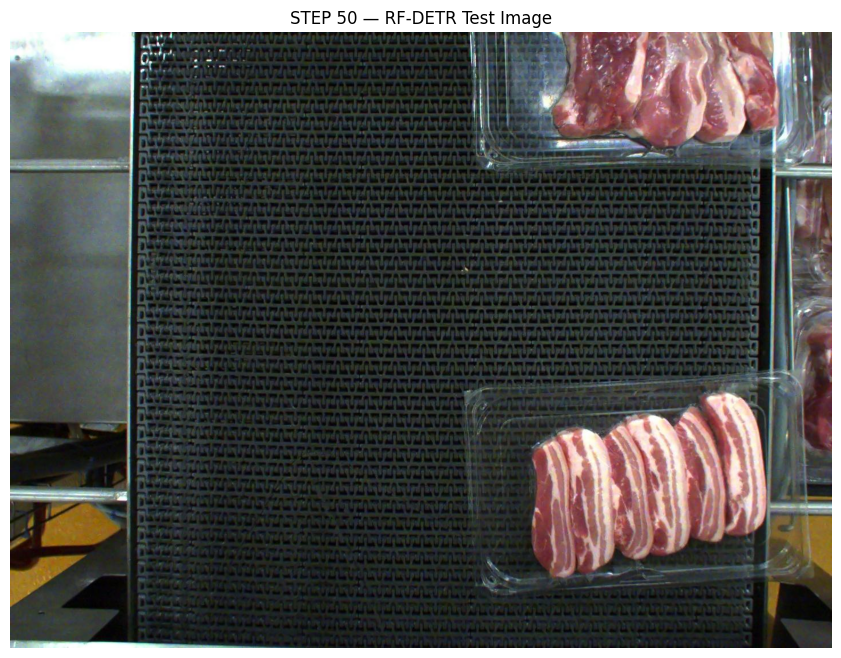


Image dimensions: (1080, 1440, 3)
Image path: /content/meat_dataset_verified/test/images/frame_with_red_2317_jpg.rf.4167a415845c0dc4c4d405d8ca633a35.jpg

STEP 50 COMPLETE


In [4]:
# STEP 50 — SELECT TEST IMAGE

import os
import glob
import random
import cv2
import matplotlib.pyplot as plt

print("STEP 50 — SELECTING TEST IMAGE")
print("=" * 50)

dataset_path = "/content/meat_dataset_verified"

test_images = sorted(
    glob.glob(
        os.path.join(dataset_path, "test", "images", "*.jpg")
    )
)

print("Available test images:", len(test_images))

if not test_images:
    raise FileNotFoundError("No test images found.")

# Fixed selection for reproducibility
random.seed(42)

test_image_path = random.choice(test_images)

print("\nSelected image:")
print(os.path.basename(test_image_path))

image = cv2.imread(test_image_path)

if image is None:
    raise ValueError("Unable to read selected image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.title("STEP 50 — RF-DETR Test Image")
plt.axis("off")
plt.show()

print("\nImage dimensions:", image.shape)
print("Image path:", test_image_path)

print("\nSTEP 50 COMPLETE")

In [5]:
# STEP 51 — TEST RF-DETR NAS WORKFLOW

print("STEP 51 — TESTING RF-DETR NAS WORKFLOW")
print("=" * 50)

# Confirm the required variables are available
required_variables = ["client", "test_image_path"]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Restore the Roboflow connection before continuing."
    )

workspace_name = "hansaja"

workflow_id = (
    "pork-rasher-errorpackaging-"
    "vpork-rasher-error-packaging-lhpgq-1-"
    "rfdetr-nas-t1-fa3729-logic"
)

print("Selected image:")
print(os.path.basename(test_image_path))

print("\nSending image to Roboflow...")

try:
    result = client.run_workflow(
        workspace_name=workspace_name,
        workflow_id=workflow_id,
        images={
            "image": test_image_path
        },
        use_cache=True
    )

    print("\nPASS: Workflow executed successfully.")

    # Inspect response structure without printing large image data
    print("\nResponse type:", type(result).__name__)

    if isinstance(result, list):
        print("Number of results:", len(result))

        if result and isinstance(result[0], dict):
            print("Output keys:", list(result[0].keys()))

            for key, value in result[0].items():
                print(
                    f"{key}: {type(value).__name__}"
                )

    elif isinstance(result, dict):
        print("Output keys:", list(result.keys()))

    print("\nSTEP 51 COMPLETE")

except Exception as e:
    print("\nWORKFLOW ERROR")
    print("Error type:", type(e).__name__)
    print("Details:", str(e)[:1000])

STEP 51 — TESTING RF-DETR NAS WORKFLOW


RuntimeError: Missing variables: ['client']. Restore the Roboflow connection before continuing.

In [6]:
# STEP 51A — RESTORE ROBOFLOW CONNECTION

import os
from getpass import getpass
from inference_sdk import InferenceHTTPClient, InferenceConfiguration

print("STEP 51A — RESTORING ROBOFLOW CONNECTION")
print("=" * 50)

# Retrieve API key without displaying it
api_key = os.environ.get("ROBOFLOW_API_KEY")

if not api_key:
    api_key = getpass("Enter your Roboflow API key: ")
    os.environ["ROBOFLOW_API_KEY"] = api_key

# Create Roboflow client
client = InferenceHTTPClient(
    api_url="https://serverless.roboflow.com",
    api_key=api_key
)

# Configure header-based authentication
client.configure(
    InferenceConfiguration(
        api_key_transport="header"
    )
)

print("\nPASS: Roboflow client restored.")
print("Authentication: Header")
print("API endpoint: https://serverless.roboflow.com")

print("\nSTEP 51A COMPLETE")

ModuleNotFoundError: No module named 'inference_sdk'

In [7]:
# STEP 51B — REINSTALL ROBOFLOW SDK

print("STEP 51B — REINSTALLING ROBOFLOW SDK")
print("=" * 50)

%pip install -q "inference-sdk>=1.8,<1.9"

print("\nInstallation command completed.")
print("STEP 51B COMPLETE")

STEP 51B — REINSTALLING ROBOFLOW SDK
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.

Installation command completed.
STEP 51B COMPLETE


In [8]:
# STEP 51C — VERIFY ROBOFLOW SDK

print("STEP 51C — VERIFYING ROBOFLOW SDK")
print("=" * 50)

import importlib.metadata as metadata

for package in ["inference-sdk", "Pillow", "requests"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nTesting imports...")

try:
    from PIL import Image
    print("PASS: Pillow")

    from inference_sdk import (
        InferenceHTTPClient,
        InferenceConfiguration
    )
    print("PASS: Roboflow SDK")

    print("\nSUCCESS: Required imports are working.")

except Exception as e:
    print("\nERROR:", type(e).__name__)
    print("Details:", str(e))

print("\nSTEP 51C COMPLETE")

STEP 51C — VERIFYING ROBOFLOW SDK
inference-sdk: 1.8.3
Pillow: 12.3.0
requests: 2.34.2

Testing imports...
PASS: Pillow

ERROR: ImportError
Details: cannot import name '_Ink' from 'PIL._typing' (/usr/local/lib/python3.13/dist-packages/PIL/_typing.py)

STEP 51C COMPLETE


In [9]:
# STEP 51D — REPAIR PILLOW

print("STEP 51D — REPAIRING PILLOW")
print("=" * 50)

%pip install --force-reinstall --no-cache-dir "Pillow==11.3.0"

print("\nPillow installation command completed.")
print("A runtime restart may be required.")
print("\nSTEP 51D COMPLETE")

STEP 51D — REPAIRING PILLOW
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 42.0 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 12.3.0
    Uninstalling pillow-12.3.0:
      Successfully uninstalled pillow-12.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
inference-sdk 1.8.3 requires pillow<13.0.0,>=12.3.0, but you have pillow 11.3.0 which is incompatible.

Pillow installation command completed.
A runtime restart may be required.

STEP 51D COMPLETE


In [10]:
# STEP 51E — VERIFY REPAIRED INSTALLATION

print("STEP 51E — VERIFYING REPAIRED INSTALLATION")
print("=" * 50)

import importlib.metadata as metadata

print("Installed versions:")
for package in ["inference-sdk", "Pillow", "requests"]:
    print(f"{package}: {metadata.version(package)}")

print("\nTesting imports...")

try:
    from PIL import Image
    print("PASS: Pillow")

    from inference_sdk import (
        InferenceHTTPClient,
        InferenceConfiguration
    )
    print("PASS: Roboflow SDK")

    print("\nSUCCESS: Required imports are working.")

except Exception as e:
    print("\nFAILED:", type(e).__name__)
    print("Details:", str(e))

print("\nSTEP 51E COMPLETE")

STEP 51E — VERIFYING REPAIRED INSTALLATION
Installed versions:
inference-sdk: 1.8.3
Pillow: 11.3.0
requests: 2.34.2

Testing imports...
PASS: Pillow
PASS: Roboflow SDK

SUCCESS: Required imports are working.

STEP 51E COMPLETE


In [11]:
# STEP 51F — RESTORE ROBOFLOW CLIENT

import os
from getpass import getpass

from inference_sdk import (
    InferenceHTTPClient,
    InferenceConfiguration
)

print("STEP 51F — RESTORING ROBOFLOW CLIENT")
print("=" * 50)

# Retrieve API key securely
api_key = os.environ.get("ROBOFLOW_API_KEY")

if not api_key:
    api_key = getpass("Enter your Roboflow API key: ")
    os.environ["ROBOFLOW_API_KEY"] = api_key

# Initialize client
client = InferenceHTTPClient(
    api_url="https://serverless.roboflow.com",
    api_key=api_key
)

# Configure header-based authentication
client.configure(
    InferenceConfiguration(
        api_key_transport="header"
    )
)

print("\nPASS: Roboflow client configured.")
print("Workspace: hansaja")
print("Authentication: Header")
print("API key: Hidden")

print("\nSTEP 51F COMPLETE")

STEP 51F — RESTORING ROBOFLOW CLIENT
Enter your Roboflow API key: ··········

PASS: Roboflow client configured.
Workspace: hansaja
Authentication: Header
API key: Hidden

STEP 51F COMPLETE


In [12]:
# STEP 51G — RUN RF-DETR NAS WORKFLOW

import os

print("STEP 51G — RF-DETR NAS INFERENCE")
print("=" * 50)

workspace_name = "hansaja"

workflow_id = (
    "pork-rasher-errorpackaging-"
    "vpork-rasher-error-packaging-lhpgq-1-"
    "rfdetr-nas-t1-fa3729-logic"
)

# Verify selected image
if "test_image_path" not in globals():
    raise RuntimeError(
        "Test image variable missing. Rerun Step 50."
    )

if not os.path.isfile(test_image_path):
    raise FileNotFoundError(test_image_path)

print("Test image:", os.path.basename(test_image_path))
print("\nRunning inference...")

try:
    rf_result = client.run_workflow(
        workspace_name=workspace_name,
        workflow_id=workflow_id,
        images={"image": test_image_path},
        use_cache=True
    )

    print("\nPASS: RF-DETR workflow executed.")

    print("Response type:", type(rf_result).__name__)

    if isinstance(rf_result, list):
        print("Number of responses:", len(rf_result))

        if rf_result and isinstance(rf_result[0], dict):
            print("\nWorkflow output keys:")
            for key, value in rf_result[0].items():
                print(f" - {key}: {type(value).__name__}")

    elif isinstance(rf_result, dict):
        print("\nWorkflow output keys:")
        for key, value in rf_result.items():
            print(f" - {key}: {type(value).__name__}")

    print("\nSTEP 51G COMPLETE")

except Exception as e:
    print("\nINFERENCE FAILED")
    print("Error:", type(e).__name__)
    print("Details:", str(e)[:800])

STEP 51G — RF-DETR NAS INFERENCE
Test image: frame_with_red_2317_jpg.rf.4167a415845c0dc4c4d405d8ca633a35.jpg

Running inference...

PASS: RF-DETR workflow executed.
Response type: list
Number of responses: 1

Workflow output keys:
 - predictions: dict

STEP 51G COMPLETE


In [13]:
# STEP 52 — INSPECT RF-DETR PREDICTIONS

print("STEP 52 — INSPECTING RF-DETR PREDICTIONS")
print("=" * 55)

# Retrieve actual workflow output
output = rf_result[0]

predictions_data = output["predictions"]

print("\nPrediction dictionary keys:")
for key in predictions_data.keys():
    print(" -", key)

# Extract detections
detections = predictions_data.get("predictions", [])

print("\nNumber of detected objects:", len(detections))

print("\nDETECTION RESULTS")
print("-" * 55)

if len(detections) == 0:
    print("No defects detected in this image.")

else:
    for i, detection in enumerate(detections, start=1):

        print(f"\nDetection {i}")

        print("Class:", detection.get("class"))
        print("Confidence:", detection.get("confidence"))

        print("Centre X:", detection.get("x"))
        print("Centre Y:", detection.get("y"))

        print("Width:", detection.get("width"))
        print("Height:", detection.get("height"))

print("\nSTEP 52 COMPLETE")

STEP 52 — INSPECTING RF-DETR PREDICTIONS

Prediction dictionary keys:
 - image
 - predictions

Number of detected objects: 1

DETECTION RESULTS
-------------------------------------------------------

Detection 1
Class: packaging-error
Confidence: 0.408571720123291
Centre X: 1254.5
Centre Y: 625.0
Width: 121.0
Height: 72.0

STEP 52 COMPLETE


STEP 53 — RF-DETR PREDICTION VS GROUND TRUTH


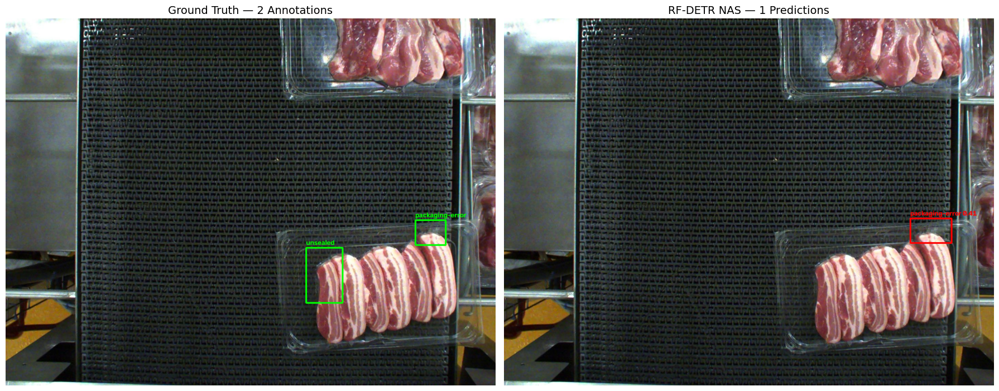


Ground-truth annotations: 2
RF-DETR predictions: 1

STEP 53 COMPLETE


In [14]:
# STEP 53 — RF-DETR PREDICTION VS GROUND TRUTH

import os
import cv2
import matplotlib.pyplot as plt

print("STEP 53 — RF-DETR PREDICTION VS GROUND TRUTH")
print("=" * 55)

# Load selected test image
image = cv2.imread(test_image_path)

if image is None:
    raise FileNotFoundError(test_image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

# Create separate copies
ground_truth_image = image.copy()
prediction_image = image.copy()

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

# -----------------------------------------
# 1. LOAD GROUND TRUTH
# -----------------------------------------

label_path = (
    test_image_path
    .replace("/images/", "/labels/")
    .rsplit(".", 1)[0] + ".txt"
)

gt_count = 0

if os.path.exists(label_path):

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id = int(values[0])

        xc, yc, bw, bh = map(float, values[1:])

        x1 = int((xc - bw / 2) * width)
        y1 = int((yc - bh / 2) * height)

        x2 = int((xc + bw / 2) * width)
        y2 = int((yc + bh / 2) * height)

        cv2.rectangle(
            ground_truth_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        label = class_names[class_id]

        cv2.putText(
            ground_truth_image,
            label,
            (x1, max(y1 - 8, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        gt_count += 1

# -----------------------------------------
# 2. DRAW RF-DETR PREDICTIONS
# -----------------------------------------

detections = rf_result[0]["predictions"]["predictions"]

for detection in detections:

    xc = detection["x"]
    yc = detection["y"]

    bw = detection["width"]
    bh = detection["height"]

    x1 = int(xc - bw / 2)
    y1 = int(yc - bh / 2)

    x2 = int(xc + bw / 2)
    y2 = int(yc + bh / 2)

    cv2.rectangle(
        prediction_image,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        3
    )

    label = (
        f"{detection['class']} "
        f"{detection['confidence']:.2f}"
    )

    cv2.putText(
        prediction_image,
        label,
        (x1, max(y1 - 8, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (255, 0, 0),
        2
    )

# -----------------------------------------
# 3. DISPLAY COMPARISON
# -----------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(ground_truth_image)
axes[0].set_title(
    f"Ground Truth — {gt_count} Annotations",
    fontsize=14
)
axes[0].axis("off")

axes[1].imshow(prediction_image)
axes[1].set_title(
    f"RF-DETR NAS — {len(detections)} Predictions",
    fontsize=14
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("\nGround-truth annotations:", gt_count)
print("RF-DETR predictions:", len(detections))

print("\nSTEP 53 COMPLETE")

In [15]:
# STEP 54 — RF-DETR IoU ANALYSIS

import os

print("STEP 54 — RF-DETR IoU ANALYSIS")
print("=" * 55)

# Image dimensions from Step 53
height, width = image.shape[:2]

# Load ground-truth boxes
gt_boxes = []

with open(label_path, "r") as f:
    for line in f:
        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id = int(values[0])
        xc, yc, bw, bh = map(float, values[1:])

        gt_boxes.append({
            "class": class_names[class_id],
            "box": [
                (xc - bw / 2) * width,
                (yc - bh / 2) * height,
                (xc + bw / 2) * width,
                (yc + bh / 2) * height
            ]
        })

# Load prediction boxes
pred_boxes = []

for d in detections:
    pred_boxes.append({
        "class": d["class"],
        "confidence": d["confidence"],
        "box": [
            d["x"] - d["width"] / 2,
            d["y"] - d["height"] / 2,
            d["x"] + d["width"] / 2,
            d["y"] + d["height"] / 2
        ]
    })

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

print("\nGROUND TRUTH VS PREDICTIONS")
print("-" * 55)

for i, pred in enumerate(pred_boxes, start=1):
    print(f"\nPrediction {i}: {pred['class']}")
    print(f"Confidence: {pred['confidence']:.3f}")

    for j, gt in enumerate(gt_boxes, start=1):
        iou = calculate_iou(pred["box"], gt["box"])

        print(
            f"  Ground Truth {j} ({gt['class']}): "
            f"IoU = {iou:.4f}"
        )

        if pred["class"] == gt["class"] and iou >= 0.5:
            print("  Result: Potential true positive")
        else:
            print("  Result: Does not meet matching criteria")

print("\nSTEP 54 COMPLETE")

STEP 54 — RF-DETR IoU ANALYSIS

GROUND TRUTH VS PREDICTIONS
-------------------------------------------------------

Prediction 1: packaging-error
Confidence: 0.409
  Ground Truth 1 (packaging-error): IoU = 0.6448
  Result: Potential true positive
  Ground Truth 2 (unsealed): IoU = 0.0000
  Result: Does not meet matching criteria

STEP 54 COMPLETE


In [16]:
# STEP 55 — PREPARING FULL RF-DETR EVALUATION

import os
import glob
import pandas as pd

print("STEP 55 — PREPARING FULL RF-DETR EVALUATION")
print("=" * 55)

dataset_path = "/content/meat_dataset_verified"

image_dir = os.path.join(dataset_path, "test", "images")
label_dir = os.path.join(dataset_path, "test", "labels")

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

image_files = sorted(
    glob.glob(os.path.join(image_dir, "*.jpg")) +
    glob.glob(os.path.join(image_dir, "*.jpeg")) +
    glob.glob(os.path.join(image_dir, "*.png"))
)

records = []

for image_path in image_files:

    filename = os.path.basename(image_path)
    label_path = os.path.join(
        label_dir,
        os.path.splitext(filename)[0] + ".txt"
    )

    annotations = []

    if os.path.exists(label_path):

        with open(label_path, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) == 5:
                    class_id = int(values[0])

                    if 0 <= class_id < len(class_names):
                        annotations.append(class_names[class_id])

    records.append({
        "image": filename,
        "image_path": image_path,
        "label_path": label_path,
        "ground_truth_count": len(annotations),
        "classes": ", ".join(annotations)
    })

evaluation_df = pd.DataFrame(records)

print("\nTEST DATASET")
print("-" * 55)

print("Total images:", len(evaluation_df))
print("Total annotations:", evaluation_df["ground_truth_count"].sum())

print("\nCLASS DISTRIBUTION")
print("-" * 55)

class_counts = {name: 0 for name in class_names}

for record in records:
    for name in record["classes"].split(", "):
        if name in class_counts:
            class_counts[name] += 1

for name, count in class_counts.items():
    print(f"{name:20s}: {count}")

print("\nEVALUATION READINESS")
print("-" * 55)

print("Roboflow client available:", "client" in globals())
print("Test images available:", len(image_files) == 76)

print("\nSTEP 55 COMPLETE")

STEP 55 — PREPARING FULL RF-DETR EVALUATION

TEST DATASET
-------------------------------------------------------
Total images: 76
Total annotations: 91

CLASS DISTRIBUTION
-------------------------------------------------------
loose-meat          : 3
packaging-error     : 29
twisted-meat        : 7
unsealed            : 52
wrinkle             : 0

EVALUATION READINESS
-------------------------------------------------------
Roboflow client available: True
Test images available: True

STEP 55 COMPLETE


In [17]:
# STEP 56 — RF-DETR NAS BATCH INFERENCE (FIRST 5 IMAGES)

import os
import json
import time
from pathlib import Path

print("STEP 56 — RF-DETR NAS BATCH INFERENCE")
print("=" * 55)

# Google Drive storage
output_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_evaluation"
)

os.makedirs(output_dir, exist_ok=True)

workspace_name = "hansaja"

workflow_id = (
    "pork-rasher-errorpackaging-"
    "vpork-rasher-error-packaging-lhpgq-1-"
    "rfdetr-nas-t1-fa3729-logic"
)

# Use the first five test images
sample_images = evaluation_df.head(5)

print("Images selected:", len(sample_images))
print("Output directory:", output_dir)

success_count = 0
failure_count = 0

for index, row in sample_images.iterrows():

    image_path = row["image_path"]
    filename = row["image"]

    output_file = os.path.join(
        output_dir,
        Path(filename).stem + ".json"
    )

    # Avoid repeating completed requests
    if os.path.exists(output_file):
        print(f"SKIPPED (already saved): {filename}")
        continue

    print(f"\nProcessing: {filename}")

    try:
        result = client.run_workflow(
            workspace_name=workspace_name,
            workflow_id=workflow_id,
            images={"image": image_path},
            use_cache=True
        )

        if not isinstance(result, list) or not result:
            raise ValueError("Unexpected workflow response.")

        response = result[0]

        if "predictions" not in response:
            raise ValueError(
                f"Missing predictions output. Keys: {list(response.keys())}"
            )

        prediction_data = response["predictions"]

        # Store structured prediction data only
        with open(output_file, "w") as f:
            json.dump(
                prediction_data,
                f,
                indent=2
            )

        success_count += 1

        print("PASS: Prediction saved.")

    except Exception as e:

        failure_count += 1

        print("ERROR:", str(e))

    time.sleep(0.5)

print("\nBATCH SUMMARY")
print("-" * 55)

print("Successful:", success_count)
print("Failed:", failure_count)

print("\nSTEP 56 COMPLETE")

STEP 56 — RF-DETR NAS BATCH INFERENCE
Images selected: 5
Output directory: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_evaluation

Processing: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.jpg
PASS: Prediction saved.

Processing: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.jpg
PASS: Prediction saved.

Processing: frame_with_red_1271_jpg.rf.73791f248e4a290b4f94dec822ce6ca7.jpg
PASS: Prediction saved.

Processing: frame_with_red_1298_jpg.rf.5e67f735fd446e1d9533abb785d1d209.jpg
PASS: Prediction saved.

Processing: frame_with_red_1405_jpg.rf.4936b698a957f9e625f7e8f59881e6f7.jpg
PASS: Prediction saved.

BATCH SUMMARY
-------------------------------------------------------
Successful: 5
Failed: 0

STEP 56 COMPLETE


In [18]:
# STEP 57 — COMPLETE RF-DETR NAS TEST INFERENCE

import os
import json
import time
from pathlib import Path

print("STEP 57 — COMPLETE RF-DETR NAS EVALUATION")
print("=" * 55)

output_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_evaluation"
)

os.makedirs(output_dir, exist_ok=True)

workspace_name = "hansaja"

workflow_id = (
    "pork-rasher-errorpackaging-"
    "vpork-rasher-error-packaging-lhpgq-1-"
    "rfdetr-nas-t1-fa3729-logic"
)

total_images = len(evaluation_df)

completed = 0
skipped = 0
failed = 0
failed_images = []

print("Total test images:", total_images)
print("Saving results to:", output_dir)
print("-" * 55)

for number, (_, row) in enumerate(
    evaluation_df.iterrows(), start=1
):

    image_path = row["image_path"]
    filename = row["image"]

    output_file = os.path.join(
        output_dir,
        Path(filename).stem + ".json"
    )

    # Skip previously completed images
    if os.path.exists(output_file):

        skipped += 1

        print(
            f"[{number}/{total_images}] "
            f"SKIPPED: {filename}"
        )

        continue

    success = False

    for attempt in range(3):

        try:

            result = client.run_workflow(
                workspace_name=workspace_name,
                workflow_id=workflow_id,
                images={"image": image_path},
                use_cache=True
            )

            if not isinstance(result, list) or not result:
                raise ValueError("Unexpected workflow response")

            response = result[0]

            if "predictions" not in response:
                raise ValueError(
                    "Predictions missing from response"
                )

            prediction_data = response["predictions"]

            # Save safely using a temporary file
            temporary_file = output_file + ".tmp"

            with open(temporary_file, "w") as f:
                json.dump(prediction_data, f, indent=2)

            os.replace(temporary_file, output_file)

            completed += 1
            success = True

            print(
                f"[{number}/{total_images}] "
                f"PASS: {filename}"
            )

            break

        except Exception as e:

            print(
                f"[{number}/{total_images}] "
                f"Attempt {attempt + 1} failed: {e}"
            )

            if attempt < 2:
                time.sleep(2 ** (attempt + 1))

    if not success:

        failed += 1
        failed_images.append(filename)

    time.sleep(0.3)


# Verify saved predictions
saved_files = list(Path(output_dir).glob("*.json"))

print("\n" + "=" * 55)
print("FINAL EVALUATION SUMMARY")
print("=" * 55)

print("Total test images:", total_images)
print("Newly processed:", completed)
print("Previously completed:", skipped)
print("Failed:", failed)
print("Saved JSON files:", len(saved_files))

if failed_images:

    print("\nFAILED IMAGES:")

    for filename in failed_images:
        print("-", filename)

else:

    print("\nPASS: No inference failures.")

if len(saved_files) == total_images:

    print("\nSUCCESS: ALL TEST PREDICTIONS SAVED.")

else:

    print("\nWARNING: Evaluation is not yet complete.")

print("\nSTEP 57 COMPLETE")

STEP 57 — COMPLETE RF-DETR NAS EVALUATION
Total test images: 76
Saving results to: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_evaluation
-------------------------------------------------------
[1/76] SKIPPED: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.jpg
[2/76] SKIPPED: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.jpg
[3/76] SKIPPED: frame_with_red_1271_jpg.rf.73791f248e4a290b4f94dec822ce6ca7.jpg
[4/76] SKIPPED: frame_with_red_1298_jpg.rf.5e67f735fd446e1d9533abb785d1d209.jpg
[5/76] SKIPPED: frame_with_red_1405_jpg.rf.4936b698a957f9e625f7e8f59881e6f7.jpg
[6/76] PASS: frame_with_red_1427_jpg.rf.c0d992d9986ffe41af8d83dd69438aef.jpg
[7/76] PASS: frame_with_red_1458_jpg.rf.e20e1b5b5f3135bf07d43b17fe48d731.jpg
[8/76] PASS: frame_with_red_1521_jpg.rf.d00700159daf8ad4df9dd2e9414d2616.jpg
[9/76] PASS: frame_with_red_161_jpg.rf.56608f17123759b1243b8c79b39ef254.jpg
[10/76] PASS: frame_with_red_1695_jpg.rf.863a3e2ad41527e901b8f4f3ce700315.jpg
[11/76] 

In [19]:
# STEP 58 — INSPECT SAVED RF-DETR PREDICTIONS

import os
import json
from pathlib import Path
from collections import Counter

print("STEP 58 — INSPECTING SAVED RF-DETR PREDICTIONS")
print("=" * 55)

output_dir = Path(
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_evaluation"
)

json_files = sorted(output_dir.glob("*.json"))

print("Saved prediction files:", len(json_files))

if not json_files:
    raise FileNotFoundError("No prediction JSON files found.")

total_detections = 0
class_counts = Counter()
confidence_values = []
errors = []

for file in json_files:

    try:
        with open(file, "r") as f:
            data = json.load(f)

        if not isinstance(data, dict):
            raise ValueError("Prediction data is not a dictionary.")

        predictions = data.get("predictions")

        if not isinstance(predictions, list):
            raise ValueError("Missing or invalid predictions list.")

        total_detections += len(predictions)

        for prediction in predictions:

            if not isinstance(prediction, dict):
                raise ValueError("Invalid detection entry.")

            class_name = prediction.get("class", "unknown")
            class_counts[class_name] += 1

            confidence = prediction.get("confidence")

            if isinstance(confidence, (int, float)):
                confidence_values.append(float(confidence))

    except Exception as e:
        errors.append((file.name, str(e)))

print("\nPREDICTION SUMMARY")
print("-" * 55)

print("Total detections:", total_detections)
print("Average detections per image:",
      round(total_detections / len(json_files), 2))

print("\nDETECTIONS BY CLASS")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name:20s}: {count}")

if confidence_values:
    print("\nCONFIDENCE STATISTICS")
    print("Minimum:", round(min(confidence_values), 4))
    print("Maximum:", round(max(confidence_values), 4))
    print(
        "Average:",
        round(sum(confidence_values) / len(confidence_values), 4)
    )

print("\nJSON VALIDATION")
print("-" * 55)

print("Valid files:", len(json_files) - len(errors))
print("Files with errors:", len(errors))

for filename, error in errors[:5]:
    print("ERROR:", filename, error)

print("\nEXAMPLE PREDICTION STRUCTURE")
print("-" * 55)

example_file = json_files[0]

with open(example_file, "r") as f:
    example = json.load(f)

print("Example file:", example_file.name)
print("Top-level keys:", list(example.keys()))

if example.get("predictions"):
    print(
        "Detection keys:",
        list(example["predictions"][0].keys())
    )
else:
    print("No detections in the first example.")

print("\nSTEP 58 COMPLETE")

STEP 58 — INSPECTING SAVED RF-DETR PREDICTIONS
Saved prediction files: 76

PREDICTION SUMMARY
-------------------------------------------------------
Total detections: 71
Average detections per image: 0.93

DETECTIONS BY CLASS
loose-meat          : 1
packaging-error     : 12
twisted-meat        : 10
unsealed            : 48

CONFIDENCE STATISTICS
Minimum: 0.4016
Maximum: 0.8449
Average: 0.6083

JSON VALIDATION
-------------------------------------------------------
Valid files: 76
Files with errors: 0

EXAMPLE PREDICTION STRUCTURE
-------------------------------------------------------
Example file: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.json
Top-level keys: ['image', 'predictions']
Detection keys: ['width', 'height', 'x', 'y', 'confidence', 'class_id', 'class', 'detection_id', 'parent_id']

STEP 58 COMPLETE


In [20]:
# STEP 59 — RF-DETR NAS PRECISION, RECALL AND F1

import os
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("STEP 59 — RF-DETR NAS PERFORMANCE EVALUATION")
print("=" * 60)

dataset_dir = Path("/content/meat_dataset_verified")

prediction_dir = Path(
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_evaluation"
)

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

iou_threshold = 0.50


# --------------------------------------------------
# 1. IoU FUNCTION
# --------------------------------------------------

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(
        0, box1[3] - box1[1]
    )

    area2 = max(0, box2[2] - box2[0]) * max(
        0, box2[3] - box2[1]
    )

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# --------------------------------------------------
# 2. LOAD GROUND TRUTH
# --------------------------------------------------

def load_ground_truth(label_path, image_width, image_height):

    annotations = []

    if not label_path.exists():
        return annotations

    with open(label_path, "r") as f:

        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(float(values[0]))

            xc, yc, w, h = map(float, values[1:])

            x1 = (xc - w / 2) * image_width
            y1 = (yc - h / 2) * image_height

            x2 = (xc + w / 2) * image_width
            y2 = (yc + h / 2) * image_height

            annotations.append({
                "class": class_names[class_id],
                "box": [x1, y1, x2, y2]
            })

    return annotations


# --------------------------------------------------
# 3. LOAD RF-DETR PREDICTIONS
# --------------------------------------------------

def load_predictions(json_path):

    with open(json_path, "r") as f:
        data = json.load(f)

    predictions = []

    for prediction in data.get("predictions", []):

        xc = float(prediction["x"])
        yc = float(prediction["y"])

        w = float(prediction["width"])
        h = float(prediction["height"])

        predictions.append({
            "class": prediction["class"],
            "confidence": float(prediction["confidence"]),
            "box": [
                xc - w / 2,
                yc - h / 2,
                xc + w / 2,
                yc + h / 2
            ]
        })

    return predictions


# --------------------------------------------------
# 4. EVALUATE ALL TEST IMAGES
# --------------------------------------------------

results = {
    name: {"TP": 0, "FP": 0, "FN": 0}
    for name in class_names
}

image_dir = dataset_dir / "test" / "images"
label_dir = dataset_dir / "test" / "labels"

image_paths = sorted(image_dir.glob("*.jpg"))

print("Test images:", len(image_paths))

if len(image_paths) != 76:
    raise RuntimeError("Unexpected test image count.")

for image_path in image_paths:

    from PIL import Image

    with Image.open(image_path) as image:
        image_width, image_height = image.size

    label_path = label_dir / (
        image_path.stem + ".txt"
    )

    json_path = prediction_dir / (
        image_path.stem + ".json"
    )

    if not json_path.exists():
        raise FileNotFoundError(
            f"Missing prediction: {json_path.name}"
        )

    ground_truth = load_ground_truth(
        label_path,
        image_width,
        image_height
    )

    predictions = load_predictions(json_path)

    # Evaluate each class independently
    for class_name in class_names:

        gt_boxes = [
            item["box"]
            for item in ground_truth
            if item["class"] == class_name
        ]

        pred_boxes = [
            item
            for item in predictions
            if item["class"] == class_name
        ]

        # Highest-confidence predictions first
        pred_boxes.sort(
            key=lambda item: item["confidence"],
            reverse=True
        )

        matched_gt = set()

        for prediction in pred_boxes:

            best_iou = 0
            best_gt = -1

            for gt_index, gt_box in enumerate(gt_boxes):

                if gt_index in matched_gt:
                    continue

                iou = calculate_iou(
                    prediction["box"],
                    gt_box
                )

                if iou > best_iou:
                    best_iou = iou
                    best_gt = gt_index

            if best_iou >= iou_threshold:

                results[class_name]["TP"] += 1
                matched_gt.add(best_gt)

            else:

                results[class_name]["FP"] += 1

        results[class_name]["FN"] += (
            len(gt_boxes) - len(matched_gt)
        )


# --------------------------------------------------
# 5. CALCULATE METRICS
# --------------------------------------------------

rows = []

for class_name, counts in results.items():

    tp = counts["TP"]
    fp = counts["FP"]
    fn = counts["FN"]

    precision = tp / (tp + fp) if tp + fp > 0 else 0

    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    rows.append({
        "Class": class_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

metrics_df = pd.DataFrame(rows)

print("\nPER-CLASS PERFORMANCE")
print("-" * 60)

print(metrics_df.to_string(index=False))


# --------------------------------------------------
# 6. OVERALL MICRO-AVERAGED METRICS
# --------------------------------------------------

total_tp = metrics_df["TP"].sum()
total_fp = metrics_df["FP"].sum()
total_fn = metrics_df["FN"].sum()

overall_precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp > 0 else 0
)

overall_recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn > 0 else 0
)

overall_f1 = (
    2 * overall_precision * overall_recall /
    (overall_precision + overall_recall)
    if overall_precision + overall_recall > 0 else 0
)

print("\nOVERALL PERFORMANCE")
print("-" * 60)

print("True Positives:", total_tp)
print("False Positives:", total_fp)
print("False Negatives:", total_fn)

print(f"Precision: {overall_precision:.4f}")
print(f"Recall:    {overall_recall:.4f}")
print(f"F1-score:  {overall_f1:.4f}")


# --------------------------------------------------
# 7. SAVE RESULTS TO GOOGLE DRIVE
# --------------------------------------------------

save_path = prediction_dir / "rf_detr_metrics.csv"

metrics_df.to_csv(save_path, index=False)

print("\nResults saved:", save_path)

print("\nSTEP 59 COMPLETE")

STEP 59 — RF-DETR NAS PERFORMANCE EVALUATION
Test images: 76

PER-CLASS PERFORMANCE
------------------------------------------------------------
          Class  TP  FP  FN  Precision   Recall       F1
     loose-meat   1   0   2   1.000000 0.333333 0.500000
packaging-error   5   7  24   0.416667 0.172414 0.243902
   twisted-meat   4   6   3   0.400000 0.571429 0.470588
       unsealed  40   8  12   0.833333 0.769231 0.800000
        wrinkle   0   0   0   0.000000 0.000000 0.000000

OVERALL PERFORMANCE
------------------------------------------------------------
True Positives: 50
False Positives: 21
False Negatives: 41
Precision: 0.7042
Recall:    0.5495
F1-score:  0.6173

Results saved: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_evaluation/rf_detr_metrics.csv

STEP 59 COMPLETE


In [21]:
# STEP 60 — RF-DETR CONFIDENCE DISTRIBUTION

import json
import numpy as np
from pathlib import Path

print("STEP 60 — RF-DETR CONFIDENCE ANALYSIS")
print("=" * 55)

prediction_dir = Path(
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_evaluation"
)

confidence_values = []

for file in sorted(prediction_dir.glob("*.json")):

    # Exclude any other JSON files that may be added later
    if not file.name.startswith("frame_with_red_"):
        continue

    with open(file, "r") as f:
        data = json.load(f)

    for prediction in data.get("predictions", []):
        confidence_values.append(
            float(prediction["confidence"])
        )

confidence_values = np.array(confidence_values)

print("Total detections:", len(confidence_values))

if len(confidence_values) == 0:
    raise RuntimeError("No detection confidences found.")

print("\nCONFIDENCE DISTRIBUTION")
print("-" * 55)

ranges = [
    (0.00, 0.10),
    (0.10, 0.20),
    (0.20, 0.30),
    (0.30, 0.40),
    (0.40, 0.50),
    (0.50, 0.60),
    (0.60, 0.70),
    (0.70, 0.80),
    (0.80, 0.90),
    (0.90, 1.01)
]

for lower, upper in ranges:

    count = np.sum(
        (confidence_values >= lower) &
        (confidence_values < upper)
    )

    print(f"{lower:.2f}–{upper:.2f}: {count}")

print("\nSUMMARY")
print("-" * 55)

print("Minimum:", round(confidence_values.min(), 4))
print("Maximum:", round(confidence_values.max(), 4))
print("Median:", round(np.median(confidence_values), 4))
print("Mean:", round(confidence_values.mean(), 4))

print("\nSTEP 60 COMPLETE")

STEP 60 — RF-DETR CONFIDENCE ANALYSIS
Total detections: 71

CONFIDENCE DISTRIBUTION
-------------------------------------------------------
0.00–0.10: 0
0.10–0.20: 0
0.20–0.30: 0
0.30–0.40: 0
0.40–0.50: 23
0.50–0.60: 13
0.60–0.70: 12
0.70–0.80: 13
0.80–0.90: 10
0.90–1.01: 0

SUMMARY
-------------------------------------------------------
Minimum: 0.4016
Maximum: 0.8449
Median: 0.5925
Mean: 0.6083

STEP 60 COMPLETE


In [22]:
# STEP 62C — VERIFY PUBLISHED RF-DETR WORKFLOW

import os
import glob
from getpass import getpass

from inference_sdk import InferenceHTTPClient, InferenceConfiguration

print("STEP 62C — VERIFYING PUBLISHED WORKFLOW")
print("=" * 50)

# Restore API connection if necessary
api_key = os.environ.get("ROBOFLOW_API_KEY")

if not api_key:
    api_key = getpass("Enter your Roboflow API key: ")
    os.environ["ROBOFLOW_API_KEY"] = api_key

client = InferenceHTTPClient(
    api_url="https://serverless.roboflow.com",
    api_key=api_key
).configure(
    InferenceConfiguration(api_key_transport="header")
)

# Find the original Step 50 test image
test_dir = "/content/meat_dataset_verified/test/images"

matches = glob.glob(
    os.path.join(test_dir, "frame_with_red_2317_jpg*")
)

if not matches:
    raise FileNotFoundError(
        "Step 50 test image not found. Check dataset restoration."
    )

test_image = matches[0]

print("Test image:", os.path.basename(test_image))
print("\nRunning RF-DETR inference...")

result = client.run_workflow(
    workspace_name="hansaja",
    workflow_id=(
        "pork-rasher-errorpackaging-"
        "vpork-rasher-error-packaging-lhpgq-1-"
        "rfdetr-nas-t1-fa3729-logic"
    ),
    images={"image": test_image},
    use_cache=False
)

predictions = result[0]["predictions"]["predictions"]

print("\nDETECTION RESULTS")
print("-" * 50)

for i, pred in enumerate(predictions, 1):
    print(
        f"{i}. {pred['class']} | "
        f"Confidence: {pred['confidence']:.4f}"
    )

print("\nTotal detections:", len(predictions))
print("STEP 62C COMPLETE")

STEP 62C — VERIFYING PUBLISHED WORKFLOW
Test image: frame_with_red_2317_jpg.rf.4167a415845c0dc4c4d405d8ca633a35.jpg

Running RF-DETR inference...

DETECTION RESULTS
--------------------------------------------------
1. packaging-error | Confidence: 0.4086
2. unsealed | Confidence: 0.3435
3. packaging-error | Confidence: 0.3152

Total detections: 3
STEP 62C COMPLETE


In [23]:
# STEP 63 — FULL RF-DETR EVALUATION AT CONFIDENCE 0.25

import os
import glob
import json
import time

print("STEP 63 — RF-DETR BATCH INFERENCE (CONFIDENCE 0.25)")
print("=" * 60)

# Dataset
test_dir = "/content/meat_dataset_verified/test/images"

# Separate folder for 0.25 confidence predictions
output_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_conf025_predictions"
)

os.makedirs(output_dir, exist_ok=True)

# Find all test images
test_images = sorted(
    glob.glob(os.path.join(test_dir, "*.jpg"))
)

print("Test images found:", len(test_images))
print("Output directory:", output_dir)

if len(test_images) != 76:
    raise RuntimeError(
        f"Expected 76 test images, found {len(test_images)}."
    )

# Use the Roboflow client configured in Step 62C
if "client" not in globals():
    raise RuntimeError(
        "Roboflow client not found. Run Step 62C first."
    )

successful = 0
failed = []

for i, image_path in enumerate(test_images, 1):

    filename = os.path.basename(image_path)
    output_path = os.path.join(
        output_dir,
        os.path.splitext(filename)[0] + ".json"
    )

    # Skip completed images if the cell is rerun
    if os.path.exists(output_path):
        successful += 1
        print(f"[{i}/76] SKIPPED: {filename}")
        continue

    for attempt in range(3):
        try:
            result = client.run_workflow(
                workspace_name="hansaja",
                workflow_id=(
                    "pork-rasher-errorpackaging-"
                    "vpork-rasher-error-packaging-lhpgq-1-"
                    "rfdetr-nas-t1-fa3729-logic"
                ),
                images={"image": image_path},
                use_cache=False
            )

            # Extract predictions using the verified response structure
            predictions = result[0]["predictions"]

            # Save only the required metadata and detections
            with open(output_path, "w") as f:
                json.dump(predictions, f)

            successful += 1

            print(f"[{i}/76] PASS: {filename}")
            break

        except Exception as e:

            if attempt == 2:
                failed.append((filename, str(e)))
                print(f"[{i}/76] FAILED: {filename}")

            else:
                time.sleep(2 ** attempt)

print("\n" + "=" * 60)
print("STEP 63 — FINAL SUMMARY")
print("=" * 60)

print("Total test images:", len(test_images))
print("Successful:", successful)
print("Failed:", len(failed))

saved_files = glob.glob(os.path.join(output_dir, "*.json"))

print("Saved prediction files:", len(saved_files))

if failed:
    print("\nFAILED IMAGES:")
    for filename, error in failed:
        print(filename, ":", error)

if len(saved_files) == 76 and not failed:
    print("\nSUCCESS: ALL 76 PREDICTIONS SAVED.")
else:
    print("\nWARNING: Some predictions are missing.")

print("\nSTEP 63 COMPLETE")

STEP 63 — RF-DETR BATCH INFERENCE (CONFIDENCE 0.25)
Test images found: 76
Output directory: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_conf025_predictions
[1/76] PASS: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.jpg
[2/76] PASS: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.jpg
[3/76] PASS: frame_with_red_1271_jpg.rf.73791f248e4a290b4f94dec822ce6ca7.jpg
[4/76] PASS: frame_with_red_1298_jpg.rf.5e67f735fd446e1d9533abb785d1d209.jpg
[5/76] PASS: frame_with_red_1405_jpg.rf.4936b698a957f9e625f7e8f59881e6f7.jpg
[6/76] PASS: frame_with_red_1427_jpg.rf.c0d992d9986ffe41af8d83dd69438aef.jpg
[7/76] PASS: frame_with_red_1458_jpg.rf.e20e1b5b5f3135bf07d43b17fe48d731.jpg
[8/76] PASS: frame_with_red_1521_jpg.rf.d00700159daf8ad4df9dd2e9414d2616.jpg
[9/76] PASS: frame_with_red_161_jpg.rf.56608f17123759b1243b8c79b39ef254.jpg
[10/76] PASS: frame_with_red_1695_jpg.rf.863a3e2ad41527e901b8f4f3ce700315.jpg
[11/76] PASS: frame_with_red_1787_jpg.rf.7ae5989b93104d778533

In [24]:
# STEP 64 — RF-DETR PERFORMANCE EVALUATION (CONFIDENCE 0.25)

import os
import glob
import json
import numpy as np
import pandas as pd

print("STEP 64 — RF-DETR PERFORMANCE EVALUATION")
print("=" * 60)

dataset_dir = "/content/meat_dataset_verified"

prediction_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_conf025_predictions"
)

classes = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

def calculate_iou(box1, box2):
    """Calculate IoU for two xyxy bounding boxes."""

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def yolo_to_xyxy(line, img_width, img_height):
    values = list(map(float, line.split()))

    class_id = int(values[0])
    x, y, w, h = values[1:5]

    return {
        "class": classes[class_id],
        "box": [
            (x - w / 2) * img_width,
            (y - h / 2) * img_height,
            (x + w / 2) * img_width,
            (y + h / 2) * img_height
        ]
    }


def prediction_to_xyxy(pred):
    x, y = pred["x"], pred["y"]
    w, h = pred["width"], pred["height"]

    return {
        "class": pred["class"],
        "confidence": pred["confidence"],
        "box": [
            x - w / 2,
            y - h / 2,
            x + w / 2,
            y + h / 2
        ]
    }


results = {
    name: {"TP": 0, "FP": 0, "FN": 0}
    for name in classes
}

image_paths = sorted(
    glob.glob(f"{dataset_dir}/test/images/*.jpg")
)

if len(image_paths) != 76:
    raise RuntimeError(
        f"Expected 76 test images, found {len(image_paths)}."
    )

for image_path in image_paths:

    filename = os.path.basename(image_path)
    stem = os.path.splitext(filename)[0]

    label_path = f"{dataset_dir}/test/labels/{stem}.txt"
    prediction_path = f"{prediction_dir}/{stem}.json"

    if not os.path.exists(prediction_path):
        raise FileNotFoundError(prediction_path)

    with open(prediction_path) as f:
        data = json.load(f)

    img_width = data["image"]["width"]
    img_height = data["image"]["height"]

    # Read ground truth
    ground_truth = []

    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                if line.strip():
                    ground_truth.append(
                        yolo_to_xyxy(
                            line,
                            img_width,
                            img_height
                        )
                    )

    # Read predictions
    predictions = [
        prediction_to_xyxy(p)
        for p in data["predictions"]
    ]

    # Highest-confidence predictions first
    predictions.sort(
        key=lambda p: p["confidence"],
        reverse=True
    )

    matched_gt = set()

    for pred in predictions:

        best_iou = 0
        best_gt = None

        for j, gt in enumerate(ground_truth):

            if j in matched_gt:
                continue

            if pred["class"] != gt["class"]:
                continue

            iou = calculate_iou(
                pred["box"],
                gt["box"]
            )

            if iou > best_iou:
                best_iou = iou
                best_gt = j

        if best_iou >= 0.50:
            results[pred["class"]]["TP"] += 1
            matched_gt.add(best_gt)
        else:
            results[pred["class"]]["FP"] += 1

    for j, gt in enumerate(ground_truth):
        if j not in matched_gt:
            results[gt["class"]]["FN"] += 1


# Calculate performance metrics
rows = []

for name, counts in results.items():

    tp = counts["TP"]
    fp = counts["FP"]
    fn = counts["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Class": name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4)
    })


df = pd.DataFrame(rows)

print("\nPER-CLASS PERFORMANCE")
print("-" * 60)
print(df.to_string(index=False))

total_tp = df["TP"].sum()
total_fp = df["FP"].sum()
total_fn = df["FN"].sum()

precision = total_tp / (total_tp + total_fp)
recall = total_tp / (total_tp + total_fn)

f1 = 2 * precision * recall / (precision + recall)

print("\nOVERALL PERFORMANCE")
print("-" * 60)

print("True positives:", total_tp)
print("False positives:", total_fp)
print("False negatives:", total_fn)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

# Save results
output_path = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "rf_detr_conf025_performance.csv"
)

df.to_csv(output_path, index=False)

print("\nResults saved:", output_path)
print("\nSTEP 64 COMPLETE")

STEP 64 — RF-DETR PERFORMANCE EVALUATION

PER-CLASS PERFORMANCE
------------------------------------------------------------
          Class  TP  FP  FN  Precision  Recall     F1
     loose-meat   2   1   1     0.6667  0.6667 0.6667
packaging-error  16  34  13     0.3200  0.5517 0.4051
   twisted-meat   5  12   2     0.2941  0.7143 0.4167
       unsealed  42  23  10     0.6462  0.8077 0.7179
        wrinkle   0   0   0     0.0000  0.0000 0.0000

OVERALL PERFORMANCE
------------------------------------------------------------
True positives: 65
False positives: 70
False negatives: 26
Precision: 0.4815
Recall: 0.7143
F1-score: 0.5752

Results saved: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_conf025_performance.csv

STEP 64 COMPLETE


In [25]:
# STEP 65 — LOCATE RF-DETR EVALUATION FILES

import os

print("STEP 65 — LOCATING SAVED EVALUATION FILES")
print("=" * 55)

backup_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

for root, dirs, files in os.walk(backup_dir):

    depth = root.replace(backup_dir, "").count(os.sep)

    if depth > 3:
        dirs[:] = []
        continue

    json_files = [
        f for f in files
        if f.lower().endswith(".json")
    ]

    csv_files = [
        f for f in files
        if f.lower().endswith(".csv")
    ]

    if json_files or csv_files:

        print("\nFolder:", root)
        print("JSON files:", len(json_files))

        for filename in sorted(csv_files):
            print("CSV:", filename)

        for filename in sorted(json_files)[:2]:
            print("Example JSON:", filename)

print("\nSTEP 65 COMPLETE")

STEP 65 — LOCATING SAVED EVALUATION FILES

Folder: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality
JSON files: 0
CSV: rf_detr_conf025_performance.csv

Folder: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_conf025_predictions
JSON files: 76
Example JSON: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.json
Example JSON: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.json

Folder: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_evaluation
JSON files: 76
CSV: rf_detr_metrics.csv
Example JSON: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.json
Example JSON: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.json

STEP 65 COMPLETE


In [26]:
# STEP 66 — IDENTIFY RF-DETR PREDICTION FOLDERS

import os
import glob
import json

print("STEP 66 — IDENTIFYING RF-DETR PREDICTION FOLDERS")
print("=" * 60)

backup_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

prediction_folders = []

for root, dirs, files in os.walk(backup_dir):

    json_files = [
        f for f in files
        if f.lower().endswith(".json")
    ]

    if len(json_files) >= 50:

        prediction_folders.append(root)

        print("\nFOLDER:", root)
        print("JSON files:", len(json_files))

        # Inspect one saved prediction
        sample_path = os.path.join(root, json_files[0])

        with open(sample_path, "r") as f:
            data = json.load(f)

        print("Data type:", type(data).__name__)

        if isinstance(data, dict):
            print("Top-level keys:", list(data.keys()))

        elif isinstance(data, list):
            print("List length:", len(data))

            if data and isinstance(data[0], dict):
                print("First item keys:", list(data[0].keys()))

print("\n" + "=" * 60)
print("Prediction folders found:", len(prediction_folders))

if len(prediction_folders) == 2:
    print("PASS: Both prediction sets located.")
else:
    print("CHECK: Expected two prediction folders.")

print("\nSTEP 66 COMPLETE")

STEP 66 — IDENTIFYING RF-DETR PREDICTION FOLDERS

FOLDER: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_conf025_predictions
JSON files: 76
Data type: dict
Top-level keys: ['image', 'predictions']

FOLDER: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_evaluation
JSON files: 76
Data type: dict
Top-level keys: ['image', 'predictions']

Prediction folders found: 2
PASS: Both prediction sets located.

STEP 66 COMPLETE


In [27]:
# STEP 67 — IDENTIFY SAVED CONFIDENCE THRESHOLDS

import os
import json
import statistics

print("STEP 67 — IDENTIFYING CONFIDENCE THRESHOLDS")
print("=" * 60)

backup_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

for root, dirs, files in os.walk(backup_dir):

    json_files = sorted([
        f for f in files
        if f.lower().endswith(".json")
    ])

    if len(json_files) != 76:
        continue

    confidences = []
    total_detections = 0

    for filename in json_files:

        path = os.path.join(root, filename)

        with open(path, "r") as f:
            data = json.load(f)

        predictions = data.get("predictions", [])

        # Handle nested prediction dictionaries
        if isinstance(predictions, dict):
            predictions = predictions.get("predictions", [])

        total_detections += len(predictions)

        for prediction in predictions:
            if "confidence" in prediction:
                confidences.append(
                    float(prediction["confidence"])
                )

    print("\nFOLDER:")
    print(root)

    print("Images:", len(json_files))
    print("Total detections:", total_detections)

    if confidences:
        print("Minimum confidence:", round(min(confidences), 4))
        print("Maximum confidence:", round(max(confidences), 4))
        print("Average confidence:",
              round(statistics.mean(confidences), 4))
    else:
        print("No detections found.")

print("\nSTEP 67 COMPLETE")

STEP 67 — IDENTIFYING CONFIDENCE THRESHOLDS

FOLDER:
/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_conf025_predictions
Images: 76
Total detections: 135
Minimum confidence: 0.2526
Maximum confidence: 0.8449
Average confidence: 0.4678

FOLDER:
/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_evaluation
Images: 76
Total detections: 71
Minimum confidence: 0.4016
Maximum confidence: 0.8449
Average confidence: 0.6083

STEP 67 COMPLETE


In [28]:
# STEP 68 — CHECK PREDICTION CONSISTENCY

import os
import json

print("STEP 68 — CHECKING PREDICTION CONSISTENCY")
print("=" * 60)

backup_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

prediction_sets = {}

for root, dirs, files in os.walk(backup_dir):

    json_files = sorted(
        f for f in files if f.lower().endswith(".json")
    )

    if len(json_files) != 76:
        continue

    predictions = {}

    for filename in json_files:
        with open(os.path.join(root, filename), "r") as f:
            data = json.load(f)

        detections = data.get("predictions", [])

        if isinstance(detections, dict):
            detections = detections.get("predictions", [])

        predictions[filename] = detections

    all_confidences = [
        float(p["confidence"])
        for detections in predictions.values()
        for p in detections
        if "confidence" in p
    ]

    if not all_confidences:
        continue

    minimum = min(all_confidences)

    if minimum < 0.4:
        prediction_sets["0.25"] = predictions
    else:
        prediction_sets["0.40"] = predictions

print("Prediction sets found:", list(prediction_sets.keys()))

if len(prediction_sets) != 2:
    print("ERROR: Could not identify both prediction sets.")

else:
    low = prediction_sets["0.25"]
    high = prediction_sets["0.40"]

    common_files = sorted(set(low) & set(high))

    print("Matching filenames:", len(common_files))

    mismatched_images = 0
    missing_detections = 0

    for filename in common_files:

        low_predictions = low[filename]
        high_predictions = high[filename]

        # Compare detections by class, confidence and box coordinates.
        # Ignore detection_id because it may change between runs.
        def signature(p):
            return (
                p.get("class"),
                round(float(p.get("confidence", 0)), 3),
                round(float(p.get("x", 0)), 1),
                round(float(p.get("y", 0)), 1),
                round(float(p.get("width", 0)), 1),
                round(float(p.get("height", 0)), 1)
            )

        low_signatures = [signature(p) for p in low_predictions]
        high_signatures = [signature(p) for p in high_predictions]

        unmatched = low_signatures.copy()

        for prediction in high_signatures:
            if prediction in unmatched:
                unmatched.remove(prediction)
            else:
                missing_detections += 1

        if len(high_predictions) > len(low_predictions):
            mismatched_images += 1

    print("\nCONSISTENCY RESULTS")
    print("-" * 40)

    print("Images compared:", len(common_files))
    print("Images with more high-threshold detections:",
          mismatched_images)
    print("High-threshold detections not found at 0.25:",
          missing_detections)

    if len(common_files) == 76 and missing_detections == 0:
        print("\nPASS: Prediction sets are consistent.")
    else:
        print("\nCHECK: Some predictions differ between runs.")

print("\nSTEP 68 COMPLETE")

STEP 68 — CHECKING PREDICTION CONSISTENCY
Prediction sets found: ['0.25', '0.40']
Matching filenames: 76

CONSISTENCY RESULTS
----------------------------------------
Images compared: 76
Images with more high-threshold detections: 0
High-threshold detections not found at 0.25: 0

PASS: Prediction sets are consistent.

STEP 68 COMPLETE


In [29]:
# STEP 69 — CONFIDENCE THRESHOLD OPTIMISATION

import os
import glob
import json
import numpy as np
import pandas as pd

print("STEP 69 — RF-DETR CONFIDENCE OPTIMISATION")
print("=" * 60)

dataset_dir = "/content/meat_dataset_verified"

# Use the saved 0.25 prediction set
predictions = prediction_sets["0.25"]

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

# Convert YOLO ground-truth boxes to pixel coordinates
def load_ground_truth(image_path):

    import cv2

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(image_path)

    height, width = image.shape[:2]

    label_path = image_path.replace(
        "/images/", "/labels/"
    )

    label_path = os.path.splitext(label_path)[0] + ".txt"

    boxes = []

    if not os.path.exists(label_path):
        raise FileNotFoundError(label_path)

    with open(label_path, "r") as f:

        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                raise ValueError(
                    f"Invalid YOLO label: {label_path}"
                )

            class_id = int(values[0])

            xc, yc, w, h = map(float, values[1:])

            boxes.append({
                "class": class_names[class_id],
                "box": [
                    (xc - w / 2) * width,
                    (yc - h / 2) * height,
                    (xc + w / 2) * width,
                    (yc + h / 2) * height
                ]
            })

    return boxes


def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def evaluate_threshold(threshold):

    TP = FP = FN = 0

    for filename, detections in predictions.items():

        image_path = os.path.join(
            dataset_dir,
            "test",
            "images",
            filename.replace(".json", "")
        )

        ground_truth = load_ground_truth(image_path)

        selected = [
            p for p in detections
            if float(p["confidence"]) >= threshold
        ]

        selected.sort(
            key=lambda p: float(p["confidence"]),
            reverse=True
        )

        matched_gt = set()

        for p in selected:

            x = float(p["x"])
            y = float(p["y"])
            w = float(p["width"])
            h = float(p["height"])

            pred_box = [
                x-w/2,
                y-h/2,
                x+w/2,
                y+h/2
            ]

            best_iou = 0
            best_index = -1

            for i, gt in enumerate(ground_truth):

                if i in matched_gt:
                    continue

                if p["class"] != gt["class"]:
                    continue

                iou = calculate_iou(pred_box, gt["box"])

                if iou > best_iou:
                    best_iou = iou
                    best_index = i

            if best_iou >= 0.50:
                TP += 1
                matched_gt.add(best_index)
            else:
                FP += 1

        FN += len(ground_truth) - len(matched_gt)

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "Threshold": threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


thresholds = [0.25, 0.30, 0.35, 0.40]

results = pd.DataFrame([
    evaluate_threshold(t)
    for t in thresholds
])

print("\nCONFIDENCE THRESHOLD COMPARISON")
print("-" * 60)

print(results.to_string(index=False))

best = results.loc[results["F1"].idxmax()]

print("\nBEST F1-SCORE THRESHOLD")
print("-" * 60)

print("Threshold:", best["Threshold"])
print("Precision:", round(best["Precision"], 4))
print("Recall:", round(best["Recall"], 4))
print("F1-score:", round(best["F1"], 4))

print("\nSTEP 69 COMPLETE")

STEP 69 — RF-DETR CONFIDENCE OPTIMISATION


FileNotFoundError: /content/meat_dataset_verified/test/images/frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a

In [30]:
# STEP 69A — DIAGNOSE IMAGE-PATH MISMATCH

import os
import glob

print("STEP 69A — IMAGE PATH DIAGNOSTICS")
print("=" * 60)

dataset_dir = "/content/meat_dataset_verified"

image_files = sorted(
    glob.glob(os.path.join(dataset_dir, "test", "images", "*"))
)

prediction_files = sorted(prediction_sets["0.25"].keys())

print("\nDATASET")
print("-" * 40)
print("Dataset exists:", os.path.isdir(dataset_dir))
print("Test image count:", len(image_files))

print("\nEXAMPLE IMAGE FILENAMES")
for path in image_files[:3]:
    print(repr(os.path.basename(path)))

print("\nEXAMPLE PREDICTION FILENAMES")
for filename in prediction_files[:3]:
    print(repr(filename))

print("\nFILENAME MATCHING")
print("-" * 40)

image_names = {
    os.path.basename(path): path
    for path in image_files
}

for filename in prediction_files[:3]:

    candidates = [
        filename,
        filename.removesuffix(".json"),
        filename.removesuffix(".json") + ".jpg",
        filename.removesuffix(".json") + ".png"
    ]

    print("\nPrediction:", filename)

    for candidate in candidates:
        if candidate in image_names:
            print("MATCH:", candidate)

print("\nSTEP 69A COMPLETE")

STEP 69A — IMAGE PATH DIAGNOSTICS

DATASET
----------------------------------------
Dataset exists: True
Test image count: 76

EXAMPLE IMAGE FILENAMES
'frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.jpg'
'frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.jpg'
'frame_with_red_1271_jpg.rf.73791f248e4a290b4f94dec822ce6ca7.jpg'

EXAMPLE PREDICTION FILENAMES
'frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.json'
'frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.json'
'frame_with_red_1271_jpg.rf.73791f248e4a290b4f94dec822ce6ca7.json'

FILENAME MATCHING
----------------------------------------

Prediction: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.json
MATCH: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.jpg

Prediction: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.json
MATCH: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.jpg

Prediction: frame_with_red_1271_jpg.rf.73791f248e4a290b4f94dec822ce6c

In [31]:
# STEP 69B — REPAIR IMAGE MATCHING AND RERUN EVALUATION

import os
import pandas as pd

print("STEP 69B — REPAIRING RF-DETR EVALUATION")
print("=" * 60)

dataset_dir = "/content/meat_dataset_verified"

# Build an exact mapping between JSON files and test images
image_dir = os.path.join(dataset_dir, "test", "images")

image_lookup = {
    os.path.splitext(filename)[0]: os.path.join(image_dir, filename)
    for filename in os.listdir(image_dir)
    if filename.lower().endswith((".jpg", ".jpeg", ".png"))
}

# Verify all predictions can be matched
unmatched = [
    filename
    for filename in predictions
    if os.path.splitext(filename)[0] not in image_lookup
]

print("Saved prediction files:", len(predictions))
print("Matched images:", len(predictions) - len(unmatched))
print("Unmatched predictions:", len(unmatched))

if unmatched:
    print("Example unmatched file:", unmatched[0])
    raise RuntimeError("Image matching must be fixed before evaluation.")

# Preserve the original ground-truth loading function
original_load_ground_truth = load_ground_truth

# Replace it with a version that resolves the actual image path
def load_ground_truth(image_path):

    filename = os.path.basename(image_path)
    stem = os.path.splitext(filename)[0]

    if stem not in image_lookup:
        raise FileNotFoundError(
            f"No matching test image for: {filename}"
        )

    actual_image_path = image_lookup[stem]

    return original_load_ground_truth(actual_image_path)


# Recalculate performance using the same matching rules
thresholds = [0.25, 0.30, 0.35, 0.40]

results = pd.DataFrame([
    evaluate_threshold(t)
    for t in thresholds
])

print("\nCONFIDENCE THRESHOLD COMPARISON")
print("-" * 60)

print(results.to_string(index=False))

best = results.loc[results["F1"].idxmax()]

print("\nHIGHEST F1-SCORE")
print("-" * 60)

print("Confidence threshold:", best["Threshold"])
print("Precision:", round(best["Precision"], 4))
print("Recall:", round(best["Recall"], 4))
print("F1-score:", round(best["F1"], 4))

print("\nSTEP 69B COMPLETE")

STEP 69B — REPAIRING RF-DETR EVALUATION
Saved prediction files: 76
Matched images: 76
Unmatched predictions: 0


FileNotFoundError: No matching test image for: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a

In [32]:
# STEP 69C — CORRECT IMAGE PATH RESOLUTION

import os
import pandas as pd

print("STEP 69C — FIXING IMAGE PATH RESOLUTION")
print("=" * 60)

# Restore the original ground-truth loader
# saved during Step 69B.
base_loader = original_load_ground_truth

# Replace the broken wrapper
def load_ground_truth(image_path):

    filename = os.path.basename(image_path)

    # Prediction JSON filename may not contain .jpg
    stem = os.path.splitext(filename)[0]

    # Try exact filename stem first
    if stem in image_lookup:
        actual_path = image_lookup[stem]

    # Also handle filenames already missing an extension
    elif filename in image_lookup:
        actual_path = image_lookup[filename]

    else:
        raise FileNotFoundError(
            f"Cannot locate image for: {filename}"
        )

    return base_loader(actual_path)


print("PASS: Image path resolver updated.")

# Check one image before evaluating everything
sample_filename = next(iter(predictions))

sample_path = os.path.join(
    dataset_dir,
    "test",
    "images",
    sample_filename.removesuffix(".json")
)

sample_gt = load_ground_truth(sample_path)

print("PASS: Sample ground truth loaded.")
print("Annotations in sample:", len(sample_gt))

# Run the evaluation
thresholds = [0.25, 0.30, 0.35, 0.40]

results = pd.DataFrame([
    evaluate_threshold(t)
    for t in thresholds
])

print("\nRF-DETR CONFIDENCE COMPARISON")
print("-" * 60)
print(results.to_string(index=False))

best = results.loc[results["F1"].idxmax()]

print("\nHIGHEST TEST-SET F1")
print("-" * 60)
print("Threshold:", best["Threshold"])
print("Precision:", round(best["Precision"], 4))
print("Recall:", round(best["Recall"], 4))
print("F1-score:", round(best["F1"], 4))

print("\nSTEP 69C COMPLETE")

STEP 69C — FIXING IMAGE PATH RESOLUTION
PASS: Image path resolver updated.
PASS: Sample ground truth loaded.
Annotations in sample: 1

RF-DETR CONFIDENCE COMPARISON
------------------------------------------------------------
 Threshold  TP  FP  FN  Precision   Recall       F1
      0.25  65  70  26   0.481481 0.714286 0.575221
      0.30  60  48  31   0.555556 0.659341 0.603015
      0.35  54  31  37   0.635294 0.593407 0.613636
      0.40  50  21  41   0.704225 0.549451 0.617284

HIGHEST TEST-SET F1
------------------------------------------------------------
Threshold: 0.4
Precision: 0.7042
Recall: 0.5495
F1-score: 0.6173

STEP 69C COMPLETE


In [33]:
# STEP 70 — SAVE RF-DETR CONFIDENCE ANALYSIS

import os
import json

print("STEP 70 — SAVING RF-DETR CONFIDENCE ANALYSIS")
print("=" * 60)

save_dir = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

os.makedirs(save_dir, exist_ok=True)

# Save complete threshold comparison
csv_path = os.path.join(
    save_dir,
    "rf_detr_confidence_comparison.csv"
)

results.to_csv(csv_path, index=False)

print("PASS: Confidence comparison saved.")

# Save best tested threshold summary
best_row = results.loc[results["F1"].idxmax()]

summary = {
    "model": "RF-DETR NAS",
    "test_images": 76,
    "ground_truth_annotations": 91,
    "thresholds_tested": [0.25, 0.30, 0.35, 0.40],
    "best_tested_f1_threshold": float(best_row["Threshold"]),
    "precision": float(best_row["Precision"]),
    "recall": float(best_row["Recall"]),
    "f1_score": float(best_row["F1"]),
    "note": (
        "Threshold selected using test-set F1. "
        "Exploratory result; validation-set selection "
        "is recommended for unbiased final evaluation."
    )
}

json_path = os.path.join(
    save_dir,
    "rf_detr_confidence_summary.json"
)

with open(json_path, "w") as f:
    json.dump(summary, f, indent=4)

print("PASS: Evaluation summary saved.")

# Verify saved files
print("\nBACKUP VERIFICATION")
print("-" * 60)

for path in [csv_path, json_path]:
    if os.path.isfile(path) and os.path.getsize(path) > 0:
        print("PASS:", os.path.basename(path))
    else:
        print("FAIL:", os.path.basename(path))

print("\nSTEP 70 COMPLETE")

STEP 70 — SAVING RF-DETR CONFIDENCE ANALYSIS
PASS: Confidence comparison saved.
PASS: Evaluation summary saved.

BACKUP VERIFICATION
------------------------------------------------------------
PASS: rf_detr_confidence_comparison.csv
PASS: rf_detr_confidence_summary.json

STEP 70 COMPLETE


In [34]:
# STEP 71 — VERIFY YOLO11N FILES

import os
import glob

print("STEP 71 — VERIFYING YOLO11N FILES")
print("=" * 60)

backup_dir = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

print("\nYOLO11N MODEL WEIGHTS")
print("-" * 60)

model_files = [
    "baseline_best.pt",
    "baseline_last.pt"
]

for filename in model_files:
    path = os.path.join(backup_dir, filename)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"PASS: {filename} ({size:.2f} MB)")
    else:
        print(f"MISSING: {filename}")

print("\nSAVED EVALUATION FILES")
print("-" * 60)

for root, dirs, files in os.walk(backup_dir):

    for filename in files:

        if filename.lower().endswith(
            (".csv", ".json")
        ):
            path = os.path.join(root, filename)
            print(os.path.relpath(path, backup_dir))

print("\nDATASET VERIFICATION")
print("-" * 60)

dataset_dir = "/content/meat_dataset_verified"

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(
        dataset_dir, split, "images"
    )

    count = len(
        glob.glob(os.path.join(image_dir, "*.jpg"))
    )

    print(f"{split.upper()}: {count} images")

print("\nSTEP 71 COMPLETE")

STEP 71 — VERIFYING YOLO11N FILES

YOLO11N MODEL WEIGHTS
------------------------------------------------------------
MISSING: baseline_best.pt
MISSING: baseline_last.pt

SAVED EVALUATION FILES
------------------------------------------------------------
rf_detr_confidence_comparison.csv
rf_detr_conf025_performance.csv
rf_detr_confidence_summary.json
rf_detr_conf025_predictions/frame_with_red_6338_jpg.rf.df99ce7961d8dc977ef3f98cfd08d1a9.json
rf_detr_conf025_predictions/frame_with_red_3303_jpg.rf.1cb700009de5bf2f2f520dd87394fed3.json
rf_detr_conf025_predictions/frame_with_red_692_jpg.rf.dc1e05f51538a422f14c4b8d5e1c71f9.json
rf_detr_conf025_predictions/frame_with_red_3798_jpg.rf.8cee7456ed87f55e65d19b01c4f7e91e.json
rf_detr_conf025_predictions/frame_with_red_3117_jpg.rf.f6090bcaa615443d58c83e15a64dc3f6.json
rf_detr_conf025_predictions/frame_with_red_6121_jpg.rf.37f06c37e92ee84d6cdb03d0009642b5.json
rf_detr_conf025_predictions/frame_with_red_3899_jpg.rf.d361eb5c84a532bd51860770d5e0abc9.js

In [35]:
# STEP 72 — VERIFY YOLO11N MODEL

import os
import importlib.util

print("STEP 72 — VERIFYING YOLO11N MODEL")
print("=" * 60)

backup_dir = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

model_path = os.path.join(
    backup_dir,
    "baseline_best.pt"
)

print("\nMODEL VERIFICATION")
print("-" * 60)

if os.path.isfile(model_path):

    print("PASS: YOLO11n model found.")

    size = os.path.getsize(model_path) / (1024 * 1024)

    print(f"Model size: {size:.2f} MB")
    print(f"Model path: {model_path}")

else:

    print("ERROR: YOLO11n model not found.")

print("\nULTRALYTICS VERIFICATION")
print("-" * 60)

if importlib.util.find_spec("ultralytics") is not None:

    print("PASS: Ultralytics installed.")

    from ultralytics import YOLO

    if os.path.isfile(model_path):

        try:
            model = YOLO(model_path)

            print("PASS: YOLO11n loaded successfully.")
            print("Model classes:", model.names)

        except Exception as e:

            print("ERROR loading model:", e)

else:

    print("Ultralytics is not installed.")
    print("Installation will be required.")

print("\nTEST DATASET")
print("-" * 60)

test_dir = "/content/meat_dataset_verified/test/images"

if os.path.isdir(test_dir):

    images = [
        f for f in os.listdir(test_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"Test images available: {len(images)}")

else:

    print("ERROR: Test dataset not found.")

print("\nSTEP 72 COMPLETE")

STEP 72 — VERIFYING YOLO11N MODEL

MODEL VERIFICATION
------------------------------------------------------------
ERROR: YOLO11n model not found.

ULTRALYTICS VERIFICATION
------------------------------------------------------------
Ultralytics is not installed.
Installation will be required.

TEST DATASET
------------------------------------------------------------
Test images available: 76

STEP 72 COMPLETE


In [36]:
# STEP 72A — LOCATE SAVED YOLO11N MODEL

import os

print("STEP 72A — SEARCHING FOR YOLO11N MODEL")
print("=" * 60)

backup_dir = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"

print("\nGOOGLE DRIVE STATUS")
print("-" * 60)

print("Drive mounted:", os.path.isdir("/content/drive/MyDrive"))
print("Backup folder exists:", os.path.isdir(backup_dir))

print("\nSEARCHING FOR MODEL WEIGHTS")
print("-" * 60)

found_models = []

if os.path.isdir(backup_dir):

    for root, dirs, files in os.walk(backup_dir):

        for filename in files:

            if filename.lower().endswith(".pt"):

                path = os.path.join(root, filename)

                size = os.path.getsize(path) / (1024 * 1024)

                found_models.append(path)

                print(f"\nFOUND: {filename}")
                print(f"Size: {size:.2f} MB")
                print(f"Path: {path}")

print("\nSEARCH SUMMARY")
print("-" * 60)

print("Total model files found:", len(found_models))

if found_models:
    print("PASS: Saved model weights located.")
else:
    print("WARNING: No .pt model files found in backup folder.")

print("\nSTEP 72A COMPLETE")

STEP 72A — SEARCHING FOR YOLO11N MODEL

GOOGLE DRIVE STATUS
------------------------------------------------------------
Drive mounted: True
Backup folder exists: True

SEARCHING FOR MODEL WEIGHTS
------------------------------------------------------------

SEARCH SUMMARY
------------------------------------------------------------
Total model files found: 0

STEP 72A COMPLETE


In [37]:
# STEP 72B — SEARCH GOOGLE DRIVE FOR YOLO11N WEIGHTS

import os

print("STEP 72B — SEARCHING GOOGLE DRIVE")
print("=" * 60)

drive_path = "/content/drive/MyDrive"

target_names = [
    "baseline_best.pt",
    "baseline_last.pt",
    "best.pt",
    "last.pt"
]

found_models = []

print("\nSEARCHING FOR MODEL FILES...")
print("-" * 60)

for root, dirs, files in os.walk(drive_path):

    for filename in files:

        if filename.lower() in target_names:

            path = os.path.join(root, filename)

            size = os.path.getsize(path) / (1024 * 1024)

            found_models.append(path)

            print(f"\nFOUND: {filename}")
            print(f"Size: {size:.2f} MB")
            print(f"Location: {path}")

print("\nSEARCH SUMMARY")
print("-" * 60)

print("Total model files found:", len(found_models))

if found_models:

    print("\nPASS: Model files located.")

else:

    print("\nWARNING: No YOLO model weights found.")
    print("We may need to recover them from another source.")

print("\nSTEP 72B COMPLETE")

STEP 72B — SEARCHING GOOGLE DRIVE

SEARCHING FOR MODEL FILES...
------------------------------------------------------------

SEARCH SUMMARY
------------------------------------------------------------
Total model files found: 0

We may need to recover them from another source.

STEP 72B COMPLETE


In [38]:
# STEP 72C — SEARCH COLAB FOR YOLO11N WEIGHTS

import os

print("STEP 72C — FINAL MODEL RECOVERY CHECK")
print("=" * 60)

search_locations = [
    "/content/runs",
    "/content/meat_quality_baseline",
    "/content"
]

found = []
checked = set()

for location in search_locations:

    if not os.path.isdir(location):
        continue

    for root, dirs, files in os.walk(location):

        # Google Drive was already searched in Step 72B
        dirs[:] = [
            d for d in dirs
            if os.path.join(root, d) != "/content/drive"
        ]

        for filename in files:

            if filename.lower() in [
                "best.pt",
                "last.pt",
                "baseline_best.pt",
                "baseline_last.pt"
            ]:

                path = os.path.join(root, filename)

                if path in checked:
                    continue

                checked.add(path)
                found.append(path)

                size = os.path.getsize(path) / (1024 * 1024)

                print(f"\nFOUND: {filename}")
                print(f"Size: {size:.2f} MB")
                print(f"Path: {path}")

print("\nRECOVERY SUMMARY")
print("-" * 60)

print("Model files found:", len(found))

if found:
    print("PASS: Model weights may be recoverable.")
else:
    print("No model weights found in the current runtime.")

print("\nSTEP 72C COMPLETE")

STEP 72C — FINAL MODEL RECOVERY CHECK

RECOVERY SUMMARY
------------------------------------------------------------
Model files found: 0
No model weights found in the current runtime.

STEP 72C COMPLETE


In [39]:
# STEP 73 — INSTALL ULTRALYTICS

import subprocess
import sys

print("STEP 73 — INSTALLING ULTRALYTICS")
print("=" * 60)

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "ultralytics"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("PASS: Ultralytics installation completed.")
else:
    print("ERROR: Installation failed.")
    print(result.stderr[-3000:])

print("\nSTEP 73 COMPLETE")

STEP 73 — INSTALLING ULTRALYTICS
PASS: Ultralytics installation completed.

STEP 73 COMPLETE


In [40]:
# STEP 74 — VERIFY TRAINING CONFIGURATION

import os
import pandas as pd
import yaml
import ultralytics

print("STEP 74 — VERIFYING YOLO11N TRAINING CONFIGURATION")
print("=" * 60)

backup_dir = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"
dataset_dir = "/content/meat_dataset_verified"

print("\nULTRALYTICS")
print("-" * 60)
print("Version:", ultralytics.__version__)

print("\nSAVED TRAINING RESULTS")
print("-" * 60)

csv_path = os.path.join(backup_dir, "baseline_results.csv")

if os.path.isfile(csv_path):
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    print("PASS: Training results found.")
    print("Recorded epochs:", len(df))
    print("Columns:", df.columns.tolist())

    print("\nFinal training record:")
    print(df.tail(1).to_string(index=False))
else:
    print("WARNING: Training results CSV not found.")

print("\nDATASET CONFIGURATION")
print("-" * 60)

yaml_path = os.path.join(dataset_dir, "data.yaml")

if os.path.isfile(yaml_path):
    with open(yaml_path, "r") as f:
        config = yaml.safe_load(f)

    print("PASS: Dataset YAML found.")
    print(yaml.safe_dump(config, sort_keys=False))

    print("Configured dataset path:", config.get("path"))
    print("Actual dataset path:", dataset_dir)

    if config.get("path") != dataset_dir:
        print("NOTE: Dataset path may need updating before training.")
else:
    print("ERROR: Dataset YAML not found.")

print("\nGPU AVAILABILITY")
print("-" * 60)

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("NOTE: GPU training is not currently available.")

print("\nSTEP 74 COMPLETE")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
STEP 74 — VERIFYING YOLO11N TRAINING CONFIGURATION

ULTRALYTICS
------------------------------------------------------------
Version: 8.4.193

SAVED TRAINING RESULTS
------------------------------------------------------------

DATASET CONFIGURATION
------------------------------------------------------------
PASS: Dataset YAML found.
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 5
names:
- loose-meat
- packaging-error
- twisted-meat
- unsealed
- wrinkle
roboflow:
  workspace: hansaja
  project: pork-rasher-error-packaging-lhpgq
  version: 1
  license: CC BY 4.0
  url: https://app.roboflow.com/hansaja/pork-rasher-error-packaging-lhpgq/1

Configured dataset path: None
Actual d

In [41]:
# STEP 74A — RECOVER TRAINING RECORDS AND PREPARE DATASET YAML

import os
import glob
import yaml

print("STEP 74A — PREPARING YOLO11N TRAINING")
print("=" * 60)

backup_dir = "/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality"
dataset_dir = "/content/meat_dataset_verified"

# 1. Search for previous training records
print("\nSEARCHING FOR PREVIOUS TRAINING RECORDS")
print("-" * 60)

csv_files = glob.glob(
    os.path.join(backup_dir, "**", "*.csv"),
    recursive=True
)

for path in csv_files:
    print(os.path.relpath(path, backup_dir))

training_records = [
    p for p in csv_files
    if "baseline" in os.path.basename(p).lower()
    or "results.csv" == os.path.basename(p).lower()
]

print("\nPotential training records:", len(training_records))

# 2. Prepare a new YAML without modifying the original
print("\nPREPARING DATASET CONFIGURATION")
print("-" * 60)

original_yaml = os.path.join(dataset_dir, "data.yaml")

with open(original_yaml, "r") as f:
    config = yaml.safe_load(f)

new_config = {
    "path": dataset_dir,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": config["names"]
}

new_yaml = os.path.join(
    backup_dir,
    "yolo11n_retraining_data.yaml"
)

with open(new_yaml, "w") as f:
    yaml.safe_dump(
        new_config,
        f,
        sort_keys=False
    )

print("PASS: New dataset YAML created.")
print("Location:", new_yaml)

print("\nCONFIGURATION")
print("-" * 60)
print(yaml.safe_dump(new_config, sort_keys=False))

# 3. Verify all image directories
print("\nDATASET VERIFICATION")
print("-" * 60)

for split in ["train", "valid", "test"]:

    folder = os.path.join(
        dataset_dir,
        split,
        "images"
    )

    count = len(glob.glob(os.path.join(folder, "*.jpg")))

    print(f"{split.upper()}: {count} images")

print("\nSTEP 74A COMPLETE")

STEP 74A — PREPARING YOLO11N TRAINING

SEARCHING FOR PREVIOUS TRAINING RECORDS
------------------------------------------------------------
rf_detr_confidence_comparison.csv
rf_detr_conf025_performance.csv
rf_detr_evaluation/rf_detr_metrics.csv

Potential training records: 0

PREPARING DATASET CONFIGURATION
------------------------------------------------------------
PASS: New dataset YAML created.
Location: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/yolo11n_retraining_data.yaml

CONFIGURATION
------------------------------------------------------------
path: /content/meat_dataset_verified
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- loose-meat
- packaging-error
- twisted-meat
- unsealed
- wrinkle


DATASET VERIFICATION
------------------------------------------------------------
TRAIN: 1764 images
VALID: 115 images
TEST: 76 images

STEP 74A COMPLETE


In [42]:
# STEP 75 — VERIFY YOLO11N DATASET LABELS

import os
from collections import Counter

print("STEP 75 — VERIFYING DATASET LABELS")
print("=" * 60)

dataset_dir = "/content/meat_dataset_verified"

total_errors = []
class_counts = Counter()

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(dataset_dir, split, "labels")

    label_files = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    split_errors = []
    valid_boxes = 0

    for filename in label_files:

        path = os.path.join(label_dir, filename)

        with open(path, "r") as f:
            lines = f.readlines()

        for line_number, line in enumerate(lines, start=1):

            values = line.strip().split()

            if not values:
                continue

            try:
                numbers = [float(v) for v in values]

                if len(numbers) != 5:
                    raise ValueError(
                        f"Expected 5 values, found {len(numbers)}"
                    )

                class_id = numbers[0]

                if class_id != int(class_id) or not 0 <= class_id < 5:
                    raise ValueError("Invalid class ID")

                if not all(0 <= v <= 1 for v in numbers[1:]):
                    raise ValueError("Coordinates outside 0–1")

                valid_boxes += 1
                class_counts[int(class_id)] += 1

            except Exception as e:

                split_errors.append(
                    (filename, line_number, str(e))
                )

    total_errors.extend(
        [(split, *error) for error in split_errors]
    )

    print(f"\n{split.upper()}")
    print("-" * 40)
    print("Label files:", len(label_files))
    print("Valid bounding boxes:", valid_boxes)
    print("Invalid annotations:", len(split_errors))

print("\nOVERALL RESULTS")
print("-" * 60)

print("Total invalid annotations:", len(total_errors))

if total_errors:

    print("\nANNOTATIONS REQUIRING ATTENTION:")

    for error in total_errors[:20]:
        print(error)

else:

    print("PASS: All annotations use valid YOLO bounding-box format.")

print("\nCLASS DISTRIBUTION")
print("-" * 60)

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

for class_id, name in enumerate(class_names):
    print(f"{name}: {class_counts[class_id]}")

print("\nSTEP 75 COMPLETE")

STEP 75 — VERIFYING DATASET LABELS

TRAIN
----------------------------------------
Label files: 1764
Valid bounding boxes: 2230
Invalid annotations: 2

VALID
----------------------------------------
Label files: 115
Valid bounding boxes: 143
Invalid annotations: 0

TEST
----------------------------------------
Label files: 76
Valid bounding boxes: 91
Invalid annotations: 0

OVERALL RESULTS
------------------------------------------------------------
Total invalid annotations: 2

ANNOTATIONS REQUIRING ATTENTION:
('train', 'frame_with_red_10514_jpg.rf.3552db554656da02975508d9829649d0.txt', 1, 'Expected 5 values, found 13')
('train', 'frame_with_red_9524_jpg.rf.f02ed1dc327505d08da85164d6a35b80.txt', 2, 'Expected 5 values, found 11')

CLASS DISTRIBUTION
------------------------------------------------------------
loose-meat: 135
packaging-error: 1446
twisted-meat: 248
unsealed: 619
wrinkle: 16

STEP 75 COMPLETE


In [43]:
# STEP 75A — INSPECT INVALID ANNOTATIONS

import os
import glob

print("STEP 75A — INSPECTING INVALID ANNOTATIONS")
print("=" * 60)

label_dir = "/content/meat_dataset_verified/train/labels"

target_frames = [
    "frame_with_red_10514_jpg",
    "frame_with_red_9524_jpg"
]

for target in target_frames:

    matches = glob.glob(
        os.path.join(label_dir, target + "*.txt")
    )

    print(f"\nFRAME: {target}")
    print("-" * 60)

    if not matches:
        print("ERROR: Label file not found.")
        continue

    for path in matches:

        print("Filename:", os.path.basename(path))

        with open(path, "r") as f:
            lines = f.readlines()

        for i, line in enumerate(lines, start=1):

            values = line.strip().split()

            print(f"\nLine {i}")
            print("Number of values:", len(values))
            print("Annotation:", line.strip())

            if len(values) != 5:
                print("STATUS: INVALID FORMAT")
            else:
                print("STATUS: Standard YOLO format")

print("\nSTEP 75A COMPLETE")

STEP 75A — INSPECTING INVALID ANNOTATIONS

FRAME: frame_with_red_10514_jpg
------------------------------------------------------------
Filename: frame_with_red_10514_jpg.rf.3552db554656da02975508d9829649d0.txt

Line 1
Number of values: 13
Annotation: 4 0.2993826388888889 0.871399074074074 0.3117284722222222 0.8806583333333333 0.38734583333333333 0.7870370370370371 0.37345694444444444 0.7664611111111111 0.375 0.7623453703703703 0.2993826388888889 0.871399074074074
STATUS: INVALID FORMAT

FRAME: frame_with_red_9524_jpg
------------------------------------------------------------
Filename: frame_with_red_9524_jpg.rf.f02ed1dc327505d08da85164d6a35b80.txt

Line 1
Number of values: 5
Annotation: 1 0.7569444444444444 0.6311759259259259 0.027777777777777776 0.029833333333333358
STATUS: Standard YOLO format

Line 2
Number of values: 11
Annotation: 4 0.7407409722222221 0.7664611111111111 0.875 0.8261314814814814 0.8719138888888889 0.8055555555555556 0.7438270833333334 0.7551444444444445 0.740740

In [44]:
# STEP 75B — REPAIR POLYGON ANNOTATIONS

import os
import glob
import shutil

print("STEP 75B — REPAIRING INVALID ANNOTATIONS")
print("=" * 60)

label_dir = "/content/meat_dataset_verified/train/labels"

backup_dir = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality/"
    "original_polygon_labels_backup"
)

os.makedirs(backup_dir, exist_ok=True)

target_frames = [
    "frame_with_red_10514_jpg",
    "frame_with_red_9524_jpg"
]

repaired = 0

for target in target_frames:

    matches = glob.glob(
        os.path.join(label_dir, target + "*.txt")
    )

    for label_path in matches:

        # Preserve original label file
        backup_path = os.path.join(
            backup_dir,
            os.path.basename(label_path)
        )

        if not os.path.exists(backup_path):
            shutil.copy2(label_path, backup_path)

        with open(label_path, "r") as f:
            lines = f.readlines()

        corrected_lines = []

        for line in lines:

            values = line.strip().split()

            if len(values) == 5:
                corrected_lines.append(line.strip())
                continue

            if len(values) < 7 or (len(values) - 1) % 2 != 0:
                raise ValueError(
                    f"Unexpected annotation format: {label_path}"
                )

            class_id = int(values[0])

            coords = list(map(float, values[1:]))

            if not all(0 <= value <= 1 for value in coords):
                raise ValueError(
                    f"Polygon coordinates outside [0,1]: {label_path}"
                )

            xs = coords[0::2]
            ys = coords[1::2]

            xmin = min(xs)
            xmax = max(xs)

            ymin = min(ys)
            ymax = max(ys)

            x_center = (xmin + xmax) / 2
            y_center = (ymin + ymax) / 2

            width = xmax - xmin
            height = ymax - ymin

            if width <= 0 or height <= 0:
                raise ValueError(
                    f"Invalid polygon dimensions: {label_path}"
                )

            corrected = (
                f"{class_id} "
                f"{x_center:.8f} "
                f"{y_center:.8f} "
                f"{width:.8f} "
                f"{height:.8f}"
            )

            corrected_lines.append(corrected)

            repaired += 1

            print("\nREPAIRED:", os.path.basename(label_path))
            print("Original:", line.strip())
            print("Corrected:", corrected)

        with open(label_path, "w") as f:
            f.write("\n".join(corrected_lines) + "\n")

print("\n" + "=" * 60)
print("Annotations repaired:", repaired)
print("Original labels backed up to:", backup_dir)

# Verify all training annotations

invalid = 0
valid_boxes = 0

for path in glob.glob(os.path.join(label_dir, "*.txt")):

    with open(path, "r") as f:

        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                invalid += 1
            else:
                valid_boxes += 1

print("\nTRAINING LABEL VERIFICATION")
print("-" * 60)

print("Valid bounding boxes:", valid_boxes)
print("Invalid annotations:", invalid)

if invalid == 0 and valid_boxes == 2232:
    print("\nPASS: All training annotations repaired.")
else:
    print("\nWARNING: Review annotation counts.")

print("\nSTEP 75B COMPLETE")

STEP 75B — REPAIRING INVALID ANNOTATIONS

REPAIRED: frame_with_red_10514_jpg.rf.3552db554656da02975508d9829649d0.txt
Original: 4 0.2993826388888889 0.871399074074074 0.3117284722222222 0.8806583333333333 0.38734583333333333 0.7870370370370371 0.37345694444444444 0.7664611111111111 0.375 0.7623453703703703 0.2993826388888889 0.871399074074074
Corrected: 4 0.34336424 0.82150185 0.08796319 0.11831296

REPAIRED: frame_with_red_9524_jpg.rf.f02ed1dc327505d08da85164d6a35b80.txt
Original: 4 0.7407409722222221 0.7664611111111111 0.875 0.8261314814814814 0.8719138888888889 0.8055555555555556 0.7438270833333334 0.7551444444444445 0.7407409722222221 0.7664611111111111
Corrected: 4 0.80787049 0.79063796 0.13425903 0.07098704

Annotations repaired: 2
Original labels backed up to: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/original_polygon_labels_backup

TRAINING LABEL VERIFICATION
------------------------------------------------------------
Valid bounding boxes: 2232
Invalid annotations: 0



STEP 75C — VISUAL VERIFICATION


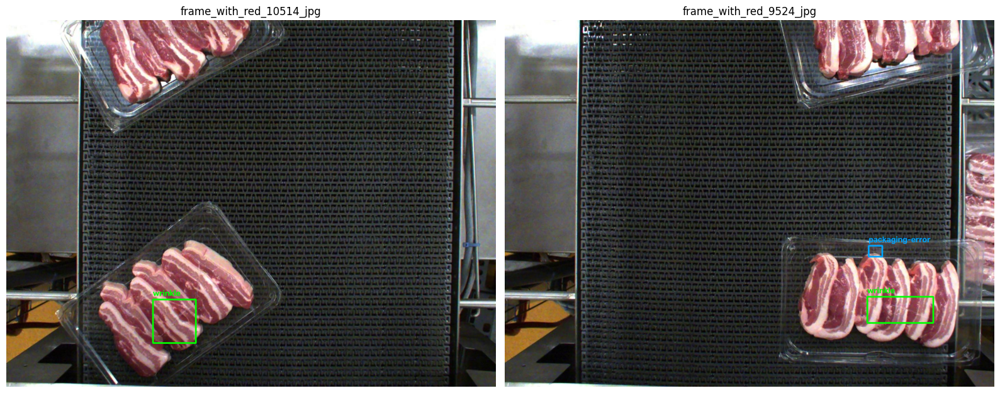


STEP 75C COMPLETE


In [45]:
# STEP 75C — VISUAL VERIFICATION OF REPAIRED ANNOTATIONS

import os
import glob
import cv2
import matplotlib.pyplot as plt

print("STEP 75C — VISUAL VERIFICATION")
print("=" * 60)

dataset = "/content/meat_dataset_verified"

target_frames = [
    "frame_with_red_10514_jpg",
    "frame_with_red_9524_jpg"
]

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, frame in zip(axes, target_frames):

    image_matches = glob.glob(
        f"{dataset}/train/images/{frame}*"
    )

    if not image_matches:
        ax.set_title(f"{frame}: IMAGE NOT FOUND")
        ax.axis("off")
        continue

    image_path = image_matches[0]

    label_path = os.path.join(
        dataset,
        "train",
        "labels",
        os.path.splitext(os.path.basename(image_path))[0] + ".txt"
    )

    image = cv2.imread(image_path)

    if image is None:
        ax.set_title(f"{frame}: CANNOT READ IMAGE")
        ax.axis("off")
        continue

    height, width = image.shape[:2]

    with open(label_path, "r") as f:
        annotations = f.readlines()

    for line in annotations:

        values = list(map(float, line.strip().split()))

        class_id = int(values[0])
        x, y, w, h = values[1:]

        x1 = int((x - w / 2) * width)
        y1 = int((y - h / 2) * height)

        x2 = int((x + w / 2) * width)
        y2 = int((y + h / 2) * height)

        color = (0, 255, 0) if class_id == 4 else (255, 165, 0)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            color,
            3
        )

        cv2.putText(
            image,
            class_names[class_id],
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            color,
            2
        )

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(frame)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nSTEP 75C COMPLETE")

In [46]:
# STEP 76 — DATASET CLASS DISTRIBUTION

import os
from collections import Counter

print("STEP 76 — DATASET CLASS DISTRIBUTION")
print("=" * 65)

dataset = "/content/meat_dataset_verified"

classes = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

results = {}

for split in ["train", "valid", "test"]:

    label_dir = os.path.join(dataset, split, "labels")

    counts = Counter()

    for filename in os.listdir(label_dir):

        if not filename.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, filename)) as f:

            for line in f:

                values = line.strip().split()

                if len(values) == 5:
                    class_id = int(values[0])
                    counts[class_id] += 1

    results[split] = counts

print(f"{'CLASS':<20} {'TRAIN':>10} {'VALID':>10} {'TEST':>10}")
print("-" * 65)

for class_id, name in enumerate(classes):

    print(
        f"{name:<20} "
        f"{results['train'][class_id]:>10} "
        f"{results['valid'][class_id]:>10} "
        f"{results['test'][class_id]:>10}"
    )

print("\nCLASSES MISSING FROM VALIDATION OR TEST")
print("-" * 65)

for class_id, name in enumerate(classes):

    if results["valid"][class_id] == 0:
        print(f"WARNING: {name} missing from validation")

    if results["test"][class_id] == 0:
        print(f"WARNING: {name} missing from test")

print("\nSTEP 76 COMPLETE")

STEP 76 — DATASET CLASS DISTRIBUTION
CLASS                     TRAIN      VALID       TEST
-----------------------------------------------------------------
loose-meat                  127          5          3
packaging-error            1372         45         29
twisted-meat                236          5          7
unsealed                    479         88         52
wrinkle                      18          0          0

CLASSES MISSING FROM VALIDATION OR TEST
-----------------------------------------------------------------

STEP 76 COMPLETE


In [47]:
# STEP 77 — INVESTIGATING WRINKLE IMAGE DISTRIBUTION

import os
import re
from collections import defaultdict

print("STEP 77 — WRINKLE IMAGE INVESTIGATION")
print("=" * 65)

dataset = "/content/meat_dataset_verified"

wrinkle_images = []

label_dir = os.path.join(dataset, "train", "labels")

for filename in sorted(os.listdir(label_dir)):

    if not filename.endswith(".txt"):
        continue

    label_path = os.path.join(label_dir, filename)

    with open(label_path, "r") as f:
        lines = f.readlines()

    wrinkle_count = sum(
        1
        for line in lines
        if line.strip().split()
        and line.strip().split()[0] == "4"
    )

    if wrinkle_count > 0:

        match = re.search(
            r"frame_with_red_(\d+)_jpg",
            filename
        )

        frame_number = (
            int(match.group(1))
            if match else None
        )

        wrinkle_images.append({
            "frame": frame_number,
            "filename": filename,
            "annotations": wrinkle_count
        })

wrinkle_images.sort(
    key=lambda x: (
        x["frame"] is None,
        x["frame"] if x["frame"] is not None else 0
    )
)

print("\nWRINKLE IMAGES")
print("-" * 65)

for item in wrinkle_images:

    print(
        f"Frame: {str(item['frame']):>6} | "
        f"Wrinkle annotations: {item['annotations']}"
    )

print("\nSUMMARY")
print("-" * 65)

print("Images containing wrinkles:", len(wrinkle_images))

print(
    "Total wrinkle annotations:",
    sum(x["annotations"] for x in wrinkle_images)
)

frames = [
    x["frame"]
    for x in wrinkle_images
    if x["frame"] is not None
]

print("Unique frame numbers:", len(set(frames)))

print("\nGAPS BETWEEN CONSECUTIVE WRINKLE FRAMES")
print("-" * 65)

unique_frames = sorted(set(frames))

for previous, current in zip(
    unique_frames[:-1],
    unique_frames[1:]
):
    print(
        f"{previous} → {current} | "
        f"Gap: {current - previous}"
    )

print("\nSTEP 77 COMPLETE")

STEP 77 — WRINKLE IMAGE INVESTIGATION

WRINKLE IMAGES
-----------------------------------------------------------------
Frame:   5760 | Wrinkle annotations: 1
Frame:   7808 | Wrinkle annotations: 1
Frame:   8644 | Wrinkle annotations: 1
Frame:   9524 | Wrinkle annotations: 1
Frame:  10221 | Wrinkle annotations: 1
Frame:  10262 | Wrinkle annotations: 1
Frame:  10305 | Wrinkle annotations: 1
Frame:  10369 | Wrinkle annotations: 1
Frame:  10403 | Wrinkle annotations: 1
Frame:  10412 | Wrinkle annotations: 1
Frame:  10436 | Wrinkle annotations: 1
Frame:  10459 | Wrinkle annotations: 1
Frame:  10465 | Wrinkle annotations: 1
Frame:  10498 | Wrinkle annotations: 1
Frame:  10500 | Wrinkle annotations: 1
Frame:  10514 | Wrinkle annotations: 1
Frame:  10532 | Wrinkle annotations: 1
Frame:  10552 | Wrinkle annotations: 1

SUMMARY
-----------------------------------------------------------------
Images containing wrinkles: 18
Total wrinkle annotations: 18
Unique frame numbers: 18

GAPS BETWEEN CON

STEP 78 — WRINKLE EXAMPLE INSPECTION


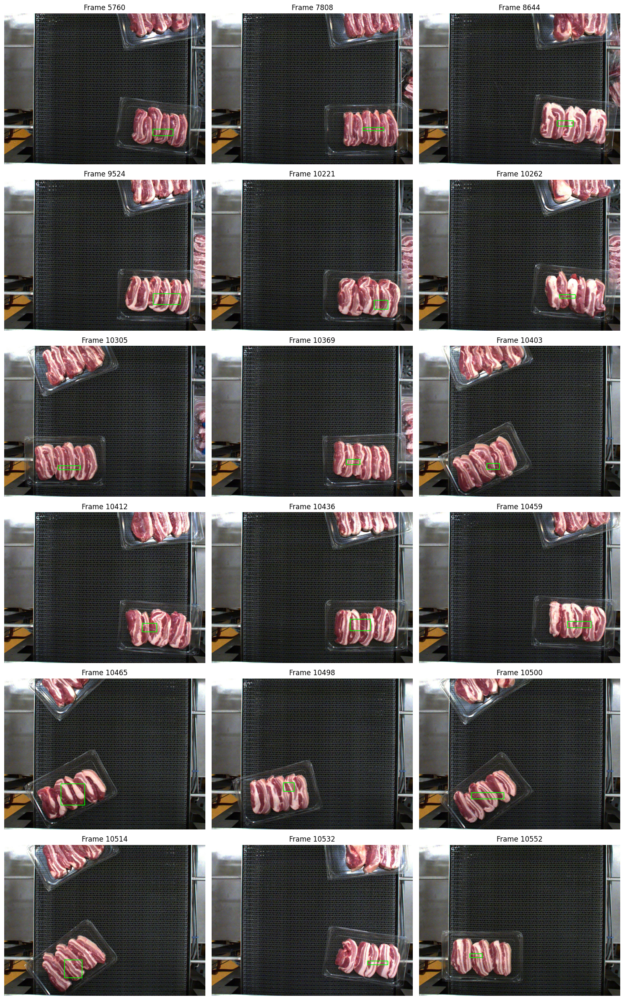


Total wrinkle images displayed: 18
STEP 78 COMPLETE


In [48]:
# STEP 78 — VISUAL INSPECTION OF WRINKLE EXAMPLES

import os
import re
import glob
import cv2
import matplotlib.pyplot as plt

print("STEP 78 — WRINKLE EXAMPLE INSPECTION")
print("=" * 65)

dataset = "/content/meat_dataset_verified"

label_dir = os.path.join(dataset, "train", "labels")
image_dir = os.path.join(dataset, "train", "images")

wrinkle_examples = []

for label_path in glob.glob(os.path.join(label_dir, "*.txt")):

    with open(label_path, "r") as f:
        lines = f.readlines()

    wrinkle_boxes = []

    for line in lines:

        values = line.strip().split()

        if len(values) == 5 and int(values[0]) == 4:
            wrinkle_boxes.append(list(map(float, values[1:])))

    if not wrinkle_boxes:
        continue

    stem = os.path.splitext(os.path.basename(label_path))[0]

    image_path = None

    for extension in [".jpg", ".jpeg", ".png"]:
        candidate = os.path.join(image_dir, stem + extension)

        if os.path.exists(candidate):
            image_path = candidate
            break

    if image_path is None:
        continue

    match = re.search(r"frame_with_red_(\d+)_jpg", stem)

    frame = int(match.group(1)) if match else -1

    wrinkle_examples.append((frame, image_path, wrinkle_boxes))

wrinkle_examples.sort(key=lambda x: x[0])

fig, axes = plt.subplots(6, 3, figsize=(15, 24))

for ax in axes.flat:
    ax.axis("off")

for ax, (frame, image_path, boxes) in zip(
    axes.flat, wrinkle_examples
):

    image = cv2.imread(image_path)

    if image is None:
        continue

    height, width = image.shape[:2]

    for x, y, w, h in boxes:

        x1 = int((x - w / 2) * width)
        y1 = int((y - h / 2) * height)

        x2 = int((x + w / 2) * width)
        y2 = int((y + h / 2) * height)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            4
        )

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(f"Frame {frame}", fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nTotal wrinkle images displayed:", len(wrinkle_examples))
print("STEP 78 COMPLETE")

In [49]:
# STEP 79 — YOLO11N TRAINING READINESS

import os
import torch
import yaml
import ultralytics

print("STEP 79 — YOLO11N TRAINING READINESS")
print("=" * 65)

dataset = "/content/meat_dataset_verified"

# Check dataset directories
for split in ["train", "valid", "test"]:

    image_dir = os.path.join(dataset, split, "images")
    label_dir = os.path.join(dataset, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    print(
        f"{split.upper():<6} | "
        f"Images: {len(images):<5} | "
        f"Labels: {len(labels)}"
    )

# Check configuration
yaml_path = os.path.join(dataset, "data.yaml")

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print("\nDATASET CONFIGURATION")
print("-" * 65)

print("Classes:", config.get("nc"))
print("Names:", config.get("names"))

# Check GPU
print("\nGPU")
print("-" * 65)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Check Ultralytics
print("\nULTRALYTICS")
print("-" * 65)

print("Version:", ultralytics.__version__)

print("\nSTEP 79 COMPLETE")

STEP 79 — YOLO11N TRAINING READINESS
TRAIN  | Images: 1764  | Labels: 1764
VALID  | Images: 115   | Labels: 115
TEST   | Images: 76    | Labels: 76

DATASET CONFIGURATION
-----------------------------------------------------------------
Classes: 5
Names: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']

GPU
-----------------------------------------------------------------
CUDA available: True
GPU: Tesla T4

ULTRALYTICS
-----------------------------------------------------------------
Version: 8.4.193

STEP 79 COMPLETE


In [1]:
# STEP 80 — TRAINING YOLO11N

import os
import yaml
from ultralytics import YOLO

print("STEP 80 — YOLO11N TRAINING")
print("=" * 65)

dataset = "/content/meat_dataset_verified"

drive_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

os.makedirs(drive_folder, exist_ok=True)

# Create a separate configuration for this training run
training_yaml = os.path.join(
    drive_folder,
    "yolo11n_verified_dataset.yaml"
)

config = {
    "path": dataset,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": [
        "loose-meat",
        "packaging-error",
        "twisted-meat",
        "unsealed",
        "wrinkle"
    ]
}

with open(training_yaml, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Dataset configuration saved.")
print("Loading pretrained YOLO11n...")

model = YOLO("yolo11n.pt")

print("\nStarting training...")
print("Training results will be saved to Google Drive.")

results = model.train(
    data=training_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    patience=15,
    project=drive_folder,
    name="yolo11n_verified_training",
    exist_ok=False,
    seed=42,
    plots=True,
    save=True
)

print("\n" + "=" * 65)
print("STEP 80 — TRAINING COMPLETE")
print("=" * 65)

print("Training results:", model.trainer.save_dir)
print("Best model:", model.trainer.best)
print("Last model:", model.trainer.last)

STEP 80 — YOLO11N TRAINING
Dataset configuration saved.
Loading pretrained YOLO11n...

Starting training...
Training results will be saved to Google Drive.
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/yolo11n_verified_dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_wi

In [2]:
# STEP 81 — YOLO11N TEST DATASET EVALUATION

import os
from ultralytics import YOLO

print("STEP 81 — YOLO11N TEST EVALUATION")
print("=" * 65)

# Google Drive folder
drive_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

# Best trained YOLO11n model
model_path = os.path.join(
    drive_folder,
    "yolo11n_verified_training-2",
    "weights",
    "best.pt"
)

# Dataset configuration
dataset_yaml = os.path.join(
    drive_folder,
    "yolo11n_verified_dataset.yaml"
)

# Verify files
print("\nMODEL VERIFICATION")
print("-" * 65)

print("Best model exists:", os.path.exists(model_path))
print("Dataset YAML exists:", os.path.exists(dataset_yaml))

if not os.path.exists(model_path):
    raise FileNotFoundError(model_path)

if not os.path.exists(dataset_yaml):
    raise FileNotFoundError(dataset_yaml)

# Load trained model
print("\nLoading trained YOLO11n...")

model = YOLO(model_path)

# Evaluate on test dataset
print("\nRunning evaluation on 76 test images...")

metrics = model.val(
    data=dataset_yaml,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.7,
    plots=True,
    project=drive_folder,
    name="yolo11n_verified_test_evaluation",
    exist_ok=False
)

# Overall metrics
print("\n" + "=" * 65)
print("OVERALL TEST PERFORMANCE")
print("=" * 65)

print(f"Precision:  {metrics.box.mp:.4f}")
print(f"Recall:     {metrics.box.mr:.4f}")
print(f"mAP50:      {metrics.box.map50:.4f}")
print(f"mAP50-95:   {metrics.box.map:.4f}")

# Per-class metrics
print("\nPER-CLASS PERFORMANCE")
print("-" * 65)

class_names = model.names

for class_id, class_name in class_names.items():

    if class_id in metrics.box.ap_class_index:
        idx = list(metrics.box.ap_class_index).index(class_id)

        precision = metrics.box.p[idx]
        recall = metrics.box.r[idx]
        map50 = metrics.box.ap50[idx]
        map5095 = metrics.box.ap[idx]

        print(f"\n{class_name}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Recall:    {recall:.4f}")
        print(f"  mAP50:     {map50:.4f}")
        print(f"  mAP50-95:  {map5095:.4f}")

    else:
        print(f"\n{class_name}")
        print("  No ground-truth instances in test dataset.")

print("\n" + "=" * 65)
print("STEP 81 COMPLETE")
print("=" * 65)

STEP 81 — YOLO11N TEST EVALUATION

MODEL VERIFICATION
-----------------------------------------------------------------
Best model exists: True
Dataset YAML exists: True

Loading trained YOLO11n...

Running evaluation on 76 test images...
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3229.3±691.4 MB/s, size: 235.2 KB)
val: Scanning /content/meat_dataset_verified/test/labels... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 1.6Kit/s 0.0s
val: New cache created: /content/meat_dataset_verified/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.2it/s 4.2s
                   all         76         91      0.491      0.587      0.565      0.258
            loose-meat          2          3      0.668      0.667      0.863      0.37

In [3]:
# STEP 82 — LOCATING YOLO11N TEST EVALUATION

import os
import glob

print("STEP 82 — YOLO11N EVALUATION FILES")
print("=" * 65)

drive_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

# Find YOLO11n evaluation folders
folders = sorted(glob.glob(
    os.path.join(
        drive_folder,
        "yolo11n_verified_test_evaluation*"
    )
))

print("\nEVALUATION FOLDERS")
print("-" * 65)

for folder in folders:

    if os.path.isdir(folder):

        print("\nFolder:", folder)

        files = os.listdir(folder)

        print("Total files:", len(files))

        for filename in sorted(files):
            print(" -", filename)

print("\nMODEL WEIGHTS")
print("-" * 65)

model_path = os.path.join(
    drive_folder,
    "yolo11n_verified_training-2",
    "weights",
    "best.pt"
)

print("Best model exists:", os.path.exists(model_path))

print("\nSTEP 82 COMPLETE")

STEP 82 — YOLO11N EVALUATION FILES

EVALUATION FOLDERS
-----------------------------------------------------------------

Folder: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/yolo11n_verified_test_evaluation
Total files: 12
 - BoxF1_curve.png
 - BoxPR_curve.png
 - BoxP_curve.png
 - BoxR_curve.png
 - confusion_matrix.png
 - confusion_matrix_normalized.png
 - val_batch0_labels.jpg
 - val_batch0_pred.jpg
 - val_batch1_labels.jpg
 - val_batch1_pred.jpg
 - val_batch2_labels.jpg
 - val_batch2_pred.jpg

MODEL WEIGHTS
-----------------------------------------------------------------
Best model exists: True

STEP 82 COMPLETE


In [4]:
# STEP 83 — GENERATING YOLO11N TEST PREDICTIONS

import os
import glob
import json
import cv2

from ultralytics import YOLO

print("STEP 83 — YOLO11N TEST PREDICTIONS")
print("=" * 65)

drive_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

model_path = os.path.join(
    drive_folder,
    "yolo11n_verified_training-2",
    "weights",
    "best.pt"
)

test_images = (
    "/content/meat_dataset_verified/test/images"
)

output_folder = os.path.join(
    drive_folder,
    "yolo11n_test_predictions"
)

os.makedirs(output_folder, exist_ok=True)

# Verify paths
assert os.path.isfile(model_path), "YOLO11n model not found."
assert os.path.isdir(test_images), "Test images folder not found."

# Load trained model
model = YOLO(model_path)

# Find all test images
image_paths = sorted(
    p for p in glob.glob(os.path.join(test_images, "*"))
    if p.lower().endswith((".jpg", ".jpeg", ".png"))
)

print("Test images found:", len(image_paths))
assert len(image_paths) == 76, "Expected 76 test images."

# Run inference
print("\nRunning YOLO11n inference...")

successful = 0
failed = 0
total_detections = 0

for i, image_path in enumerate(image_paths, 1):

    filename = os.path.basename(image_path)
    output_path = os.path.join(
        output_folder,
        os.path.splitext(filename)[0] + ".json"
    )

    try:
        results = model.predict(
            source=image_path,
            imgsz=640,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=0,
            verbose=False
        )

        result = results[0]

        height, width = result.orig_shape

        predictions = []

        for box in result.boxes:

            x1, y1, x2, y2 = (
                box.xyxy[0].cpu().numpy().tolist()
            )

            class_id = int(box.cls[0].item())
            confidence = float(box.conf[0].item())

            predictions.append({
                "x": (x1 + x2) / 2,
                "y": (y1 + y2) / 2,
                "width": x2 - x1,
                "height": y2 - y1,
                "confidence": confidence,
                "class_id": class_id,
                "class": model.names[class_id]
            })

        output = {
            "image": {
                "width": width,
                "height": height
            },
            "predictions": predictions
        }

        with open(output_path, "w") as f:
            json.dump(output, f, indent=2)

        successful += 1
        total_detections += len(predictions)

        print(
            f"[{i}/{len(image_paths)}] PASS: "
            f"{filename} | Detections: {len(predictions)}"
        )

    except Exception as e:
        failed += 1
        print(f"[{i}/{len(image_paths)}] ERROR: {e}")

print("\n" + "=" * 65)
print("PREDICTION SUMMARY")
print("=" * 65)

print("Total test images:", len(image_paths))
print("Successful:", successful)
print("Failed:", failed)
print("Total detections:", total_detections)
print("Output folder:", output_folder)

print("\nSTEP 83 COMPLETE")

STEP 83 — YOLO11N TEST PREDICTIONS
Test images found: 76

Running YOLO11n inference...
[1/76] PASS: frame_with_red_102_jpg.rf.a64b5717c7e38c8d300c1fc9350ffb7a.jpg | Detections: 6
[2/76] PASS: frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.jpg | Detections: 5
[3/76] PASS: frame_with_red_1271_jpg.rf.73791f248e4a290b4f94dec822ce6ca7.jpg | Detections: 5
[4/76] PASS: frame_with_red_1298_jpg.rf.5e67f735fd446e1d9533abb785d1d209.jpg | Detections: 15
[5/76] PASS: frame_with_red_1405_jpg.rf.4936b698a957f9e625f7e8f59881e6f7.jpg | Detections: 5
[6/76] PASS: frame_with_red_1427_jpg.rf.c0d992d9986ffe41af8d83dd69438aef.jpg | Detections: 5
[7/76] PASS: frame_with_red_1458_jpg.rf.e20e1b5b5f3135bf07d43b17fe48d731.jpg | Detections: 18
[8/76] PASS: frame_with_red_1521_jpg.rf.d00700159daf8ad4df9dd2e9414d2616.jpg | Detections: 3
[9/76] PASS: frame_with_red_161_jpg.rf.56608f17123759b1243b8c79b39ef254.jpg | Detections: 55
[10/76] PASS: frame_with_red_1695_jpg.rf.863a3e2ad41527e901b8f4f3ce700315.jp

In [5]:
# STEP 84 — YOLO11N VS RF-DETR PERFORMANCE COMPARISON

import os
import glob
import json
import cv2
import pandas as pd

print("STEP 84 — MODEL PERFORMANCE COMPARISON")
print("=" * 70)

drive_folder = (
    "/content/drive/MyDrive/"
    "MMA3001_Frozen_Meat_Quality"
)

dataset = "/content/meat_dataset_verified"

yolo_folder = os.path.join(
    drive_folder,
    "yolo11n_test_predictions"
)

rf_folder = os.path.join(
    drive_folder,
    "rf_detr_conf025_predictions"
)

# Locate RF-DETR predictions using the saved folder structure
rf_candidates = []

for root, dirs, files in os.walk(drive_folder):
    json_files = [
        f for f in files if f.lower().endswith(".json")
    ]

    if len(json_files) == 76 and "rf_detr" in root.lower():
        rf_candidates.append(root)

if not os.path.isdir(rf_folder):
    preferred = [
        p for p in rf_candidates
        if "conf025" in p.lower()
    ]

    if preferred:
        rf_folder = preferred[0]

print("YOLO11n folder:", yolo_folder)
print("RF-DETR folder:", rf_folder)

assert os.path.isdir(yolo_folder), "YOLO predictions missing."
assert os.path.isdir(rf_folder), "RF-DETR predictions missing."

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(
        0, box1[3] - box1[1]
    )

    area2 = max(0, box2[2] - box2[0]) * max(
        0, box2[3] - box2[1]
    )

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def xywh_to_xyxy(x, y, w, h):
    return [
        x - w / 2,
        y - h / 2,
        x + w / 2,
        y + h / 2
    ]


def load_ground_truth(image_path):
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(image_path)

    height, width = image.shape[:2]

    label_path = os.path.join(
        dataset,
        "test",
        "labels",
        os.path.splitext(os.path.basename(image_path))[0] + ".txt"
    )

    ground_truth = []

    if not os.path.exists(label_path):
        raise FileNotFoundError(label_path)

    with open(label_path) as f:
        for line in f:
            values = line.strip().split()

            if len(values) != 5:
                raise ValueError(f"Invalid annotation: {label_path}")

            cls = int(values[0])
            x, y, w, h = map(float, values[1:])

            ground_truth.append({
                "class_id": cls,
                "box": xywh_to_xyxy(
                    x * width,
                    y * height,
                    w * width,
                    h * height
                )
            })

    return ground_truth


def load_predictions(folder, filename, threshold):
    json_path = os.path.join(
        folder,
        os.path.splitext(filename)[0] + ".json"
    )

    if not os.path.exists(json_path):
        raise FileNotFoundError(json_path)

    with open(json_path) as f:
        data = json.load(f)

    # Support both direct and wrapped prediction formats
    if isinstance(data, list):
        data = data[0]

    if "predictions" in data and isinstance(
        data["predictions"], dict
    ):
        data = data["predictions"]

    detections = data["predictions"]

    output = []

    for p in detections:
        confidence = float(p["confidence"])

        if confidence < threshold:
            continue

        output.append({
            "class_id": int(p["class_id"]),
            "confidence": confidence,
            "box": xywh_to_xyxy(
                float(p["x"]),
                float(p["y"]),
                float(p["width"]),
                float(p["height"])
            )
        })

    return output


def evaluate_model(folder, threshold):
    tp = fp = fn = 0

    image_paths = sorted(
        glob.glob(
            os.path.join(dataset, "test", "images", "*.jpg")
        )
    )

    assert len(image_paths) == 76, (
        f"Expected 76 images, found {len(image_paths)}"
    )

    for image_path in image_paths:
        filename = os.path.basename(image_path)

        gt = load_ground_truth(image_path)

        preds = load_predictions(
            folder,
            filename,
            threshold
        )

        # Confidence-ordered, class-aware one-to-one matching
        preds.sort(
            key=lambda p: p["confidence"],
            reverse=True
        )

        matched_gt = set()

        for pred in preds:
            best_iou = 0
            best_index = -1

            for j, target in enumerate(gt):
                if j in matched_gt:
                    continue

                if pred["class_id"] != target["class_id"]:
                    continue

                iou = calculate_iou(
                    pred["box"],
                    target["box"]
                )

                if iou > best_iou:
                    best_iou = iou
                    best_index = j

            if best_iou >= 0.50 and best_index >= 0:
                tp += 1
                matched_gt.add(best_index)
            else:
                fp += 1

        fn += len(gt) - len(matched_gt)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4)
    }


results = []

for threshold in [0.25, 0.40]:
    for name, folder in [
        ("YOLO11n", yolo_folder),
        ("RF-DETR", rf_folder)
    ]:
        metrics = evaluate_model(folder, threshold)

        results.append({
            "Model": name,
            "Confidence": threshold,
            **metrics
        })

comparison = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print("-" * 70)
print(comparison.to_string(index=False))

output_csv = os.path.join(
    drive_folder,
    "yolo11n_vs_rf_detr_comparison.csv"
)

comparison.to_csv(output_csv, index=False)

print("\nComparison saved:", output_csv)
print("\nSTEP 84 COMPLETE")

STEP 84 — MODEL PERFORMANCE COMPARISON
YOLO11n folder: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/yolo11n_test_predictions
RF-DETR folder: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/rf_detr_conf025_predictions

MODEL COMPARISON
----------------------------------------------------------------------
  Model  Confidence  TP  FP  FN  Precision  Recall     F1
YOLO11n        0.25  53  36  38     0.5955  0.5824 0.5889
RF-DETR        0.25  65  70  26     0.4815  0.7143 0.5752
YOLO11n        0.40  44  18  47     0.7097  0.4835 0.5752
RF-DETR        0.40  50  21  41     0.7042  0.5495 0.6173

Comparison saved: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/yolo11n_vs_rf_detr_comparison.csv

STEP 84 COMPLETE


In [6]:
# STEP 85 — PER-CLASS MODEL COMPARISON

import pandas as pd
import os
import glob

print("STEP 85 — PER-CLASS MODEL COMPARISON")
print("=" * 75)

confidence_threshold = 0.40
iou_threshold = 0.50

models = {
    "YOLO11n": yolo_folder,
    "RF-DETR": rf_folder
}

class_results = []

image_paths = sorted(
    glob.glob(
        os.path.join(dataset, "test", "images", "*.jpg")
    )
)

for model_name, prediction_folder in models.items():

    for class_id, class_name in enumerate(class_names):

        tp = 0
        fp = 0
        fn = 0
        gt_count = 0

        for image_path in image_paths:

            filename = os.path.basename(image_path)

            ground_truth = [
                item
                for item in load_ground_truth(image_path)
                if item["class_id"] == class_id
            ]

            predictions = [
                item
                for item in load_predictions(
                    prediction_folder,
                    filename,
                    confidence_threshold
                )
                if item["class_id"] == class_id
            ]

            gt_count += len(ground_truth)

            predictions.sort(
                key=lambda x: x["confidence"],
                reverse=True
            )

            matched = set()

            for prediction in predictions:

                best_iou = 0
                best_index = -1

                for index, target in enumerate(ground_truth):

                    if index in matched:
                        continue

                    iou = calculate_iou(
                        prediction["box"],
                        target["box"]
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_index = index

                if best_iou >= iou_threshold and best_index >= 0:
                    tp += 1
                    matched.add(best_index)
                else:
                    fp += 1

            fn += len(ground_truth) - len(matched)

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        class_results.append({
            "Model": model_name,
            "Class": class_name,
            "GT": gt_count,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1": round(f1, 4) if gt_count else None
        })

results_df = pd.DataFrame(class_results)

print("\nCONFIDENCE THRESHOLD:", confidence_threshold)
print("IOU THRESHOLD:", iou_threshold)

print("\nPER-CLASS PERFORMANCE")
print("-" * 75)

print(results_df.to_string(index=False))

output_path = os.path.join(
    drive_folder,
    "yolo11n_vs_rf_detr_per_class.csv"
)

results_df.to_csv(output_path, index=False)

print("\nResults saved:", output_path)

print("\nNOTE: Classes with zero ground-truth instances")
print("cannot be meaningfully evaluated on this test set.")

print("\nSTEP 85 COMPLETE")

STEP 85 — PER-CLASS MODEL COMPARISON

CONFIDENCE THRESHOLD: 0.4
IOU THRESHOLD: 0.5

PER-CLASS PERFORMANCE
---------------------------------------------------------------------------
  Model           Class  GT  TP  FP  FN  Precision  Recall     F1
YOLO11n      loose-meat   3   2   1   1     0.6667  0.6667 0.6667
YOLO11n packaging-error  29   2   0  27     1.0000  0.0690 0.1290
YOLO11n    twisted-meat   7   4   9   3     0.3077  0.5714 0.4000
YOLO11n        unsealed  52  36   8  16     0.8182  0.6923 0.7500
YOLO11n         wrinkle   0   0   0   0     0.0000  0.0000    NaN
RF-DETR      loose-meat   3   1   0   2     1.0000  0.3333 0.5000
RF-DETR packaging-error  29   5   7  24     0.4167  0.1724 0.2439
RF-DETR    twisted-meat   7   4   6   3     0.4000  0.5714 0.4706
RF-DETR        unsealed  52  40   8  12     0.8333  0.7692 0.8000
RF-DETR         wrinkle   0   0   0   0     0.0000  0.0000    NaN

Results saved: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/yolo11n_vs_rf_detr_per_cl

In [7]:
# STEP 86 — PACKAGING-ERROR CONFIDENCE ANALYSIS

import pandas as pd

print("STEP 86 — PACKAGING-ERROR CONFIDENCE ANALYSIS")
print("=" * 75)

target_class = "packaging-error"

thresholds = [0.25, 0.30, 0.35, 0.40]

comparison = []

for model_name, prediction_folder in models.items():

    for threshold in thresholds:

        tp = 0
        fp = 0
        fn = 0

        for image_path in image_paths:

            filename = os.path.basename(image_path)

            ground_truth = [
                item
                for item in load_ground_truth(image_path)
                if item["class_id"] == 1
            ]

            predictions = [
                item
                for item in load_predictions(
                    prediction_folder,
                    filename,
                    threshold
                )
                if item["class_id"] == 1
            ]

            predictions.sort(
                key=lambda x: x["confidence"],
                reverse=True
            )

            matched = set()

            for prediction in predictions:

                best_iou = 0
                best_index = -1

                for index, target in enumerate(ground_truth):

                    if index in matched:
                        continue

                    iou = calculate_iou(
                        prediction["box"],
                        target["box"]
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_index = index

                if best_iou >= 0.50 and best_index >= 0:
                    tp += 1
                    matched.add(best_index)
                else:
                    fp += 1

            fn += len(ground_truth) - len(matched)

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        comparison.append({
            "Model": model_name,
            "Threshold": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1": round(f1, 4)
        })

comparison_df = pd.DataFrame(comparison)

print("\nPACKAGING-ERROR RESULTS")
print("-" * 75)

print(comparison_df.to_string(index=False))

output_path = os.path.join(
    drive_folder,
    "packaging_error_confidence_analysis.csv"
)

comparison_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("\nSTEP 86 COMPLETE")

STEP 86 — PACKAGING-ERROR CONFIDENCE ANALYSIS

PACKAGING-ERROR RESULTS
---------------------------------------------------------------------------
  Model  Threshold  TP  FP  FN  Precision  Recall     F1
YOLO11n       0.25   6   9  23     0.4000  0.2069 0.2727
YOLO11n       0.30   3   4  26     0.4286  0.1034 0.1667
YOLO11n       0.35   2   2  27     0.5000  0.0690 0.1212
YOLO11n       0.40   2   0  27     1.0000  0.0690 0.1290
RF-DETR       0.25  16  34  13     0.3200  0.5517 0.4051
RF-DETR       0.30  13  18  16     0.4194  0.4483 0.4333
RF-DETR       0.35   8  11  21     0.4211  0.2759 0.3333
RF-DETR       0.40   5   7  24     0.4167  0.1724 0.2439

Saved: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/packaging_error_confidence_analysis.csv

STEP 86 COMPLETE


In [8]:
# STEP 87 — IDENTIFYING MISSED PACKAGING ERRORS

import os
import pandas as pd

print("STEP 87 — IDENTIFYING MISSED PACKAGING ERRORS")
print("=" * 75)

confidence = 0.25
iou_threshold = 0.50
target_class_id = 1  # packaging-error

missed_images = []

for image_path in image_paths:

    filename = os.path.basename(image_path)

    ground_truth = [
        item
        for item in load_ground_truth(image_path)
        if item["class_id"] == target_class_id
    ]

    if not ground_truth:
        continue

    predictions = [
        item
        for item in load_predictions(
            rf_folder,
            filename,
            confidence
        )
        if item["class_id"] == target_class_id
    ]

    predictions.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    matched = set()

    for prediction in predictions:

        best_iou = 0
        best_index = -1

        for index, target in enumerate(ground_truth):

            if index in matched:
                continue

            iou = calculate_iou(
                prediction["box"],
                target["box"]
            )

            if iou > best_iou:
                best_iou = iou
                best_index = index

        if best_iou >= iou_threshold and best_index >= 0:
            matched.add(best_index)

    missed_count = len(ground_truth) - len(matched)

    if missed_count > 0:
        missed_images.append({
            "Image": filename,
            "Ground Truth": len(ground_truth),
            "RF-DETR Predictions": len(predictions),
            "Missed Defects": missed_count
        })

missed_df = pd.DataFrame(missed_images)

print("\nIMAGES WITH MISSED PACKAGING ERRORS")
print("-" * 75)

if not missed_df.empty:
    print(missed_df.to_string(index=False))

    print("\nImages containing missed defects:", len(missed_df))
    print("Total missed defects:", missed_df["Missed Defects"].sum())
else:
    print("No missed packaging errors found.")

print("\nSTEP 87 COMPLETE")

STEP 87 — IDENTIFYING MISSED PACKAGING ERRORS

IMAGES WITH MISSED PACKAGING ERRORS
---------------------------------------------------------------------------
                                                          Image  Ground Truth  RF-DETR Predictions  Missed Defects
 frame_with_red_121_jpg.rf.27e5a7e1340d02281d4bdfc6919f7dc4.jpg             1                    0               1
frame_with_red_1298_jpg.rf.5e67f735fd446e1d9533abb785d1d209.jpg             1                    1               1
frame_with_red_1458_jpg.rf.e20e1b5b5f3135bf07d43b17fe48d731.jpg             1                    2               1
 frame_with_red_199_jpg.rf.5d7f448fe391e31153003ac0fb40abfe.jpg             1                    2               1
  frame_with_red_21_jpg.rf.1be6bc758e844ba8521928a2d7910903.jpg             1                    2               1
 frame_with_red_258_jpg.rf.900fec57f3f2f32f948871201b201f39.jpg             1                    1               1
frame_with_red_3117_jpg.rf.f6090bcaa

STEP 88 — VISUALISING MISSED PACKAGING ERRORS


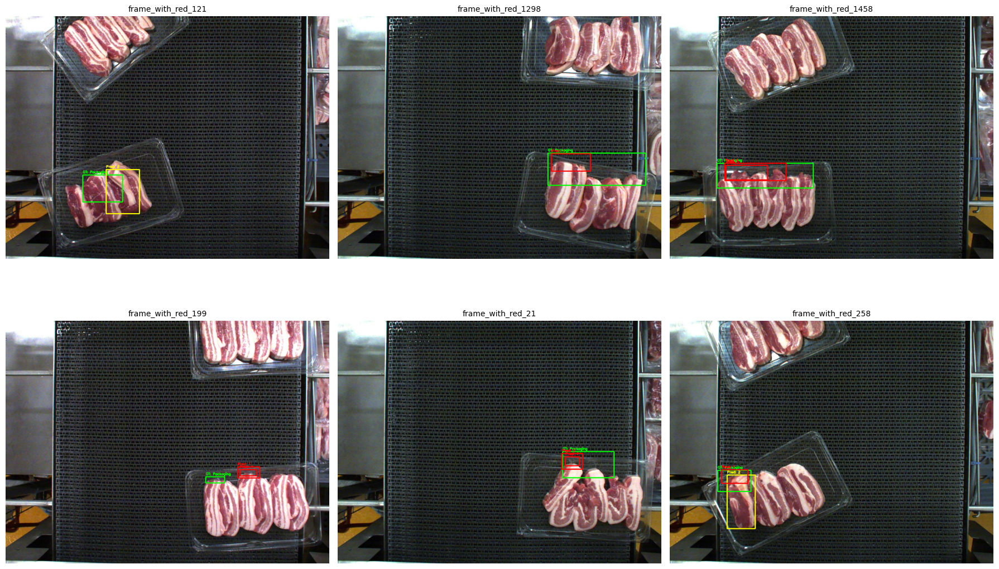


STEP 88 COMPLETE


In [9]:
# STEP 88 — VISUALISING MISSED PACKAGING ERRORS

import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

print("STEP 88 — VISUALISING MISSED PACKAGING ERRORS")
print("=" * 70)

# Select the first six problematic images
selected_images = missed_df["Image"].head(6).tolist()

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 12)
)

axes = axes.flatten()

def draw_detection_box(image, box, color, label):

    x1, y1, x2, y2 = map(int, box)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    cv2.putText(
        image,
        label,
        (x1, max(y1 - 8, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        color,
        2
    )

for index, filename in enumerate(selected_images):

    image_path = os.path.join(
        dataset,
        "test",
        "images",
        filename
    )

    image = cv2.imread(image_path)

    if image is None:
        print("Could not load:", filename)
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    ground_truth = load_ground_truth(image_path)

    predictions = load_predictions(
        rf_folder,
        filename,
        0.25
    )

    # Draw ground-truth packaging errors
    for target in ground_truth:

        if target["class_id"] == 1:

            draw_detection_box(
                image,
                target["box"],
                (0, 255, 0),
                "GT: Packaging"
            )

    # Draw RF-DETR predictions
    for prediction in predictions:

        if prediction["class_id"] == 1:

            color = (255, 0, 0)

        else:

            color = (255, 255, 0)

        draw_detection_box(
            image,
            prediction["box"],
            color,
            f'Pred: {prediction["class_id"]}'
        )

    axes[index].imshow(image)

    axes[index].set_title(
        filename.split("_jpg")[0],
        fontsize=10
    )

    axes[index].axis("off")

for index in range(len(selected_images), len(axes)):
    axes[index].axis("off")

plt.tight_layout()
plt.show()

print("\nSTEP 88 COMPLETE")

In [10]:
# STEP 89 — ANALYSING MISSED DETECTION IOU

import os
import pandas as pd

print("STEP 89 — MISSED PACKAGING-ERROR IOU ANALYSIS")
print("=" * 75)

confidence = 0.25
iou_threshold = 0.50

analysis = []

for image_path in image_paths:

    filename = os.path.basename(image_path)

    ground_truth = [
        item
        for item in load_ground_truth(image_path)
        if item["class_id"] == 1
    ]

    if not ground_truth:
        continue

    predictions = [
        item
        for item in load_predictions(
            rf_folder,
            filename,
            confidence
        )
        if item["class_id"] == 1
    ]

    predictions.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    # Match predictions to annotations using the same
    # greedy matching procedure as Step 87.
    matched = set()

    for prediction in predictions:

        best_iou = 0
        best_index = -1

        for index, target in enumerate(ground_truth):

            if index in matched:
                continue

            iou = calculate_iou(
                prediction["box"],
                target["box"]
            )

            if iou > best_iou:
                best_iou = iou
                best_index = index

        if best_iou >= iou_threshold and best_index >= 0:
            matched.add(best_index)

    # Examine only unmatched ground-truth annotations
    for index, target in enumerate(ground_truth):

        if index in matched:
            continue

        highest_iou = max(
            (
                calculate_iou(
                    prediction["box"],
                    target["box"]
                )
                for prediction in predictions
            ),
            default=0
        )

        if not predictions:
            issue = "No same-class prediction"
        elif highest_iou >= 0.30:
            issue = "Partial overlap"
        elif highest_iou > 0:
            issue = "Low overlap"
        else:
            issue = "No overlap"

        analysis.append({
            "Image": filename.split("_jpg")[0],
            "Best IoU": round(highest_iou, 4),
            "Predictions": len(predictions),
            "Issue": issue
        })

analysis_df = pd.DataFrame(analysis)

print("\nMISSED PACKAGING-ERROR ANALYSIS")
print("-" * 75)

print(analysis_df.to_string(index=False))

print("\nISSUE DISTRIBUTION")
print("-" * 75)

print(analysis_df["Issue"].value_counts())

print("\nTOTAL MISSED DEFECTS:", len(analysis_df))

output_path = os.path.join(
    drive_folder,
    "packaging_error_missed_iou_analysis.csv"
)

analysis_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

print("\nSTEP 89 COMPLETE")

STEP 89 — MISSED PACKAGING-ERROR IOU ANALYSIS

MISSED PACKAGING-ERROR ANALYSIS
---------------------------------------------------------------------------
              Image  Best IoU  Predictions                    Issue
 frame_with_red_121    0.0000            0 No same-class prediction
frame_with_red_1298    0.2143            1              Low overlap
frame_with_red_1458    0.4428            2          Partial overlap
 frame_with_red_199    0.0000            2               No overlap
  frame_with_red_21    0.2316            2              Low overlap
 frame_with_red_258    0.4679            1          Partial overlap
frame_with_red_3117    0.0000            1               No overlap
frame_with_red_4027    0.4767            3          Partial overlap
frame_with_red_4027    0.2183            3              Low overlap
frame_with_red_4027    0.4344            3          Partial overlap
  frame_with_red_62    0.3675            1          Partial overlap
frame_with_red_7073    0.4494

In [11]:
# STEP 90 — PACKAGING-ERROR IOU SENSITIVITY

import os
import pandas as pd

print("STEP 90 — PACKAGING-ERROR IOU SENSITIVITY")
print("=" * 75)

confidence_threshold = 0.25
iou_thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in iou_thresholds:

    TP = 0
    FP = 0
    FN = 0

    for image_path in image_paths:

        filename = os.path.basename(image_path)

        ground_truth = [
            item
            for item in load_ground_truth(image_path)
            if item["class_id"] == 1
        ]

        predictions = [
            item
            for item in load_predictions(
                rf_folder,
                filename,
                confidence_threshold
            )
            if item["class_id"] == 1
        ]

        predictions.sort(
            key=lambda x: x["confidence"],
            reverse=True
        )

        matched = set()

        for prediction in predictions:

            best_iou = 0
            best_index = -1

            for index, target in enumerate(ground_truth):

                if index in matched:
                    continue

                iou = calculate_iou(
                    prediction["box"],
                    target["box"]
                )

                if iou > best_iou:
                    best_iou = iou
                    best_index = index

            if best_iou >= threshold and best_index >= 0:
                TP += 1
                matched.add(best_index)
            else:
                FP += 1

        FN += len(ground_truth) - len(matched)

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "IoU": threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4)
    })

results_df = pd.DataFrame(results)

print("\nPACKAGING-ERROR RESULTS")
print("-" * 75)
print(results_df.to_string(index=False))

output_path = os.path.join(
    drive_folder,
    "packaging_error_iou_sensitivity.csv"
)

results_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("\nSTEP 90 COMPLETE")

STEP 90 — PACKAGING-ERROR IOU SENSITIVITY

PACKAGING-ERROR RESULTS
---------------------------------------------------------------------------
 IoU  TP  FP  FN  Precision  Recall     F1
 0.3  23  27   6       0.46  0.7931 0.5823
 0.4  22  28   7       0.44  0.7586 0.5570
 0.5  16  34  13       0.32  0.5517 0.4051
 0.6  11  39  18       0.22  0.3793 0.2785
 0.7   4  46  25       0.08  0.1379 0.1013

Saved: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/packaging_error_iou_sensitivity.csv

STEP 90 COMPLETE


In [12]:
# STEP 91 — PACKAGING-ERROR BOX SIZE ANALYSIS

import os
import numpy as np
import pandas as pd

print("STEP 91 — PACKAGING-ERROR BOX SIZE ANALYSIS")
print("=" * 70)

records = []

for image_path in image_paths:

    filename = os.path.basename(image_path)

    ground_truth = [
        item for item in load_ground_truth(image_path)
        if item["class_id"] == 1
    ]

    predictions = [
        item for item in load_predictions(
            rf_folder, filename, 0.25
        )
        if item["class_id"] == 1
    ]

    for gt in ground_truth:

        if not predictions:
            continue

        best_prediction = max(
            predictions,
            key=lambda p: calculate_iou(
                gt["box"], p["box"]
            )
        )

        iou = calculate_iou(
            gt["box"],
            best_prediction["box"]
        )

        if iou <= 0:
            continue

        gx1, gy1, gx2, gy2 = gt["box"]
        px1, py1, px2, py2 = best_prediction["box"]

        gt_width = gx2 - gx1
        gt_height = gy2 - gy1

        pred_width = px2 - px1
        pred_height = py2 - py1

        if gt_width <= 0 or gt_height <= 0:
            continue

        records.append({
            "image": filename,
            "IoU": iou,
            "GT_width": gt_width,
            "GT_height": gt_height,
            "Pred_width": pred_width,
            "Pred_height": pred_height,
            "Width_ratio": pred_width / gt_width,
            "Height_ratio": pred_height / gt_height,
            "Area_ratio": (
                (pred_width * pred_height) /
                (gt_width * gt_height)
            )
        })

df = pd.DataFrame(records)

print("\nMATCHED BOX ANALYSIS")
print("-" * 70)

print("Ground-truth boxes with overlapping predictions:", len(df))

if not df.empty:

    print("\nAVERAGE RATIOS")
    print("-" * 70)

    print(
        "Width ratio:",
        round(df["Width_ratio"].median(), 4)
    )

    print(
        "Height ratio:",
        round(df["Height_ratio"].median(), 4)
    )

    print(
        "Area ratio:",
        round(df["Area_ratio"].median(), 4)
    )

    print("\nINTERPRETATION")
    print("-" * 70)

    print("Ratio = 1.0: predicted size matches ground truth")
    print("Ratio > 1.0: predicted box is larger")
    print("Ratio < 1.0: predicted box is smaller")

    output_path = os.path.join(
        drive_folder,
        "packaging_error_box_size_analysis.csv"
    )

    df.to_csv(output_path, index=False)

    print("\nSaved:", output_path)

print("\nSTEP 91 COMPLETE")

STEP 91 — PACKAGING-ERROR BOX SIZE ANALYSIS

MATCHED BOX ANALYSIS
----------------------------------------------------------------------
Ground-truth boxes with overlapping predictions: 26

AVERAGE RATIOS
----------------------------------------------------------------------
Width ratio: 0.9506
Height ratio: 0.9843
Area ratio: 1.0964

INTERPRETATION
----------------------------------------------------------------------
Ratio = 1.0: predicted size matches ground truth
Ratio > 1.0: predicted box is larger
Ratio < 1.0: predicted box is smaller

Saved: /content/drive/MyDrive/MMA3001_Frozen_Meat_Quality/packaging_error_box_size_analysis.csv

STEP 91 COMPLETE


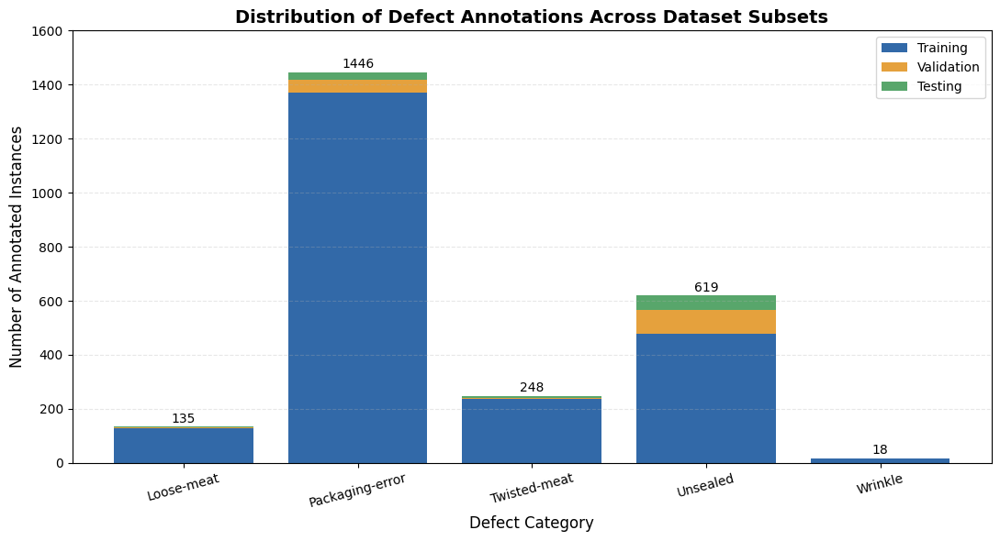

STEP 92 COMPLETE
Figure saved: /content/Figure_3_Class_Distribution.png


In [1]:
# STEP 92 — DATASET CLASS DISTRIBUTION GRAPH

import numpy as np
import matplotlib.pyplot as plt

classes = [
    "Loose-meat",
    "Packaging-error",
    "Twisted-meat",
    "Unsealed",
    "Wrinkle"
]

train = np.array([127, 1372, 236, 479, 18])
valid = np.array([5, 45, 5, 88, 0])
test = np.array([3, 29, 7, 52, 0])

x = np.arange(len(classes))

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(x, train, label="Training", color="#3269A8")
ax.bar(x, valid, bottom=train,
       label="Validation", color="#E5A13D")
ax.bar(x, test, bottom=train + valid,
       label="Testing", color="#58A66B")

ax.set_xlabel("Defect Category", fontsize=12)
ax.set_ylabel("Number of Annotated Instances", fontsize=12)

ax.set_title(
    "Distribution of Defect Annotations Across Dataset Subsets",
    fontsize=14,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=15)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Display total annotations above each bar
totals = train + valid + test

for i, total in enumerate(totals):
    ax.text(i, total + 15, str(total),
            ha="center", fontsize=10)

ax.set_ylim(0, 1600)

plt.tight_layout()

# Save high-resolution figure
output = "/content/Figure_3_Class_Distribution.png"

plt.savefig(output, dpi=300, bbox_inches="tight")

plt.show()

print("STEP 92 COMPLETE")
print("Figure saved:", output)